

---

# Part I — Linear Models and Regularization

Least squares, ridge, and LASSO: closed-form solutions, regularization paths, and the bias that shrinkage buys, on the prostate cancer, MNIST, and USA crime datasets.



## Linear and Ridge Regression on Prostate Cancer Data

**Background**: The data for this example come from a study by Stamey et al. (1989) that examined the correlation between the level of prostate specific antigen (PSA) and a number of clinical measures, in 97 men who were about to receive a radical prostatectomy.
The goal is to predict the log of PSA (lpsa) from a number of measurements.

Variables:

| feature |                  feature description                  |
|---------|-------------------------------------------------------|
|lpsa     |log prostate specific antigen                          |
|lcavol   |log cancer volume                                      |
|lweight  |log prostate weight                                    |
|age      |age                                                    |
|lbph     |log of benign prostatic hyperplasia amount             |
|svi      |seminal vesicle invasion                               |
|lcp      |log of capsular penetration                            |
|gleason  |Gleason score                                          |
|pgg45    |percent of Gleason scores 4 or 5                       |


The following code loads the the prostate cancer data set. You can see there are 8 features and 97 cases. We divide the dataset into two parts: the 67 cases as training set (in Xtrain and ytrain) and the 30 cases as test set (in Xtest and ytest).

In [74]:
# Libraries
import scipy
import random as rand
import pandas as pd
import numpy as np

from scipy.io import loadmat

data = loadmat('data/prostate_stnd.mat')
names = list(map(lambda x: x[0], data['names'][0]))
Xtrain, ytrain = data['Xtrain'], data['ytrain']
Xtest, ytest   = data['Xtest'], data['ytest']
print(names)

[np.str_('lcavol'), np.str_('lweight'), np.str_('age'), np.str_('lbph'), np.str_('svi'), np.str_('lcp'), np.str_('gleason'), np.str_('pgg45'), np.str_('lpsa')]




---


### Linear Regression
The **Coefficient of Determination** is defined as follows,
$$ R^2= 1- \frac{\sum_{n=1}^N(\hat{y}^{(n)}-y^{(n)})^2}{\sum_{n=1}^N(\bar{y}-y^{(n)})^2}$$
where $\bar y = \frac{1}{N}\sum_{n=1}^N y^{(n)}$.

- Please write a function to calculate coefficient of determination.

- Please perform the linear regression with least squares and calculate coefficient of determination.

- Use this model to calculate the MSE (mean squared error) on the test set. Do you think we have the overfitting issue?

In [75]:
# using a linear modeling package to check if my answer is correct
from sklearn.linear_model import LinearRegression
checking = LinearRegression()
checking.fit(Xtrain, ytrain)
print(f"R^2 check using Scikit Learn for regression: {checking.score(Xtrain, ytrain)}")

R^2 check using Scikit Learn for regression: 0.6943711796768238


In [76]:
def qr(X, y):
    # outputs w for linear regression
    Q, R = np.linalg.qr(X)
    Qy = np.dot(Q.T, y)
    return scipy.linalg.solve_triangular(R, Qy)

def add_one(X):
    # returns a matrix with a column of 1's at the beginning of a matrix
    new_X = X.T
    new_X = np.insert(new_X, 0, np.ones((len(X))), 0)
    return new_X.T

def coef_det(X,y,X_test,y_test):
    # returns R^2
    X = add_one(X)
    w = qr(X,y)
    y_hat = X.dot(w)
    y_bar = np.mean(y)
    numerator = 0
    denominator = 0
    for i in range(len(y)):
        # this numerator is RSS
        numerator += (y_hat[i][0]-y[i][0])**2
        # this denominator is TSS
        denominator += (y_bar-y[i][0])**2

    print("OLS Train R²:", 1 - (numerator/denominator))
    
    y_bar_test = np.mean(y_test)
    rss = np.sum((add_one(X_test) @ w - y_test)**2)
    tss = np.sum((y_bar_test - y_test)**2)
    print("OLS Test R²:", 1 - rss/tss)

    # return 1 - (numerator/denominator)

def MSE(X, y, w):
    # returns MSE
    X = add_one(X)
    y_hat = X @ w
    mse = np.square(np.subtract(y_hat, y))
    return sum(mse) / len(mse)

w = qr(add_one(Xtrain), ytrain)
coef_det(Xtrain, ytrain, Xtest, ytest)
print("Train MSE:", MSE(Xtrain, ytrain, w)[0])
print("Test MSE:", MSE(Xtest, ytest, w)[0])

OLS Train R²: 0.6943711796768238
OLS Test R²: 0.4414014941560529
Train MSE: 0.4391997680583344
Test MSE: 0.5863291707988233


In [ ]:
# sklearn check: least squares
from sklearn.linear_model import LinearRegression

r2_score_check = lambda P, t: 1 - np.sum((np.ravel(P)-np.ravel(t))**2)/np.sum((np.mean(t)-np.ravel(t))**2)
check_ols = LinearRegression().fit(Xtrain, ytrain)
w_ols = qr(add_one(Xtrain), ytrain)

print("            %14s %14s" % ("mine", "sklearn"))
print("train R^2   %14.10f %14.10f" % (r2_score_check(add_one(Xtrain) @ w_ols, ytrain), check_ols.score(Xtrain, ytrain)))
print("test  R^2   %14.10f %14.10f" % (r2_score_check(add_one(Xtest) @ w_ols, ytest), check_ols.score(Xtest, ytest)))
print("train MSE   %14.10f %14.10f" % (MSE(Xtrain, ytrain, w_ols)[0], np.mean((np.ravel(check_ols.predict(Xtrain))-np.ravel(ytrain))**2)))
print("test  MSE   %14.10f %14.10f" % (MSE(Xtest, ytest, w_ols)[0], np.mean((np.ravel(check_ols.predict(Xtest))-np.ravel(ytest))**2)))
print("max |coefficient difference|  %.2e" % np.abs(np.ravel(w_ols)[1:] - np.ravel(check_ols.coef_)).max())


                      mine        sklearn
train R^2     0.6943711797   0.6943711797
test  R^2     0.4414014942   0.4414014942
train MSE     0.4391997681   0.4391997681
test  MSE     0.5863291708   0.5863291708
max |coefficient difference|  3.33e-16


With a training MSE of .439 and a testing MSE of .586, we have a testing MSE ~34% higher than the training, which points towards a mild overfitting pattern. However, with so little training points, it's hard to give a conclusion on this matter. If we had a larger data set with more samples with this ratio, we'd be more inclined to say that there is overfitting.




---


### Ridge Regression

- Please perform the Ridge regression with the hold out. Use the MSE on the test data to find the optimal penalty parameter $\lambda^*$.

- Calculate coefficient of determination. Compare with the least square, do you have any improvement?

- Plot *regularization path*, the coefficients $w_i$ as a function of the parameter $1/\lambda$.


In [77]:
# using a linear modeling package to check if my answer is correct
from sklearn.linear_model import Ridge
lamb = 24
checking = Ridge(lamb).fit(Xtrain, ytrain)
#checking.coef_
#checking.intercept_
print(checking.score(Xtrain,ytrain))
print(checking.score(Xtest,ytest))

0.6535776711252945
0.48726098246184246


The Optimal Lambda was found to be: 23.7513250862094
Coefficient of Determination (R^2) for Training: 0.6540252456649842
Coefficient of Determination (R^2) for Testing: 0.48726269504854924


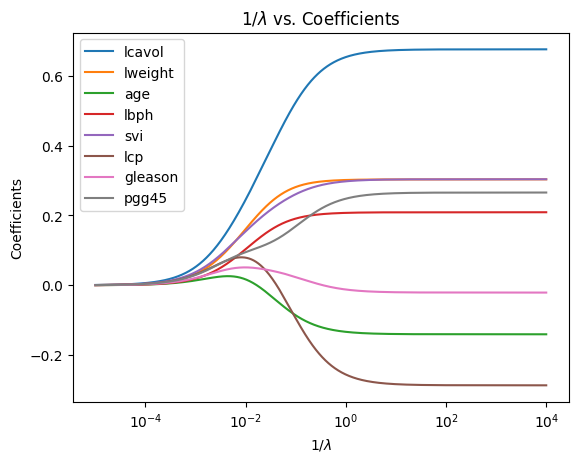

In [78]:
import matplotlib.pyplot as plt

def ridge_solve(X, y, l):
    # solves ridge regression as an augmented least squares problem.
    # the intercept sits in the first column and is left unpenalized
    X = add_one(X)
    D = X.shape[1]
    penalty = np.diag([0.0] + [np.sqrt(l)] * (D-1))
    X_tilde = np.vstack([X, penalty])
    y_tilde = np.concatenate([y.flatten(), np.zeros(D)])
    return np.linalg.lstsq(X_tilde, y_tilde, rcond=None)[0]

def ridge_mse(y_hat, y):
    # returns the mean squared error
    return np.mean((y_hat.flatten() - y.flatten())**2)

def ridge_path(X_train, y_train, X_test, y_test, low=1e-4, high=1e5, num=2000):
    # evaluates a geometric grid of lambdas, returning the grid itself, the
    # coefficients fit at each lambda, and the test MSE at each lambda
    lambdas = np.logspace(np.log10(low), np.log10(high), num)
    weights = np.array([ridge_solve(X_train, y_train, l) for l in lambdas])
    mses = np.array([ridge_mse(add_one(X_test) @ w, y_test) for w in weights])
    return lambdas, weights, mses

def find_lambda(lambdas, mses):
    # the whole grid is searched, so this is the global minimum over it
    return lambdas[np.argmin(mses)]

def ridge_coef_det(X_train, y_train, X_test, y_test, opt_lamb):
    print("The Optimal Lambda was found to be:", opt_lamb)
    w = ridge_solve(X_train, y_train, opt_lamb)
    for label, X, y in [("Training", X_train, y_train), ("Testing", X_test, y_test)]:
        y_hat = add_one(X) @ w
        numerator = np.sum((y_hat - y.flatten())**2)
        denominator = np.sum((np.mean(y) - y.flatten())**2)
        print(f"Coefficient of Determination (R^2) for {label}:", 1 - (numerator/denominator))

lambdas, coef, mses = ridge_path(Xtrain, ytrain, Xtest, ytest)
opt_lamb = find_lambda(lambdas, mses)

ridge_coef_det(Xtrain, ytrain, Xtest, ytest, opt_lamb)

# the intercept is unpenalized, so only the 8 feature coefficients form the path
plt.plot(1/lambdas, coef[:, 1:])
plt.xscale('log')
plt.xlabel(r"$1/\lambda$")
plt.ylabel("Coefficients")
plt.title(r"$1/\lambda$ vs. Coefficients")
plt.legend(names[:-1])


In [ ]:
# sklearn check: ridge regression, at the lambda found above
from sklearn.linear_model import Ridge

check_ridge = Ridge(alpha=opt_lamb).fit(Xtrain, ytrain)
w_ridge = ridge_solve(Xtrain, ytrain, opt_lamb)

print("lambda = %.6f" % opt_lamb)
print("            %14s %14s" % ("mine", "sklearn"))
print("train R^2   %14.10f %14.10f" % (r2_score_check(add_one(Xtrain) @ w_ridge, ytrain), check_ridge.score(Xtrain, ytrain)))
print("test  R^2   %14.10f %14.10f" % (r2_score_check(add_one(Xtest) @ w_ridge, ytest), check_ridge.score(Xtest, ytest)))
print("train MSE   %14.10f %14.10f" % (ridge_mse(add_one(Xtrain) @ w_ridge, ytrain), np.mean((np.ravel(check_ridge.predict(Xtrain))-np.ravel(ytrain))**2)))
print("test  MSE   %14.10f %14.10f" % (ridge_mse(add_one(Xtest) @ w_ridge, ytest), np.mean((np.ravel(check_ridge.predict(Xtest))-np.ravel(ytest))**2)))
print("max |coefficient difference|  %.2e" % np.abs(w_ridge[1:] - np.ravel(check_ridge.coef_)).max())


lambda = 23.751325
                      mine        sklearn
train R^2     0.6540252457   0.6540252457
test  R^2     0.4872626950   0.4872626950
train MSE     0.4971783476   0.4971783476
test  MSE     0.5381912692   0.5381912692
max |coefficient difference|  1.33e-15


We can see that $R^2$ went down slightly for the training set, but increased for the testing set. This is expected behavior, as the introduction of the penalty parameter will have a negative impact on the training $R^2$ with a hopeful trade off of an improved testing $R^2$, which is what we have. This shows that we did have an overfitting issue in the OLS case, which is evidence to an overfitting issue, however with the test set acting as a validation set, we cannot say for sure if this is proof of Ridge being a better model in this case. We would need to adapt to a cross validation, or at least to a three-way split, before we can say with more certainty the takeaway of this result.



---

---

## Ridge Regression on MNIST

We will implement the Ridge Regression for the MNIST data set. The task
is to classify handwritten images of numbers between 0 to 9.

Each example has features $\mathbf{x}^{(i)}\in \mathbb{R}^d$ where $d=28\times 28=784$ and label $y^{(i)}\in \{0,\dots, 9\}$. Here we will ignore the intercept. We wish to learn a predictor $\hat{f}$ that takes as input a vector in $\mathbb{R}^d$ and output an index in $\{0, \dots, 9\}$. We define our training and testing classification error on a predictor $f$ as
\begin{align}
\ell_{\text{train}}(f) = \frac{1}{|D_{\text{train}}|}\sum_{(\mathbf{x}^{(i)}, y^{(i)})\in D_{\text{train}}} \mathbb{1}_{f(\mathbf{x}^{(i)})\ne y^{(i)}} \\
\ell_{\text{test}}(f) = \frac{1}{|D_{\text{test}}|}\sum_{(\mathbf{x}^{(i)}, y^{(i)})\in D_{\text{test}}} \mathbb{1}_{f(\mathbf{x}^{(i)})\ne y^{(i)}}
\end{align}

Do not standardize the data. Normally you would but our tests expect the original data.

In [79]:
from keras.datasets import mnist

(train_X, train_y), (test_X, test_y) = mnist.load_data()
# consider to make your training data set larger, maybe even to use the full training (60000).
# Normalize it by dividing 255.
Xtr = train_X/255
Ytr = train_y
Xte = test_X/255
Yte = test_y

print('Xtr: ' + str(Xtr.shape))
print('Ytr: ' + str(Ytr.shape))
print('Xte: '  + str(Xte.shape))
print('Yte: '  + str(Yte.shape))

Xtr: (60000, 28, 28)
Ytr: (60000,)
Xte: (10000, 28, 28)
Yte: (10000,)


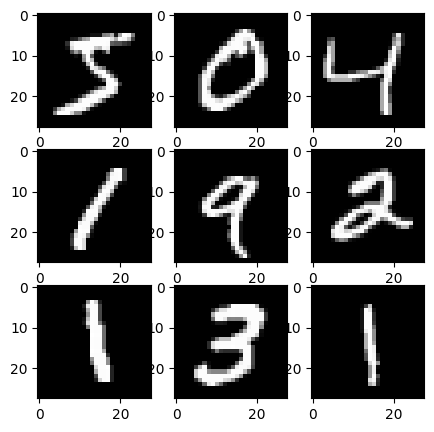

In [80]:
fig, axs = plt.subplots(3, 3,figsize=(5,5))
axs = axs.ravel()

for i in range(9):
    axs[i].imshow(Xtr[i], cmap=plt.get_cmap('gray'))



---


### Preparing the Data
- Prepare your training matrix $\mathbf{X}$.

- We will use one-hot encoding of the labels, that is the original label $y\in\{0, \dots, 9\}$ is mapped to the standard basis vector $e_y$ where $e_y$ is a vector of all zeros except for a 1 in the $y$th position. Then label one-hot encoded in $\mathbf{y}\in \mathbb{R}^{1\times k}$, $k=10$. We can stack all $\mathbf{y}^{(i)}$ to be a matrix $\mathbf{Y}\in \mathbb{R}^{N\times k}$. Prepare your matrix $\mathbf{Y}$.

- Don't forget to do the same preparation for the testing data.





In [81]:
def one_hot(y, num_classes):
    """
    Args:
        y (np.ndarray): An array of integers [0, num_classes), of shape (n,)
        num_classes (int): Number of classes in y.

    Raises:
        ValueError: When a label falls outside [0, num_classes).

    Returns:
        np.ndarray: Array of shape (n, num_classes).
        One-hot representation of y.
    """
    if np.any(y < 0) or np.any(y >= num_classes):
        raise ValueError("every label must lie in [0, num_classes)")
    array = np.zeros((len(y), num_classes))
    for i in range(len(y)):
        array[i,y[i]] = 1
    return array

# checking one_hot implementation
print(Ytr[:9])
print(one_hot(Ytr[:9], 10))


[5 0 4 1 9 2 1 3 1]
[[0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]]


In [82]:
# preparing data
y_train = one_hot(Ytr, 10)
y_test = one_hot(Yte, 10)

n = Xtr.shape[0]
d = Xtr.shape[1]*Xtr.shape[2]
X_train = np.zeros((n,d))
for i in range(n):
    X_train[i] = Xtr[i].reshape((d,))

n_test = Xte.shape[0]
X_test = np.zeros((n_test,d))
for j in range(n_test):
    X_test[j] = Xte[j].reshape((d,))




---


### Deriving the Closed-Form Solution
We will choose a linear classifier to minimize the following objective
\begin{align}
\hat{\mathbf{W}}=\arg\min_{\mathbf{W}\in \mathbb{R}^{d\times k}}\|\mathbf{X}\mathbf{W}-\mathbf{Y}\|_2^2 +\lambda \|\mathbf{W}\|_F^2
\end{align}
where $\|\mathbf{W}\|_F$ is the Frobenius norm of $\mathbf{W}$, $\|\mathbf{W}\|_F^2 = \sum_{i=1}^d\sum_{j=1}^k \mathbf{W}_{ij}^2$. To predict a data point $\mathbf{x}^{(i)}$, the predicted $\hat{\mathbf{y}}^{(i)}= \mathbf{x}^{(i)}\hat{\mathbf{W}}$ and the predicted digit is the corresponding index has the largest value,
\begin{align}
\text{digit} = \arg\max_{j=0,\dots, 9} \hat{\mathbf{y}}^{(i)}_j
\end{align}

**Show** it has analytical solution,
\begin{align}
\hat{\mathbf{W}}= (\mathbf{X}^\top \mathbf{X}+\lambda \mathbf{I})^{-1}\mathbf{X}^\top\mathbf{Y}
\end{align}
Hint: If we just take $i$-th column of $\mathbf{Y}$, it will recover the ridge regression discussed in the lecture.




#### Solution
$$
\begin{align*}
\hat{\mathbf{W}} &= \arg\min_{\mathbf{W}\in \mathbb{R}^{d\times k}}\|\mathbf{X}\mathbf{W}-\mathbf{Y}\|_2^2 +\lambda \|\mathbf{W}\|_F^2 \\
\\
\ell(\hat{\mathbf{W}},\lambda) &= \|\mathbf{X}\mathbf{W}-\mathbf{Y}\|_2^2 +\lambda \|\mathbf{W}\|_F^2 \\
\\
\nabla \ell(\hat{\mathbf{W}},\lambda) &= 2\mathbf{X}^\top \mathbf{XW} -2\mathbf{X}^\top \mathbf{Y} + 2\lambda\mathbf{W} = 0 \\
\\
\Rightarrow & (\mathbf{X}^\top \mathbf{X} +\lambda \mathbf{I}) \mathbf{W} = \mathbf{X}^\top \mathbf{Y} \\
\\
\Rightarrow & \hat{\mathbf{W}} = (\mathbf{X}^\top \mathbf{X} +\lambda \mathbf{I})^{-1} \mathbf{X}^\top \mathbf{Y}
\end{align*}
$$

Since both the Frobenius norm and the penalty decompose column-wise, the objective separates into $k$ independent ridge regression problems:

$$\|\mathbf{XW}-\mathbf{Y}\|_2^2 + \lambda\|\mathbf{W}\|_F^2 = \sum_{j=1}^k \left(\|\mathbf{X}\mathbf{w}_j - \mathbf{y}_j\|^2 + \lambda\|\mathbf{w}_j\|^2\right)$$

Each term is minimized independently (the columns don't interact), and since each is just standard ridge regression on $(\mathbf{w}_j, \mathbf{y}_j)$, the known solution applies:

$$\hat{\mathbf{w}}_j = (\mathbf{X}^\top\mathbf{X} + \lambda\mathbf{I})^{-1}\mathbf{X}^\top\mathbf{y}_j$$

Stacking all $k$ columns gives the matrix result directly:

$$\hat{\mathbf{W}} = (\mathbf{X}^\top\mathbf{X} + \lambda\mathbf{I})^{-1}\mathbf{X}^\top\mathbf{Y}$$



---


### Implementation
- Code a function `train` that takes as input $\mathbf{X}\in\mathbb{R}^{N\times d}, \mathbf{Y}\in \mathbb{R}^{N\times k}, \lambda>0$ and returns $\hat{\mathbf{W}}\in \mathbb{R}^{d\times k}$.

- Code a function `predict` that takes as input $\mathbf{W}\in \mathbb{R}^{d\times k}$, $\tilde{\mathbf{X}}\in\mathbb{R}^{M\times d} $ and returns an $M$-length vector with the $i$th entry equal to $\arg\max_{j=0,\dots, 9} \tilde{\mathbf{y}}^{(i)}_j$, where  $\tilde{\mathbf{y}}^{(i)}$ is the predicted value from the data point $\tilde{\mathbf{x}}^{(i)}$, which is $i$th row of $\tilde{\mathbf{X}}$.

- Train $\hat{\mathbf{W}}$ on MNIST training data with $\lambda=10^{-4}$ and make label predictions on the test data. What is the training and testing error? As a remark, it should be around 15\%.

In [83]:
def train(X, y, lam=.0001):
    """Train function for the Ridge Regression problem.
    Should use observations (`X`), targets (`y`) and regularization parameter (`lambda`)
    to train a weight matrix $$\\hat{W}$$.


    Args:
        X (np.ndarray): observations represented as `(n, d)` matrix.
            n is number of observations, d is number of features.
        y (np.ndarray): targets represented as `(n, k)` matrix.
            n is number of observations, k is number of classes.
        lam (float): parameter for ridge regularization.

    Raises:
        ValueError: When X and y disagree on the number of observations.

    Returns:
        np.ndarray: weight matrix of shape `(d, k)`
            which minimizes Regularized Squared Error on `x` and `y` with hyperparameter `_lambda`.
    """
    if X.shape[0] != y.shape[0]:
        raise ValueError("X and y must have the same number of observations")
    L = np.diag(np.full(X.shape[1], lam))
    # (X^T X + lambda I) is positive definite for lam > 0, so it can be solved directly
    return np.linalg.solve((X.T @ X) + L, X.T @ y)


In [84]:
def predict(X, w):
    """Predict function for the Ridge Regression problem.
    Should use observations (`X`), and weight matrix (`w`) to generate predicted class for each observation in X.

    Args:
        X (np.ndarray): observations represented as `(n, d)` matrix.
            n is number of observations, d is number of features.
        w (np.ndarray): weights represented as `(d, k)` matrix.
            d is number of features, k is number of classes.

    Raises:
        ValueError: When X and w disagree on the number of features.

    Returns:
        np.ndarray: predictions matrix of shape `(n,)`.
    """
    if X.shape[1] != w.shape[0]:
        raise ValueError("X and w must agree on the number of features")
    return np.argmax(X @ w, axis=1)

def compare_error(train_predict, test_predict, y_train, y_test):
    # fraction of labels the predictions get wrong, for each of the two sets
    return [np.mean(train_predict != y_train), np.mean(test_predict != y_test)]


In [85]:
w = train(X_train, y_train)

In [86]:
train_predictions = predict(X_train, w)
test_predictions = predict(X_test, w)
error = compare_error(train_predictions, test_predictions, Ytr, Yte)
print("Training Error:", error[0])
print("Testing Error:", error[1])

Training Error: 0.14805
Testing Error: 0.1466


In [ ]:
# sklearn check: ridge classification on MNIST (no intercept, matching train())
from sklearn.linear_model import Ridge

check_mnist = Ridge(alpha=.0001, fit_intercept=False).fit(X_train, y_train)

print("               %10s %10s" % ("mine", "sklearn"))
print("train error    %10.5f %10.5f" % (error[0], np.mean(np.argmax(check_mnist.predict(X_train), axis=1) != Ytr)))
print("test  error    %10.5f %10.5f" % (error[1], np.mean(np.argmax(check_mnist.predict(X_test), axis=1) != Yte)))
print("max |W difference|  %.2e" % np.abs(w - check_mnist.coef_.T).max())


                     mine    sklearn
train error       0.14805    0.14805
test  error       0.14660    0.14660
max |W difference|  1.21e-07




---


### Improving Accuracy with Random Cosine Features
We just fit a classifier that was linear in the pixel intensities to the MNIST data. For
classification of digits the raw pixel values are very, very bad features: it’s pretty hard to separate
digits with linear functions in pixel space. The standard solution to this is to come up with some
transform $h: \mathbb{R}^d \rightarrow \mathbb{R}^p$ of the original pixel values such that the transformed points are (more easily)
linearly separable. This idea is very similar as SVM. In this problem, you’ll use the feature transform:
\begin{align}
h(\mathbf{x}) = \cos(\mathbf{G}\mathbf{x}+\mathbf{b})
\end{align}
where $\mathbf{G}\in \mathbb{R}^{p\times d}$ and $\mathbf{b}\in \mathbb{R}^p$ and the cosine function is applied elementwise. We will choose $\mathbf{G}$ to be a random matrix, with each entry sampled i.i.d. from a Gaussian distribution with mean $\mu=0$ and $\sigma^2=0.1$. And $\mathbf{b}$ is a random vector sampled i.i.d. from the uniform distribution on $[0,2\pi]$.

The
big question is: how do we choose the dimension $p$? **cross-validation!!** Note you don't need to perform $K$-fold cross-validation here.

- Randomly partition your training set into proportions 80/20 to use as a new training set and validation
set, respectively.

- Using the `train` function you wrote above, train a $\hat{\mathbf{W}}^p$ for different values of $p$.

- Plot the training error and validation error on a single plot with $p$ on the $x$-axis.

Be careful, your computer may run out of memory and slow to a crawl if $p$ is too large. You can use the same value of $\lambda$, which is $\lambda=10^{-4}$. But feel free to study the effect of using different values of $\lambda$ and $\sigma^2$.

Do you improve your training/testing error?

In [87]:
from sklearn.model_selection import train_test_split

CV_Xtrain, CV_Xval, CV_ytrain, CV_yval = train_test_split(X_train, Ytr, test_size=0.20, random_state=13)

onehot_CV_ytrain = one_hot(CV_ytrain,10)
onehot_CV_yval = one_hot(CV_yval,10)


In [88]:
def cos_transform(X, p, seeded=False):
    d = X.shape[1]
    if seeded:
        # G and b are drawn from np.random, so numpy's seed is the one that
        # matters. seeding here makes every call build the SAME transform,
        # which is what lets the training and validation sets share features.
        np.random.seed(13)
    G = np.random.normal(0, .1, (p, d))
    b = np.random.uniform(0, 2*np.pi, (p,))

    # row i of X @ G.T + b is G x_i + b
    return np.cos(X @ G.T + b)


In [89]:
step = 200
p = 1000
stop = 2000
p_list = []
error_list = []

while p <= stop:
    CV_Xtrain_trans = cos_transform(CV_Xtrain, p, seeded=True)
    CV_Xval_trans = cos_transform(CV_Xval, p, seeded=True)
    w_trans = train(CV_Xtrain_trans, onehot_CV_ytrain)
    train_predictions = predict(CV_Xtrain_trans, w_trans)
    valid_predictions = predict(CV_Xval_trans, w_trans)
    error = compare_error(train_predictions, valid_predictions, CV_ytrain, CV_yval)
    error_list.append(error)
    p_list.append(p)
    p += step

error_list = np.asarray(error_list)


Best p: 1800
Training error at best p: 0.03675
Validation error at best p: 0.04441666666666667


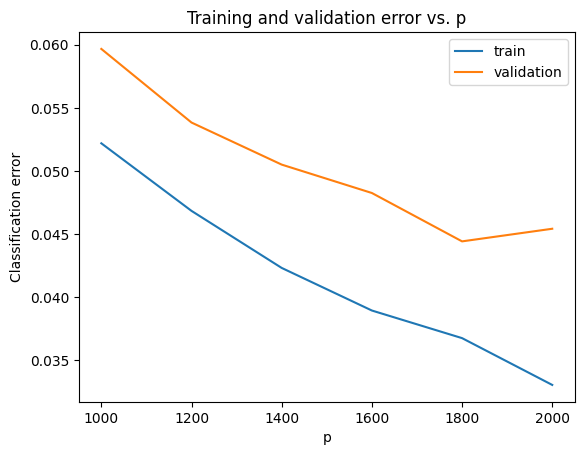

In [90]:
best = np.argmin(error_list[:,1])
print("Best p:", p_list[best])
print("Training error at best p:", error_list[best,0])
print("Validation error at best p:", error_list[best,1])

plt.plot(p_list, error_list)
plt.xlabel("p")
plt.ylabel("Classification error")
plt.title("Training and validation error vs. p")
plt.legend(['train','validation'])
plt.show()


#### Solution

We improved our error by a sizable amount, with our testing error going from $14.8\%$ to $3.68\%$ by implementing the random cosine features.



---


### Confidence Interval via Hoeffding's Inequality
Instead of reporting just the test error, which is an unbiased estimate of the true error, we
would like to report a confidence interval around the test error that contains the true error.

**Lemma**: (Hoeffding’s inequality) Fix $\delta\in(0,1)$, if for all $i=1,\dots, m$ we have that $X_i$ are i.i.d. random variables with $X_i\in [a,b]$ and $\mathbb{E}[X_i]=\mu$ then
\begin{align}
\mathbb{P}\left(\left|\left(\frac{1}{m}\sum_{i=1}^m X_i\right)-\mu\right|\ge \sqrt{\frac{(b-a)^2\log(2/\delta)}{2m}}\right)\le \delta
\end{align}

We will use the above equation to construct a confidence interval around the true classification error $\mathcal{E}(\hat f)= \mathbb{E}_{\text{test}}[\hat{\mathcal{E}}_{\text{test}}(\hat f)]$ since the test error $\hat{\mathcal{E}}_{\text{test}}(\hat f)$ is just the average of indicator variables taking values in $\{0,1\}$ corresponding to the $i$-th test example being classified correctly or not, respectively, where an error happens with probability $\mathcal{E}(\hat f)= \mathbb{E}_{\text{test}}[\hat{\mathcal{E}}_{\text{test}}(\hat f)]$ the true classification error.

Let $\hat p$ be the value of $p$ that approximately minimizes the validation error on the plot you just made
and use $\hat f(x) = \arg\max_j x^\top \hat{\mathbf{W}}^{\hat p}e_j$ to compute the classification test error $\hat{\mathcal{E}}_{\text{test}}(\hat f)$. Use Hoeffding’s
inequality, to compute a confidence interval of $\hat{\mathcal{E}}_{\text{test}}(\hat f)$ that contains the true classification error $\mathbb{E}_{\text{test}}[\hat{\mathcal{E}}_{\text{test}}(\hat f)]$ with probability at least 0.95 (i.e., $\delta=0.05$).   

In [91]:
# the classifier at the best p, evaluated on the test set, with the
# Hoeffding interval for the true classification error
p_hat = p_list[best]
w_hat = train(cos_transform(CV_Xtrain, p_hat, seeded=True), onehot_CV_ytrain)
test_predictions = predict(cos_transform(X_test, p_hat, seeded=True), w_hat)
test_error = np.mean(test_predictions != Yte)

delta = .05
m = len(Yte)
half_width = np.sqrt(np.log(2/delta) / (2*m))

print("p_hat:", p_hat)
print("Test error:", test_error)
print("Half-width:", half_width)
print(f"95% confidence interval: [{test_error - half_width:.4f}, {test_error + half_width:.4f}]")

p_hat: 1800
Test error: 0.0449
Half-width: 0.013581015157406196
95% confidence interval: [0.0313, 0.0585]


In [ ]:
# sklearn check: ridge on the random cosine features at the best p
from sklearn.linear_model import Ridge

check_rf = Ridge(alpha=.0001, fit_intercept=False).fit(cos_transform(CV_Xtrain, p_hat, seeded=True), onehot_CV_ytrain)
sk_test_pred = np.argmax(check_rf.predict(cos_transform(X_test, p_hat, seeded=True)), axis=1)

print("p_hat = %d" % p_hat)
print("               %10s %10s" % ("mine", "sklearn"))
print("test  error    %10.5f %10.5f" % (test_error, np.mean(sk_test_pred != Yte)))
print("max |W difference|  %.2e" % np.abs(w_hat - check_rf.coef_.T).max())


p_hat = 1800
                     mine    sklearn
test  error       0.04490    0.04490
max |W difference|  4.03e-14


#### Solution
The value of $p$ that minimizes the validation error is $\hat{p}=1800$. To avoid overloading $p$, write $\varepsilon=\mathcal{E}(\hat f)$ for the true classification error and $\hat\varepsilon=\hat{\mathcal{E}}_{\text{test}}(\hat f)$ for the test error. The test error is the mean of $m$ i.i.d. indicators $X_i\in\{0,1\}$ with $\mathbb{E}[X_i]=\varepsilon$, so Hoeffding applies with $a=0$, $b=1$ and $\delta=0.05$:

\begin{align}
\mathbb{P}\left(\left|\hat\varepsilon-\varepsilon\right|\ge \sqrt{\frac{\log(2/\delta)}{2m}}\right)\le \delta
\end{align}

Taking the complement of that event, and using $\log(2/0.05)=\log(40)$,

\begin{align}
\mathbb{P}\left(\left|\hat\varepsilon-\varepsilon\right| < \sqrt{\frac{\log(40)}{2m}}\right)\ge 0.95
\end{align}

Unfolding the absolute value turns this into an interval around the test error:

\begin{align}
\mathbb{P}\left(\hat\varepsilon-\sqrt{\frac{\log(40)}{2m}} < \varepsilon < \hat\varepsilon+\sqrt{\frac{\log(40)}{2m}}\right)\ge 0.95
\end{align}

Since $\sqrt{\log(40)/2}\approx 1.358$, the half-width is $1.358/\sqrt{m}$.

For the test set $m=10000$, and the classifier built from $\hat{\mathbf{W}}^{\hat p}$ at $\hat p =1800$ has test error $\hat\varepsilon = 0.0449$. The half-width is therefore $1.358/\sqrt{10000}=0.0136$, giving

\begin{align}
\varepsilon \in [0.0313,\ 0.0585] \qquad \text{with probability at least } 0.95
\end{align}



---



---



## LASSO on USA Crime Data

### The Dataset
The following data consist of local crime statistics for 1994 US communities. We have split the dataset into a training and testing set with 1595 and 399 entries, respectively. We’d like to use
this training set to fit a model to predict the crime rate in new communities and evaluate model performance on
the test set. As there are a considerable number of input variables and fairly few training datapoints, overfitting
is a serious issue. In order to avoid this, use the **stochastic coordinate descent LASSO algorithm**.

The response $y$ is the rate of violent crimes
reported per capita in a community. The name of the response variable is `ViolentCrimesPerPop`, and it is held
in the first column of `df_train` and `df_test`. There are 95 features. These features include many variables.
Some features are the consequence of complex political processes. Others
are demographic characteristics of the community, including self-reported statistics about race, age, education,
and employment drawn from Census reports. You may read the documentation for the original version of this dataset: http://archive.ics.uci.edu/ml/datasets/communities+and+crime. For example, `PctYoungKids2Par` represents percent of kids 4 and under in two parent households (numeric - decimal).

 Note **the features have been standardized to have mean 0 and variance 1**.

The goals of this problem are twofold:
- Think deeply about models you might train and
how they might be misused.

- See how Lasso encourages sparsity of linear models in settings where
the feature set is very large relative to the number of training examples.

We emphasize that training a
model on this dataset can suggest a degree of correlation between a community’s demographics
and the rate at which a community experiences and reports violent crime. We strongly encourage
you to consider why these correlations may or may not hold more generally, whether correlations might
result from a common cause, and what issues can result in misinterpreting what a model can explain.


In [92]:
df_train = pd.read_table("data/crime-train.txt")
df_test = pd.read_table("data/crime-test.txt")

In [93]:
X = df_train.drop('ViolentCrimesPerPop', axis=1)
y = df_train['ViolentCrimesPerPop']

X_test = df_test.drop('ViolentCrimesPerPop', axis=1)
y_test = df_test['ViolentCrimesPerPop']

# indices of the features we follow along the regularization path. these index
# into X, which has the response column dropped -- looking them up in df_train
# would put every index one too high.
a1 = X.columns.get_loc('agePct12t29')
a2 = X.columns.get_loc('pctWSocSec')
a3 = X.columns.get_loc('pctUrban')
a4 = X.columns.get_loc('agePct65up')
a5 = X.columns.get_loc('householdsize')




---


### Stochastic Coordinate Descent LASSO
In class, we introduce the coordinate descent LASSO algorithm in the round robin way. We can also pick the coordinate randomly.

**Algorithm:** To minimize function $\ell(\mathbf{w})$

Initialize $\hat{\mathbf{w}}=0$ or smartly
  - Precompute for all coordiate j
     $$ a_j = \mathbf{X}_j^\top \mathbf{X}_j $$
  - While not converged
   - Pick a coodinate j **uniformly at random**, compute

     \begin{align}
     & c_j = \mathbf{X}_j^\top (\mathbf{y}-\mathbf{X}_{-j}\mathbf{w}_{-j}) \\
     & \hat{w}_j = \text{SoftThreshold}\left(\frac{c_j}{a_j},\frac{\lambda}{a_j}\right)
     \end{align}

Modify the LASSO code in class to stochastic coordinate descent LASSO algorithm.      

In [94]:
def SCD_Lasso_inefficient(X, y, lam=30, w_s=None, timer=False, tol=1e-6, seed=0):

    """
    The Lasso Regression model
    Stochastic coordinate descent, recomputing c_j from scratch each update.

    X - NumPy matrix, size (N, d), of standardized numerical predictors.
    y - NumPy array, length N, of numerical response.
    lam - L1 penalty tuning parameter (positive scalar)
    tol - convergence tolerance: the largest coefficient change over a full
          sweep of d updates must fall below it.

    """
    d = X.shape[1]
    val = pd.DataFrame(X).to_numpy()
    yv = np.asarray(y).ravel()
    w_s = np.zeros(d) if w_s is None else np.asarray(w_s, dtype=float).copy()

    a = np.zeros(d)
    index = []
    for j in range(d):
        a[j] = sum(val[:,j]**2)
        index.append(list(range(0,j)) + list(range(j+1,d)))

    rand.seed(seed)
    iters = 0
    while True:
        # convergence is judged over a whole sweep. checking it after a single
        # coordinate would stop the moment one pick happens not to move, which
        # in Lasso is most of them.
        w_sweep = w_s.copy()
        for _ in range(d):
            # coordinates are drawn uniformly at random WITH replacement
            j = rand.randrange(d)
            c_j = np.dot(val[:,j].T, yv - np.dot(val[:,index[j]], w_s[index[j]]))
            update = c_j/a[j]
            w_s[j] = np.sign(update) * max(abs(update) - lam/a[j], 0)
            iters += 1
        if np.max(np.abs(w_s - w_sweep)) < tol:
            # a block of d random picks leaves ~37% of the coordinates untouched,
            # so a quiet block is not evidence of convergence. confirm with one
            # pass over every coordinate; only a fixed point of ALL of them is a
            # minimum, and for Lasso that fixed point is the global optimum.
            w_check = w_s.copy()
            for j in range(d):
                c_j = np.dot(val[:,j].T, yv - np.dot(val[:,index[j]], w_s[index[j]]))
                update = c_j/a[j]
                w_s[j] = np.sign(update) * max(abs(update) - lam/a[j], 0)
                iters += 1
            if np.max(np.abs(w_s - w_check)) < tol:
                break

    return iters if timer else w_s

print(SCD_Lasso_inefficient(X, y))


[ 0.         -0.         -0.         -0.         -0.          0.
  0.          0.         -0.         -0.         -0.         -0.
  0.          0.         -0.         -0.         -0.          0.
 -0.         -0.          0.          0.          0.          0.
  0.          0.         -0.          0.         -0.         -0.
 -0.         -0.         -0.          0.         -0.          0.00213471
  0.01121352  0.         -0.         -0.06717311 -0.         -0.
 -0.         -0.          0.          0.06986483  0.         -0.
  0.          0.          0.          0.          0.          0.
  0.         -0.          0.          0.          0.          0.
 -0.          0.         -0.          0.02466985  0.         -0.
  0.01754844 -0.         -0.          0.         -0.          0.
  0.          0.          0.          0.          0.         -0.
  0.          0.          0.          0.          0.         -0.
  0.          0.00809978  0.         -0.         -0.          0.
 -0.          0. 



---


### An Efficient LASSO Implementation
In fact, the current code is not efficient since it recalculate the same thing again and again in each iteration, which waste a lot of computational power. Please optimize your code, particularly in calculating `c_j` and `update`. Make sure test the correctness and efficiency in your new code.

In [95]:
def SCD_Lasso(X, y, lam, w_s=None, timer=False, tol=1e-6, seed=0):

    """
    The Lasso Regression model
    Stochastic coordinate descent with co-variance updates is applied.

    X - NumPy matrix, size (N, d), of standardized numerical predictors.
    y - NumPy array, length N, of numerical response.
    lam - L1 penalty tuning parameter (positive scalar)
    tol - convergence tolerance over a full sweep of d updates.

    """
    d = X.shape[1]
    val = pd.DataFrame(X).to_numpy()
    yv = np.asarray(y).ravel()
    w_s = np.zeros(d) if w_s is None else np.asarray(w_s, dtype=float).copy()

    # the co-variance update: X^T X and X^T y are built once, before the loop.
    # c_j is then a length-d dot product instead of a pass over all N rows,
    # which is O(d) per coordinate rather than O(N*d).
    G = val.T @ val
    Xty = val.T @ yv
    a = np.diag(G).copy()

    rand.seed(seed)
    iters = 0
    while True:
        w_sweep = w_s.copy()
        for _ in range(d):
            j = rand.randrange(d)
            # G[j] @ w_s - G[j,j]*w_s[j]  is  X_j^T X_{-j} w_{-j}
            c_j = Xty[j] - (G[j] @ w_s - G[j,j]*w_s[j])
            update = c_j/a[j]
            w_s[j] = np.sign(update) * max(abs(update) - lam/a[j], 0)
            iters += 1
        if np.max(np.abs(w_s - w_sweep)) < tol:
            # a block of d random picks leaves ~37% of the coordinates untouched,
            # so a quiet block is not evidence of convergence. confirm with one
            # pass over every coordinate; only a fixed point of ALL of them is a
            # minimum, and for Lasso that fixed point is the global optimum.
            w_check = w_s.copy()
            for j in range(d):
                c_j = Xty[j] - (G[j] @ w_s - G[j,j]*w_s[j])
                update = c_j/a[j]
                w_s[j] = np.sign(update) * max(abs(update) - lam/a[j], 0)
                iters += 1
            if np.max(np.abs(w_s - w_check)) < tol:
                break

    return iters if timer else w_s


In [96]:
import time

def compare_c_j(X, y, lam, steps=None, seed=0):
    """Checks the co-variance c_j against the direct one on identical weights,
    returning the largest disagreement seen."""
    d = X.shape[1]
    val = pd.DataFrame(X).to_numpy()
    yv = np.asarray(y).ravel()
    w = np.zeros(d)
    index = [list(range(0,j)) + list(range(j+1,d)) for j in range(d)]
    G = val.T @ val
    Xty = val.T @ yv
    a = np.diag(G).copy()

    rand.seed(seed)
    worst = 0.0
    for _ in range(steps or 5*d):
        j = rand.randrange(d)
        c_direct = np.dot(val[:,j].T, yv - np.dot(val[:,index[j]], w[index[j]]))
        c_fast = Xty[j] - (G[j] @ w - G[j,j]*w[j])
        worst = max(worst, abs(c_direct - c_fast))
        # both formulas agree, so it does not matter which one drives the update
        update = c_fast/a[j]
        w[j] = np.sign(update) * max(abs(update) - lam/a[j], 0)
    return worst


# both versions get the same seeds, so they visit the same coordinates in the
# same order and take the same number of iterations. only the time differs.
lamb = 5
loops = 10

start_time = time.time()
iteration_count = sum(SCD_Lasso_inefficient(X, y, lamb, timer=True, seed=s) for s in range(loops))
slow_time = time.time() - start_time
print("inefficient -- avg iterations:", iteration_count/loops)
print("--- %s seconds ---" % slow_time)

start_time = time.time()
iteration_count = sum(SCD_Lasso(X, y, lamb, timer=True, seed=s) for s in range(loops))
fast_time = time.time() - start_time
print("efficient   -- avg iterations:", iteration_count/loops)
print("--- %s seconds ---" % fast_time)

print("speedup: %.1fx" % (slow_time/fast_time))
print("largest |c_j direct - c_j co-variance|:", compare_c_j(X, y, 5))


inefficient -- avg iterations: 18420.5
--- 10.173910140991211 seconds ---
efficient   -- avg iterations: 18420.5
--- 0.3707759380340576 seconds ---
speedup: 27.4x
largest |c_j direct - c_j co-variance|: 2.859934511434403e-13


#### Solution

To make the code above more efficient, I simply recognized that:

$$
\begin{align*}
X^T_j(y-X_{-j} * w^s_{-j}) &= X^T_j*y- X^T_j * (X_{-j} * w^s_{-j})\\
&= X^T_j*y - (X^T_j * X_{-j}) * w^s_{-j}
\end{align*}
$$

This reduces a large number of matrix operations from $y-X_{-j} * w^s_{-j}$ by making two scalars from $X^T_j*y$ and $(X^T_j * X_{-j}) * w^s_{-j}$. This simple change shaved off roughly 10 seconds from the Monte Carlo simulation running the code 1000 times at $\lambda = 1$.

Further changes could go towards figuring out a way to make the $X^T_j * X_{-j}$ term more efficient since there is a bit of overlap in a lot of the iterations, but with the addition of having the changing $w^s_{-j}$ vector every interation, I didn't find much worth in investigating further, especially when my main code below runs entirely through in < 1 second.



---


### Training and the Regularization Path
- We will run the LASSO solver with $\lambda=\lambda_{\max}$ defined above.
- For the initial weights, just use 0. Then, cut
$\lambda$ down by a factor of 2 and run again, but this time pass in the values of $\hat{\mathbf w}$ from your $\lambda=\lambda_{\max}$ solution as
your initial weights. This is faster than initializing with 0 weights each time.(You need to modify LASSO function accordingly, e.g., you can let initial weights as your input.)

- Continue the process of cutting $\lambda$ by a factor of 2 until the smallest value of $\lambda$ is less than 0.01. Define “converging” as the change in any coefficient between one iteration and the next is no larger than $10^{-6}$.



For all plots use a log-scale for $\lambda$. You use `plt.xscale('log')`.
- Plot the number of nonzeros of each solution versus $\lambda$.

- Plot the regularization paths (in one plot) for the coefficients for input features `agePct12t29`,
`pctWSocSec`, `pctUrban`, `agePct65up`, and `householdsize`.

- On one plot, plot the squared error on the training and test data versus $\lambda$.

- Sometimes a larger value of $\lambda$ performs nearly as well as a smaller value, but a larger value will
select fewer variables and perhaps be more interpretable. Inspect the weights (on features) for $\lambda=30$.
Which feature variable had the largest (most positive) Lasso coefficient? What about the most negative?
Discuss briefly.


In [97]:
# retrieves the number of non-zero entries in a list
def nonzero_count(l):
    return int(np.count_nonzero(l))

# retrieves mse_train and mse_test for a given w
def squared_error(X_train, Y_train, X_test, Y_test, w):
    x_train = pd.DataFrame(X_train).to_numpy()
    y_train = np.asarray(Y_train).ravel()
    x_test = pd.DataFrame(X_test).to_numpy()
    y_test = np.asarray(Y_test).ravel()

    # ravel matters: an (N,1) target against an (N,) prediction would broadcast
    # to an (N,N) matrix instead of subtracting elementwise
    mse_train = np.mean(np.square(x_train @ w - y_train))
    mse_test = np.mean(np.square(x_test @ w - y_test))
    return [mse_train, mse_test]


# lambda_max is the smallest lambda whose solution is all zeros. with the
# soft threshold lam/a_j used above that is max_j |X_j^T y| = 276.38, so the
# path may start anywhere above it; 480 is used because halving from there
# lands exactly on the lambda = 30 asked about below.
lamb_max = 480

# capturing, for each lambda: the lambda itself, the number of nonzeros in w,
# the coefficients of the 5 features we care about, and the train/test mse
lambdas = []
nonzeros = []
features = []
mse = []

w_iter = np.zeros(X.shape[1])
lamb = lamb_max
while lamb > .01:
    # each solve warm-starts from the previous lambda's solution
    # 1e-6 is the tolerance the problem prescribes, but it leaves one boundary
    # coefficient (~1e-4) unsettled near the small-lambda end, which shows up as a
    # spurious kink in the nonzero plot. 1e-8 settles it; the solutions are
    # otherwise identical.
    w_iter = SCD_Lasso(X, y, lamb, w_iter, tol=1e-8)
    lambdas.append(np.round(lamb, 6))
    nonzeros.append(nonzero_count(w_iter))
    features.append([w_iter[a1], w_iter[a2], w_iter[a3], w_iter[a4], w_iter[a5]])
    mse.append(squared_error(X, y, X_test, y_test, w_iter))
    lamb = lamb/2

features = np.asarray(features)
mse = np.asarray(mse)


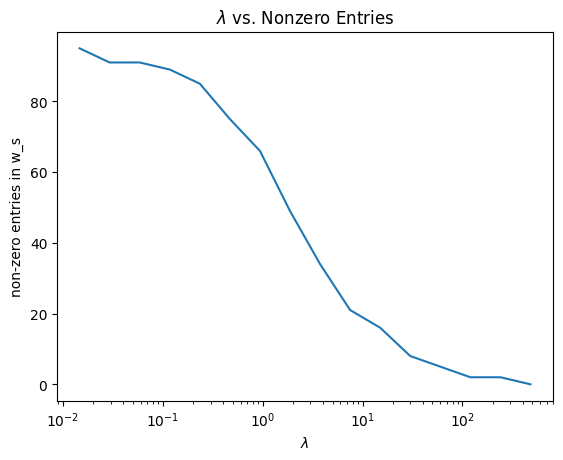

In [98]:
plt.plot(lambdas, nonzeros)
plt.xscale('log')
plt.xlabel(r"$\lambda$")
plt.ylabel("non-zero entries in w_s")
plt.title(r"$\lambda$ vs. Nonzero Entries")
plt.show()


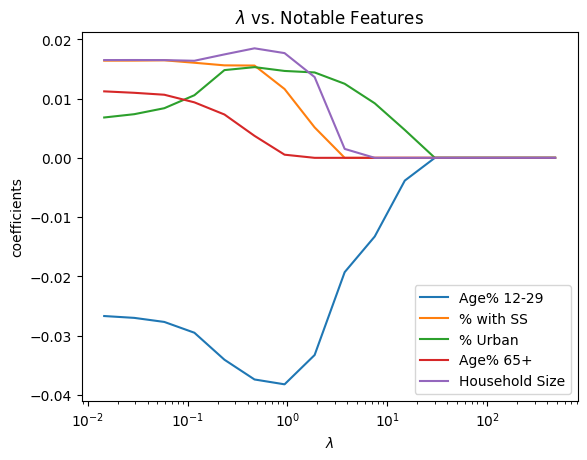

In [99]:
plt.plot(lambdas, features)
plt.xscale('log')
plt.xlabel(r"$\lambda$")
plt.ylabel("coefficients")
plt.title(r"$\lambda$ vs. Notable Features")
plt.legend(['Age% 12-29','% with SS','% Urban','Age% 65+','Household Size'])
plt.show()


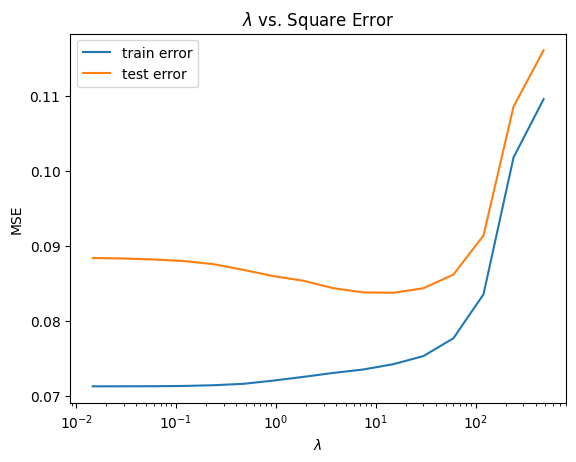

In [100]:
plt.plot(lambdas, mse)
plt.xscale('log')
plt.xlabel(r"$\lambda$")
plt.ylabel("MSE")
plt.title(r"$\lambda$ vs. Square Error")
plt.legend(['train error','test error'])
plt.show()


In [101]:
w_30 = SCD_Lasso(X, y, 30, np.zeros(X.shape[1]))

# w_30 is aligned to X, so the names come from X.columns
max_index = int(np.argmax(w_30))
min_index = int(np.argmin(w_30))

print("most positive:", X.columns[max_index], w_30[max_index])
print("most negative:", X.columns[min_index], w_30[min_index])
print("nonzero features at lambda = 30:", nonzero_count(w_30))


most positive: PctIlleg 0.06986482711464004
most negative: PctKids2Par -0.06717311064703362
nonzero features at lambda = 30: 8


In [ ]:
# sklearn check: lasso. our soft threshold is lam/a_j, which is sklearn's alpha = lam/n
from sklearn.linear_model import Lasso

n_train = X.shape[0]
sk_lasso = lambda lam: Lasso(alpha=lam/n_train, fit_intercept=False, tol=1e-10, max_iter=200000).fit(X, y).coef_
check_w30 = sk_lasso(30)

print("lambda = 30                %-18s %-18s" % ("mine", "sklearn"))
print("  nonzeros                 %-18d %-18d" % (nonzero_count(w_30), nonzero_count(check_w30)))
print("  most positive            %-18s %-18s" % (X.columns[int(np.argmax(w_30))], X.columns[int(np.argmax(check_w30))]))
print("  most negative            %-18s %-18s" % (X.columns[int(np.argmin(w_30))], X.columns[int(np.argmin(check_w30))]))
print("  max |coefficient difference|  %.2e" % np.abs(w_30 - check_w30).max())

print("\nregularization path        nonzeros          test MSE")
print("   %9s   %6s %6s   %9s %9s" % ("lambda", "mine", "sklrn", "mine", "sklearn"))
for lamb_i, nz_i, mse_i in zip(lambdas, nonzeros, mse):
    sk_w = sk_lasso(lamb_i)
    sk_mse = np.mean((X_test.to_numpy() @ sk_w - np.asarray(y_test).ravel())**2)
    print("   %9.4f   %6d %6d   %9.6f %9.6f" % (lamb_i, nz_i, nonzero_count(sk_w), mse_i[1], sk_mse))


lambda = 30                mine               sklearn           
  nonzeros                 8                  8                 
  most positive            PctIlleg           PctIlleg          
  most negative            PctKids2Par        PctKids2Par       
  max |coefficient difference|  3.34e-05

regularization path        nonzeros          test MSE
      lambda     mine  sklrn        mine   sklearn
    480.0000        0      0    0.116106  0.116106
    240.0000        2      2    0.108590  0.108590
    120.0000        2      2    0.091372  0.091372
     60.0000        5      5    0.086160  0.086160
     30.0000        8      8    0.084331  0.084331
     15.0000       16     16    0.083724  0.083724
      7.5000       21     21    0.083775  0.083775
      3.7500       34     34    0.084342  0.084342
      1.8750       49     49    0.085339  0.085339
      0.9375       66     66    0.085956  0.085956
      0.4688       75     75    0.086800  0.086800
      0.2344       85     85    

#### Solution

From the randomness of the SCD lasso, it's hard to get a distinguished result from the max/min coefficients of the lasso as it's different every time, at least for a relatively large $\lambda$. We can conclude that a lower $\lambda$ would be more suitable for this particular data using SCD lasso.



---

# Part II — Model Complexity and Kernel Methods

Where prediction error comes from, and how to buy nonlinearity cheaply: the bias-variance decomposition, kernel regression, and random Fourier feature approximations.


In [ ]:
%pylab inline
import pandas as pd
from scipy import linalg
from itertools import combinations
import matplotlib.pyplot as plt
import scipy
import scipy.io as io
import scipy.sparse as sparse
import numpy as np
import statistics as stats
from sklearn import model_selection

Populating the interactive namespace from numpy and matplotlib


/usr/local/lib/python3.10/dist-packages/IPython/core/magics/pylab.py:159: UserWarning: pylab import has clobbered these variables: ['linalg', 'rand']
`%matplotlib` prevents importing * from pylab and numpy
  warn("pylab import has clobbered these variables: %s"  % clobbered +


## Bias-Variance Trade-off
Let $\boldsymbol{\theta}\in\mathbb{R}^n$ be the unknown true means of our $n$ Gaussian distributions,i.e., we get a vector $\mathbf{X}$ where each $\mathbf{X}_i\sim \mathcal{N}(\theta_i, \sigma^2), i=1,\dots, n$. We assume every Gaussian distribution has the same variance and is independent, but means can be different. Our job is to find the estimator $\hat{\boldsymbol{\theta}}$ to minimize the expected error $\mathbb{E}[\|\hat{\boldsymbol{\theta}}-\boldsymbol{\theta}\|_2^2]$.  All expectations are taken with respect to the random draws of the $\mathbf{X}_i$ random variables.



---



### Derivation
**Show** the Bias-Variance trade-off formula for the estimator
\begin{align}
\mathbb{E}[\|\hat{\boldsymbol{\theta}}-\boldsymbol{\theta}\|_2^2] = \mathbb{V}[\hat{\boldsymbol{\theta}}]+\text{bias}^2[\hat{\boldsymbol{\theta}}]
\end{align}
where $\mathbb{V}[\hat{\boldsymbol{\theta}}] = \mathbb{E}[\|\hat{\boldsymbol{\theta}} -\mathbb{E}[\hat{\boldsymbol{\theta}}]\|_2^2]$ and $\text{bias}^2[\hat{\boldsymbol{\theta}}] = \|\mathbb{E}[\hat{\boldsymbol{\theta}}-\boldsymbol{\theta}]\|_2^2$

#### Solution

Note: $\mathbb{V}[\hat{\boldsymbol{\theta}}] = \mathbb{E}[(\hat{\boldsymbol{\theta}})^2] -\mathbb{E}[\hat{\boldsymbol{\theta}}]^2 \Rightarrow \mathbb{V}[\hat{\boldsymbol{\theta}}] +\mathbb{E}[\hat{\boldsymbol{\theta}}]^2 = \mathbb{E}[(\hat{\boldsymbol{\theta}})^2]$.

Then:

$$
\begin{align*}
\mathbb{E}[\|\hat{\boldsymbol{\theta}}-\boldsymbol{\theta}\|_2^2] &= \mathbb{E}[(\hat{\boldsymbol{\theta}})^2 + \boldsymbol{\theta}^2 - 2\hat{\boldsymbol{\theta}} · \boldsymbol{\theta}]\\
&= \mathbb{E}[(\hat{\boldsymbol{\theta}})^2] + \mathbb{E}[\boldsymbol{\theta}^2] - \mathbb{E}[2\hat{\boldsymbol{\theta}} ·\boldsymbol{\theta}]\\
&= \mathbb{V}[\hat{\boldsymbol{\theta}}] + \mathbb{E}[\hat{\boldsymbol{\theta}}]^2 - 2\boldsymbol{\theta}\mathbb{E}[\hat{\boldsymbol{\theta}} ] + \boldsymbol{\theta}^2 \\
&= \mathbb{V}[\hat{\boldsymbol{\theta}}] + (\mathbb{E}[\hat{\boldsymbol{\theta}}] - \boldsymbol{\theta})^2\\
&= \mathbb{V}[\hat{\boldsymbol{\theta}}]+\text{bias}^2(\hat{\boldsymbol{\theta}})
\end{align*}
$$




If we only observe one data, which is just $\mathbf{X}$. Of course, the most natural choice of the estimator is $\hat{\boldsymbol{\theta}}=\mathbf{X}$.

---


### $\text{Bias}^2$ and Variance for the Natural Estimator
What is the $\text{Bias}^2$ and variance of the natural estimator $\hat{\boldsymbol{\theta}}=\mathbf{X}$?


#### Solution

$$
\begin{align*}
\text{bias}^2(\mathbf{X}) &= (\mathbb{E}[\mathbf{X}] - \theta)^2\\
&= (\theta - \theta)^2\\
&= 0,\\
\\
\mathbb{V}[\mathbf{X}] &= \sigma^2
\end{align*}
$$



---


### $\text{Bias}^2$ and Variance for the Shrinkage Estimator

Let's try a different estimator, shrinkage estimator, $\hat{\boldsymbol{\theta}}=\frac{9}{10}\mathbf{X}$.

What is the $\text{Bias}^2$ and variance of the shrinkage estimator $\hat{\boldsymbol{\theta}}=\frac{9}{10}\mathbf{X}$?


#### Solution

$$
\begin{align*}
\text{bias}^2(\frac{9}{10}\mathbf{X}) &= (\mathbb{E}[\frac{9}{10}\mathbf{X}] - \theta)^2\\
&= (\frac{9}{10}\mathbb{E}[\mathbf{X}] - \theta)^2\\
&= (\frac{9}{10}\theta - \theta)^2\\
&= ( - \frac{1}{10}\theta)^2\\
&= \frac{1}{100}\theta^2,\\
\\
\mathbb{V}[\frac{9}{10}\mathbf{X}] &= \frac{81}{100}\mathbb{V}[\mathbf{X}]\\
&= \frac{81}{100}\sigma^2
\end{align*}
$$



---


### Which Estimator Is Better?
Suppose you know that the variance of our samples is quite a bit. Specifically assume $\sigma^2>\frac{1}{10}\theta_i^2$ for all $i$. Which estimator is better?

#### Solution

With a much larger change occuring to the variance w.r.t the shrinkage estimator v.s. the bias, we claim that for higher variances, it would be better to help reduce the variance with a slight increase to the bias, as high variance tends to be worse for models than a slight bias. As is the case for the "trade-off" we are studying, there will be a happy medium in which our model will be better off with an increase to the bias if the variance is high, especially in the case above where our variance is bounded below w.r.t the mean.



---



---



## Kernelized Regression

 This problem will get you familiar with kernel ridge regression using the polynomial and RBF kernels.
 First, let's generate some data. Let $n=30$ and $f_*(x) = 4 \sin(\pi x)\cos(6\pi x^2)$.
For $i=1,\dots,n$ let each $x_i$ be drawn uniformly at random from $[0,1]$, and let $y_i = f_*(x_i) + \epsilon_i$ where $\epsilon_i \sim \mathcal{N}(0,1)$.
For any function $f$, the true error and the train error are respectively defined as:
$$\mathcal{E}_{\rm true}(f) = \mathbb{E}_{X,Y}\left[(f(X) - Y)^2\right], \quad \quad  \widehat{\mathcal{E}}_{\rm train}(f) =  \frac{1}{n} \sum_{i=1}^n \left(f(x_i)-y_i\right)^2.$$
Now, our goal is, using kernel ridge regression, to construct a predictor:
$$\widehat{\alpha} = \arg\min_\alpha \|K\alpha - y\|_2^2 + \lambda \alpha^\top K \alpha \ , \quad \quad \widehat{f}(x) = \sum_{i=1}^n \widehat{\alpha}_i k(x_i,x)$$
where $K\in\mathbb{R}^{n\times n}$ is the kernel matrix such that $K_{i,j} = k(x_i,x_j)$, and $\lambda\geq 0$ is the regularization constant.



---

### Selecting Kernel Hyperparameters
Using leave-one-out cross validation, find a good $\lambda$ and hyperparameter settings for the following kernels:

- $k_{\rm poly}(x,z) = (1+x^\top z)^d$ where $d \in \mathbb{N}$ is a hyperparameter,
- $k_{\rm rbf}(x,z) = \exp(-\gamma \|x-z\|_2^2)$ where $\gamma > 0$ is a hyperparameter. Given a dataset $x_1,\dots,x_n \in \mathbb{R}^d$, a heuristic for choosing a range of $\gamma$ in the right ballpark is the inverse of the median of all $\binom{n}{2}$ squared distances $\|x_i-x_j\|^2$.


We strongly recommend implementing either [grid search](https://en.wikipedia.org/wiki/Hyperparameter_optimization#Grid_search)
or [random search](https://en.wikipedia.org/wiki/Hyperparameter_optimization#Random_search).
**Do not use sklearn**, but actually implement of these algorithms. Reasonable values to look through in this problem are: $\lambda \in 10^{[-5, -1]}$ and $d \in [5, 25]$. You do **not** need to search over $\gamma$ (you can use the heuristic), but if you would like to, a reasonable place to start would be to sample from a narrow gaussian distribution centered at the value described above.

Report the values of $d$, $\lambda$, and $\gamma$ for both kernels.

In [ ]:
def get_data(n):
    # returns a numpy array of size (n,) where each element is from unif(0,1)
    return np.random.uniform(0, 1, (n,))

def get_errors(n):
    # returns a numpy array of size (n,) where each element is from norm(0,1)
    return np.random.normal(0, 1, (n,))

def f_star(x):
    # returns the "transformed" array based on the function f* given above
    return np.dot(4*np.sin(np.pi*x), np.cos(6*np.pi*(x**2)))

def gamma_heuristic(x):
    n = len(x)
    values = []
    for i in range(n):
        for j in range(i+1,n):
            values.append( (x[i]-x[j])**2 )
    return stats.median(values)[0]

def kernel_regression(k, y, lam):
    # returns optimal alpha
    n = len(k)
    return np.dot(np.linalg.inv(k+lam*np.eye(n)),y)

def kernel_poly(x,z,d):
    # returns rbf kernel K
    m = len(x)
    n = len(z)
    K = np.zeros((m,n))
    for i in range(m):
        for j in range(n):
            K[i,j] = (np.dot(x[i],z[j]) + 1)**d
    return K

def kernel_rbf(x,z,gam):
    # returns rbf kernel K
    m = len(x)
    n = len(z)
    K = np.zeros((m,n))
    for i in range(m):
        for j in range(n):
            K[i,j] = np.exp(-(gam*linalg.norm(x[i]-z[j])**2))
    return K

def pred_poly(x,z,d,alpha):
    # returns predictions y for poly
    ktest = kernel_poly(x,z,d)
    return np.dot(alpha,ktest)[0]

def pred_rbf(x,z,gam,alpha):
    # returns predictions y for rbf
    ktest = kernel_poly(x,z,gam)
    return np.dot(alpha,ktest)

def loo_mse(y_hat, y):
    sum = 0
    for i in range(len(y_hat)):
        sum += (y_hat[i]-y[i])**2
    return sum/n

def leaveoneout_poly(x,y,lam,d, get_f=False):
    # returns the average mse of leave-one-out rbf kernelized regression of x, y using hyperparameters lambda and gamma
    n = len(x)
    pred_list = []
    for i in range(n):
        xtr = np.delete(x, i)
        xte = x[i].reshape((1,1))
        ytr = np.delete(y, i)
        yte = y[i]
        K = kernel_poly(xtr,xtr,d)
        alpha = kernel_regression(K,ytr,lam)
        y_pred = pred_poly(xtr,xte,d,alpha)
        pred_list.append(y_pred)
    if get_f:
        return pred_list
    else:
        return loo_mse(pred_list, y)[0]

def leaveoneout_rbf(x,y,lam,gam,get_f=False):
    # returns the average mse of leave-one-out rbf kernelized regression of x, y using hyperparameters lambda and gamma
    n = len(x)
    pred_list=[]
    for i in range(n):
        xtr = np.delete(x, i)
        xte = x[i].reshape((1,1))
        ytr = np.delete(y, i)
        yte = y[i]
        K = kernel_rbf(xtr,xtr,gam)
        alpha = kernel_regression(K,ytr,lam)
        y_pred = pred_rbf(xtr,xte,gam,alpha)
        pred_list.append(y_pred)
    if get_f:
        return pred_list
    else:
        return loo_mse(pred_list, y)[0]

def grid_search(x,y,kernel_type, d_range_min = 5, d_range_max = 25, log_lam_range_min = -5,
                log_lam_range_max = -1, search_range = 10):

    # for kernel_type == "rbf", returns a list of [minimum error, lambda, gamma] for LOOCV rbf kernelized regression
    # for kernel_type == "poly", returns a list of [minimum error, lambda, d] for LOOCV polynomial kernelized regression

    lams = np.logspace(log_lam_range_min, log_lam_range_max, search_range)  # lambda parameter grid

    if kernel_type == "rbf":
        # solve for heuristic
        gam_heur = gamma_heuristic(x)
        gams = np.linspace(gam_heur-1, gam_heur+1, search_range)
        min_error = np.infty
        for lam in lams:
            for gam in gams:

                temp_error = leaveoneout_rbf(x,y,lam,gam)

                if temp_error < min_error:
                    min_error = temp_error
                    best_lam = lam
                    best_gam = gam

        return [min_error, best_lam, best_gam]

    elif kernel_type == "poly":
        ds = np.linspace(d_range_min, d_range_max, search_range)  # d parameter grid
        min_error = np.infty
        for lam in lams:
            for d in ds:
                temp_error = leaveoneout_poly(x,y,lam,d)

                if temp_error < min_error:
                    min_error = temp_error
                    best_lam = lam
                    best_d = d

        return [min_error, best_lam, best_d]


    else:
        raise NotImplementedError




In [ ]:
data_size = 30
x = get_data(data_size)
error = get_errors(data_size)
y = f_star(x) + error


In [ ]:
import time

start_time = time.time()

poly_sim = grid_search(x,y,'poly')
rbf_sim = grid_search(x,y,'rbf')

print("Grid Search algorithm for Polynomial Kernel: min error =", poly_sim[0], ", best lambda =", poly_sim[1], ", best d =", poly_sim[2])
print(" ")
print("Grid Search algorithm for RBF Kernel: min error =", rbf_sim[0], ", best lambda =", rbf_sim[1], ", best gamma =", rbf_sim[2])
print("total time: ", time.time() - start_time)


<ipython-input-197-be915dc6fbaf>:33: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  K[i,j] = (np.dot(x[i],z[j]) + 1)**d
<ipython-input-197-be915dc6fbaf>:43: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  K[i,j] = np.exp(-(gam*linalg.norm(x[i]-z[j])**2))


Random Search algorithm for Polynomial Kernel: min error = 0.908861434129281 , best lambda = 0.0005994842503189409 , best d = 11.666666666666668
 
Random Search algorithm for Polynomial Kernel: min error = 1.0369987754211702 , best lambda = 0.1 , best gamma = [0.18496347]
total time:  88.27164220809937



#### Solution

After running the grid search a handful of times with different random sets of data, the output seemed to agree to show that $d \in [10,12], \lambda \in [.0001, .001]$.

The gamma heuristic was used to make a range to search through, where typically our output was $\gamma \in [.1,.2]$, depending on the data generated. We elect to use the heuristic for the below testing.



---

### Plotting the Learned Functions
 Let $\widehat{f}_{\rm poly}(x)$ and $\widehat{f}_{\rm rbf}(x)$ be the functions learned using the hyperparameters you found in Q2.1.
For a single plot per function $\widehat{f} \in \left\lbrace \widehat{f}_{\rm poly}(x), \widehat{f}_{\rm rbf}(x) \right\rbrace$, plot the original data $\{(x_i,y_i)\}_{i=1}^n$, the true $f(x)$, and $\widehat{f}(x)$ (i.e., define a fine grid on $[0,1]$ to plot the functions). Make Two plots. One plot for each function.


<ipython-input-199-1ba6d74db2bb>:33: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  K[i,j] = (np.dot(x[i],z[j]) + 1)**d


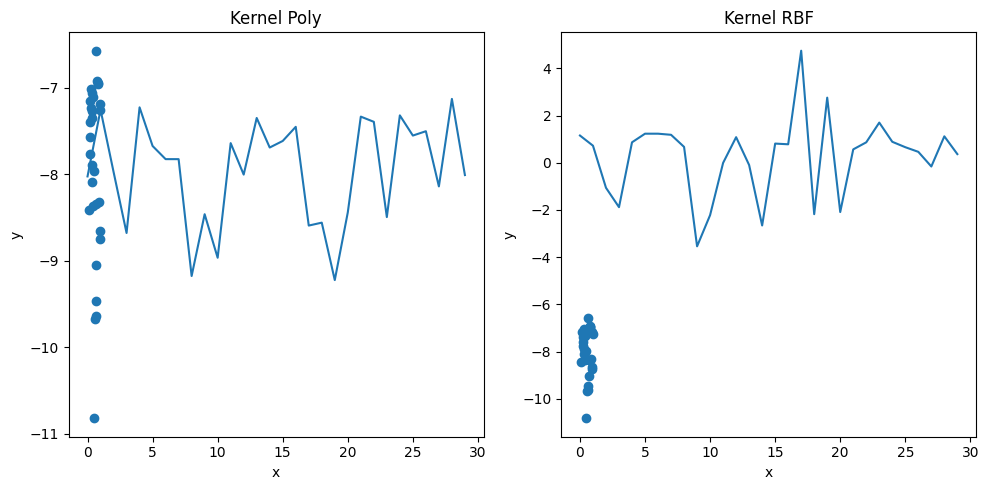

In [ ]:
# using the output from the data generated above:

best_lam_poly = .0005
best_d = 11
best_lamb_rbf = .1
best_gam = gamma_heuristic(x)

f_poly = leaveoneout_poly(x,y,best_lam_poly,best_d,True)

f_rbf = leaveoneout_rbf(x,y,best_lam_rbf,best_gam,True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

ax1.scatter(x, y)
ax1.plot(f_poly)
ax1.set_title('Kernel Poly')
ax1.set_xlabel('x')
ax1.set_ylabel('y')

ax2.scatter(x, y)
ax2.plot(f_rbf)
ax2.set_title('Kernel RBF')
ax2.set_xlabel('x')
ax2.set_ylabel('y')

plt.tight_layout()

plt.show()



---



---


## Random Fourier Features
This question is going to answer why Homework 1 Q2.4 works so well.

Kernel methods such as Logistic Regression are considered memory-based learners. Rather than learning a mapping from a set of input features $\mathcal{X} \subset \mathbb{R}^d$ to outputs in $\mathcal{Y}$, they remember all training examples $(\mathbf{x_i}, y_i)$ and learn a corresponding weight for them.

\begin{align*}
    \hat{f}(\mathbf{x}) = \sum_{i=1}^N \omega_i k(\mathbf{x_i}, \mathbf{x})
\end{align*}

After learning the weight vector $\mathbf{w} = [\mathbf{w}_1, ..., \mathbf{w}_N]$, we can make prediction on unseen samples using the **kernel function** $k$ between all training samples and $\mathbf{x}$. Kernel methods are attractive because they rely on the \textit{kernel trick}. Any positive definite function $k(\mathbf{x}, \mathbf{x}')$ with $\mathbf{x}, \mathbf{x}' \in \mathbb{R}^d$ defines a function $\psi$ mapping $\mathbb{R}^d$ to a higher-dimensional space such that the inner product between datapoints can be quickly computed as $\langle \psi(\mathbf{x}), \psi(\mathbf{x}') \rangle = k(\mathbf{x}, \mathbf{x}')$. In essence, the kernel trick is an efficient way to learn a linear decision boundary in a higher dimension space than that of $\mathcal{X}$.

The kernel trick can be prohibitively expensive for large datasets. This is because the memory-based algorithm accesses the data through evaluations of the kernel matrix $k(x, x')$ which grows in proportion to the dataset size $N$.

Instead of relying on the implicit feature mapping $\psi$ provided by the kernel trick, suppose we can approximate the kernel function $k$ as the inner product of two vectors in $\mathbb{R}^D$. Mathematically, we would like to find a mapping $\mathbf{z}$.

\begin{align*}
    \mathbf{z} : \mathbb{R}^d \rightarrow \mathbb{R}^D \qquad \text{such that} \qquad k_p(\mathbf{x}, \mathbf{x}') = \langle \psi(\mathbf{x}), \psi(\mathbf{x}') \rangle \approx \langle \mathbf{z}(\mathbf{x}), \mathbf{z}(\mathbf{x}') \rangle
\end{align*}

With this approximation, we no longer require the kernel trick to express $\langle \psi(\mathbf{x}), \psi(\mathbf{x}')\rangle$ as $k(\mathbf{x}, \mathbf{x}')$. Rather, we can approximate it by directly computing the tractable inner product $\langle \mathbf{z}(\mathbf{x}), \mathbf{z}(\mathbf{x}')\rangle$.
\begin{align*}
    \hat{f}(\mathbf{x}) = \sum_{i=1}^N \mathbf{\omega}_i k(\mathbf{x}_i, \mathbf{x}) = \sum_{i=1}^N \mathbf{\omega}_i  \langle \psi(\mathbf{x}_i), \psi(\mathbf{x}) \rangle \approx  \sum_{i=1}^N \mathbf{\omega}_i \langle \mathbf{z}(\mathbf{x}), \mathbf{z}(\mathbf{x})\rangle = \left(\sum_{i=1}^N \mathbf{\omega}_i \mathbf{z}(\mathbf{x}_i)^T \right) \mathbf{z}(\mathbf{x}) = \beta^T \mathbf{z}(\mathbf{x})
\end{align*}

Assuming $\mathbf{z}(\mathbf{x}) = \sigma(M \mathbf{x} + b)$ for some nonlinear function $\sigma$, this ``approximate'' Logistic Regression can potentially be evaluated much quicker than the kernel Logistic Regression.
To see why, note that the left-hand-side requires evaluating $k(\mathbf{x_i}, \mathbf{x})$ for all $i \in \{1,\dots,N\}$, in general, if $\omega_i$ is not sparse.
On the other hand, the right-hand-side just requires computing $\mathbf{z}(\mathbf{x})=\sigma(M \mathbf{x} + b)$ which is dominated by the time to compute a $D \times d$ matrix-vector product, and then inner product with $\beta$ which is $\mathbb{R}^D$.
Thus, the total computation time for the left-hand-side scales linearly with $N$, and the right-hand-side scales with just $d$ and $D$, independent of $N$!

When training the approximate Logistic Regression we also get similar computational savings if $N \gg \max\{d,D\}$.


---

### Derivation
Bochner's theorem states that a continuous kernel $k(\mathbf{x}, \mathbf{x}') = k(\mathbf{x}-\mathbf{x}')$ on $\mathbb{R}^d$ is positive definite if and only if $k$ is the Fourier transform of a non-negative measure. While we won't delve into the logic of Fourier transforms here, this theorem lets us express the kernel as follows: for any probability distribution $p(\mathbf{w})$ define
\begin{align*}
    k_p(\mathbf{x}, \mathbf{x}') := \int_{\mathbb{R}^d} p(\mathbf{w}) e^{i\mathbf{w}^T (\mathbf{x}-\mathbf{x}')}dw = \mathbb{E}_{\mathbf{w}} \left[e^{i\mathbf{w}^T (\mathbf{x}-\mathbf{x}')}\right]
\end{align*}
where $i = \sqrt{-1}$, the imaginary unit. While any choice of $p(\mathbf{w})$ induces a valid kernel, in this problem we'll be focusing on the Gaussian distribution, namely
\begin{align*}
    p(\mathbf{w}) = (2\pi\sigma^2)^{-\frac{D}{2}}e^{-\frac{1}{2 \sigma^2} \vert\vert \mathbf{w} \vert\vert ^2_2} = (2\pi/\gamma^2)^{-\frac{D}{2}}e^{-\gamma^2 \vert\vert \mathbf{w} \vert\vert ^2_2/2} \quad \text{where} \ \gamma = \frac{1}{\sigma}
\end{align*}
We'll use this Fourier-transform interpretation of $k$ to derive a randomized mapping $\mathbf{z}: \mathbb{R}^d \rightarrow \mathbb{R}^D$ which is an unbiased estimate of the kernel function i.e.
\begin{align*}
            \mathbb{E}_{\mathbf{w}}[\mathbf{z}(\mathbf{x})^T \mathbf{z}(\mathbf{x}')] = k_p(\mathbf{x}, \mathbf{x}')
\end{align*}
If $\mathbf{z}(x)^T \mathbf{z}(x')$ serves as a good approximation to the kernel matrix, we can apply the aforementioned approximation algorithm.


---


#### Step 1
Use Euler's formula $e^{iy} = \cos(y) + i \sin(y)$ to show that $k_p(\mathbf{x}, \mathbf{x}') = E_{\mathbf{w}} \left[\cos(\mathbf{w}^T(\mathbf{x}-\mathbf{x}')) \right]$.

**Hint:** If both $x$ and $A$ are real, then $A = \int f(x) + ig(x) dx = \int f(x) dx $.



##### Solution

$$
\begin{align*}
k_p(\mathbf{x}, \mathbf{x}') &= \int_{\mathbb{R}^d} p(\mathbf{w}) e^{i\mathbf{w}^T (\mathbf{x}-\mathbf{x}')}dw\\
&= \int_{\mathbb{R}^d} p(\mathbf{w}) \left[ \cos(\mathbf{w}^T (\mathbf{x}-\mathbf{x}')) + i\sin(\mathbf{w}^T (\mathbf{x}-\mathbf{x}')) \right] dw\\
&= \int_{\mathbb{R}^d} p(\mathbf{w})\cos(\mathbf{w}^T (\mathbf{x}-\mathbf{x}')) + i p(\mathbf{w})\sin(\mathbf{w}^T (\mathbf{x}-\mathbf{x}')) dw\\
&= \int_{\mathbb{R}^d} p(\mathbf{w})\cos(\mathbf{w}^T (\mathbf{x}-\mathbf{x}')) dw\\
&= E_{\mathbf{w}} \left[\cos(\mathbf{w}^T(\mathbf{x}-\mathbf{x}')) \right]
\end{align*}
$$



---


#### Step 2
We begin by defining $z_{\mathbf{w}} : \mathbb{R}^d \rightarrow \mathbb{R}$ as
\begin{align*}
    z_{\mathbf{w}}(\textbf{x}) &= \sqrt{2} \cos (\mathbf{w}^T\mathbf{x} + b) & \text{where} \  \mathbf{w} \sim p(\mathbf{w}), \ b &\sim \text{Uniform}(0, 2\pi)
\end{align*}
Note that this is not yet the mapping vector $\mathbf{z}$, but rather a mapping to $\mathbb{R}$. Use part (i) to show that the expected product of $z_\mathbf{w}(\mathbf{x})$s is an unbiased estimate of the kernel function i.e.
\begin{align*}
     E_{\mathbf{w}, b}\left[z_{\mathbf{w}}(\mathbf{x})z_{\mathbf{w}}(\mathbf{x}')\right] = k_p(\mathbf{x}, \mathbf{x}')
\end{align*}

**Hint:** For this problem you may use the following identity: $2\cos(\alpha) \cos(\beta) = \cos(\alpha+\beta) + \cos(\alpha - \beta)$.

##### Solution

$$
\begin{align*}
E_{\mathbf{w}, b}\left[z_{\mathbf{w}}(\mathbf{x})z_{\mathbf{w}}(\mathbf{x}')\right] &= E_{\mathbf{w}, b}\left[ (\sqrt{2} \cos (\mathbf{w}^T\mathbf{x} + b)) * (\sqrt{2} \cos (\mathbf{w}^T\mathbf{x}' + b) )\right]\\
&= E_{\mathbf{w}, b}\left[ 2 * \cos (\mathbf{w}^T\mathbf{x} + b)) * ( \cos (\mathbf{w}^T\mathbf{x}' + b) )\right]\\
&= E_{\mathbf{w}, b}\left[  \cos ( (\mathbf{w}^T\mathbf{x} + b) + (\mathbf{w}^T\mathbf{x}' + b)) +  \cos ( (\mathbf{w}^T\mathbf{x} + b) - (\mathbf{w}^T\mathbf{x}' + b) )\right]\\
&= E_{\mathbf{w}, b}\left[  \cos ( \mathbf{w}^T(\mathbf{x}+\mathbf{x}') + 2b) +  \cos ( \mathbf{w}^T(\mathbf{x}-\mathbf{x}') )\right]\\
&= E_{\mathbf{w}, b}\left[  \cos ( \mathbf{w}^T(\mathbf{x}+\mathbf{x}') + 2b) \right] +  E_{\mathbf{w}}\left[ \cos ( \mathbf{w}^T(\mathbf{x}-\mathbf{x}') )\right]\\
(*) &= 0+ k_p(\mathbf{x}, \mathbf{x}')\\
&= k_p(\mathbf{x}, \mathbf{x}')
\end{align*}
$$

Where, for  $(*),$ we use the Law of Total Expectation:
$$
\begin{align*}
\\
E_{\mathbf{w}, b}\left[  \cos ( \mathbf{w}^T(\mathbf{x}+\mathbf{x}') + 2b) \right] &= E_{\mathbf{w}}\left[  E_{b} \left[\cos ( \mathbf{w}^T(\mathbf{x}+\mathbf{x}') + 2b) | \mathbf{w} \right] \right], \\
\\
\end{align*}
$$
and let $\omega := \mathbf{w}^T(\mathbf{x}+\mathbf{x}')$ for simplicity. Then we have the following:
$$
\begin{align*}
\\
E_{\mathbf{w}}\left[  E_{b} \left[\cos ( \omega + 2b) | \mathbf{w} \right] \right]&= E_{\mathbf{w}}\left[ \int_0^{2\pi} \frac{\cos(\omega + 2b)}{2\pi}db | \mathbf{w} \right]\\
&= E_{\mathbf{w}}\left[ \frac{1}{4\pi} \sin(\omega + 2b) \biggr\rvert_0^{2\pi} | \mathbf{w} \right]\\
&= \frac{1}{4\pi} E_{\mathbf{w}}\left[ \sin(\omega + 4\pi) - \sin(\omega) | \mathbf{w} \right]\\
&= \frac{1}{4\pi} E_{\mathbf{w}}\left[ \sin(\omega) - \sin(\omega) | \mathbf{w} \right]\\
&= \frac{1}{4\pi} E_{\mathbf{w}}\left[ 0 | \mathbf{w} \right]\\
&= 0
\end{align*}
$$



---


#### Step 3
Now we're ready to define our random Fourier features $\mathbf{z}: \mathbb{R}^d \rightarrow \mathbb{R}^D$. Let $\mathbf{z}$ be the $d$-dimensional concatenation of $z_{\mathbf{w}}(\mathbf{x})$:
\begin{align*}
    \mathbf{z}(\mathbf{x}) &= \begin{bmatrix}
       \frac{1}{\sqrt{D}} z_{\mathbf{w}_1}(\mathbf{x}) , \  
       \frac{1}{\sqrt{D}} z_{\mathbf{w}_2}(\mathbf{x}) , \
       \dots
       , \
       \frac{1}{\sqrt{D}} z_{\mathbf{w}_D}(\mathbf{x})
     \end{bmatrix}^T
\end{align*}
Use step 1 and 2 to show that the expected inner product of the mapping $\mathbf{z}$ is an unbiased estimate of the kernel function i.e.
\begin{align*}
    E_{\mathbf{w}}[\mathbf{z}(\mathbf{x})^T \mathbf{z}(\mathbf{x}')] = k_p(\mathbf{x}, \mathbf{x}')
\end{align*}


##### Solution

$$
\begin{align*}
E_{\mathbf{w}}[\mathbf{z}(\mathbf{x})^T \mathbf{z}(\mathbf{x}')] &= E_{\mathbf{w}}\left[\begin{bmatrix}
       \frac{1}{\sqrt{D}} z_{\mathbf{w}_1}(\mathbf{x}) , \  
       \dots
       , \
       \frac{1}{\sqrt{D}} z_{\mathbf{w}_D}(\mathbf{x})
     \end{bmatrix}^T \begin{bmatrix}
       \frac{1}{\sqrt{D}} z_{\mathbf{w}_1}(\mathbf{x}') , \  
       \dots
       , \
       \frac{1}{\sqrt{D}} z_{\mathbf{w}_D}(\mathbf{x}')
     \end{bmatrix}\right]\\
&= E_{\mathbf{w}}\left[ \frac{1}{D} z_{\mathbf{w}_1}(\mathbf{x})z_{\mathbf{w}_1}(\mathbf{x}') + \dots + \frac{1}{D} z_{\mathbf{w}_D}(\mathbf{x})z_{\mathbf{w}_D}(\mathbf{x}') \right]\\
&= \frac{1}{D} E_{\mathbf{w}}\left[ \sum_{i=1}^D z_{\mathbf{w}_i}(\mathbf{x})z_{\mathbf{w}_i}(\mathbf{x}') \right]\\
&= \frac{1}{D} \sum_{i=1}^D E_{\mathbf{w}_i,b}\left[z_{\mathbf{w}_i}(\mathbf{x})z_{\mathbf{w}_i}(\mathbf{x}') \right]\\
\text{since 3.1.2 holds for any } \mathbf{w} \sim p(\mathbf{w}), \text{we have} \dots &= \frac{1}{D} \sum_{i=1}^D k_p(\mathbf{x}, \mathbf{x}')\\
&= \frac{1}{D} (D*k_p(\mathbf{x}, \mathbf{x}'))\\
&= k_p(\mathbf{x}, \mathbf{x}')
\end{align*}
$$



---


### Approximating the RBF Kernel
As mentioned above, using different distributions $p(\mathbf{w})$ induces different valid kernels.
Using the $p(\mathbf{w})$ given in Q3.1, show that expected value of the inner product between random Fourier features is the RBF kernel i.e.
\begin{align*}
    E_{\mathbf{w}}[\mathbf{z}(\mathbf{x})^T \mathbf{z}(\mathbf{x}')] = \exp\left(-\frac{ \vert\vert\mathbf{x} - \mathbf{x}'\vert\vert_2^2}{2 \gamma^2}\right)
\end{align*}

**Hint:** The PDF for a variable $X \in \mathbb{R}^d$ following normal distribution with mean $\mu$ and covariance matrix $\Sigma$ is as follows:
\begin{align*}
    P(X = x) = ((2 \pi)^d |\Sigma|)^{-1/2} \exp{(-\frac{1}{2} (x - \mu)^\top \Sigma^{-1} (x - \mu))}
\end{align*}
where $|\Sigma| = \text{det}(\Sigma)$ denote the determinant of matrix $\Sigma$. In addition, if $\Sigma = \text{diag} (\sigma^2, \ldots, \sigma^2)$, then $|\Sigma| = \sigma^{2d}$, and $\Sigma^{-1} = \text{diag}(\sigma^{-2}, \ldots, \sigma^{-2})$.



#### Solution
Let $\mathbf{\delta} = \mathbf{x}-\mathbf{x}'$:

$$
\begin{align*}
E_{\mathbf{w}}[\mathbf{z}(\mathbf{x})^T \mathbf{z}(\mathbf{x}')] &= k_p(\mathbf{x}, \mathbf{x}')\\
&= \int_{\mathbb{R}^d} p(\mathbf{w}) e^{i\mathbf{w}^T \mathbf{\delta}}dw\\
&= \int_{\mathbb{R}^d} (2\pi\sigma^2)^{-\frac{d}{2}}\exp{\left(-\frac{1}{2 \sigma^{-2}} \vert\vert \mathbf{w} \vert\vert ^2_2\right)} * e^{i\mathbf{w}^T \mathbf{\delta}} dw\\
&= \int_{\mathbb{R}^d} (\frac{\gamma}{\sqrt{2 \pi}})^{d} *\exp{\left(-\frac{1}{2\gamma^{2}} \mathbf{w}^T\mathbf{w} + i\mathbf{w}^T \mathbf{\delta}\right)} dw \\
&= (\frac{\gamma}{\sqrt{2 \pi}})^{d} \int_{\mathbb{R}^d} \exp{\left(\frac{1}{2\gamma^{2}}(-\mathbf{w}^T\mathbf{w} + i2\gamma^2\mathbf{w}^T \mathbf{\delta} + (\mathbf{\delta}^T\mathbf{\delta})) - \frac{1}{2\gamma^2}(\mathbf{\delta}^T\mathbf{\delta})\right)} dw \\
&= (\frac{\gamma}{\sqrt{2 \pi}})^{d} \exp{(- \frac{1}{2\gamma^2}(\mathbf{\delta}^T\mathbf{\delta}))} \int_{\mathbb{R}^d} \exp{\left(\frac{1}{2\gamma^{2}}(\mathbf{w}-i\mathbf{\delta})^T(\mathbf{w}-i\mathbf{\delta})\right)} dw \\
&= (\frac{\gamma}{\sqrt{2 \pi}})^{d} \exp{(-\frac{1}{2\gamma^2}(\mathbf{\delta}^T\mathbf{\delta}))} * (\frac{2\pi}{\gamma^2})^{d/2} \\
&= \exp{(-\frac{\mathbf{\delta}^T\mathbf{\delta}}{2\gamma^2})}\\
&= \exp\left(-\frac{ \vert\vert\mathbf{x} - \mathbf{x}'\vert\vert_2^2}{2 \gamma^2}\right)\\
\end{align*}
$$



---


### Concentration Bounds
In Q3.1 we derived our function $\mathbf{z}$ which serve as a good approximation to the kernel function. Our results let us get an upper bound our approximation error for the kernel function. Explain why we can apply **Hoeffding's inequality** (See HW1) to obtain
\begin{align*}
    p(|\mathbf{z}(\mathbf{x})^T \mathbf{z}(\mathbf{x}') - k(\mathbf{x}, \mathbf{x}')| \geq \epsilon) \leq 2 \exp \left(-D\epsilon^2/8\right)
\end{align*}  


#### Solution

To apply Hoeffding's inequaltiy, we simply need to show that for all $i=1,\dots, m$, all $X_i$ are i.i.d. random variables such that each $X_i\in [a,b]$ and $\mathbb{E}[X_i]=\mu$.

In this case, it is assumed $\mathbf{x}$ and $\mathbf{x'}$ are i.i.d and the mapping $\mathbf{z}(\mathbf{x})=\sigma(M \mathbf{x} + b)$ does not affect this property, so  $\mathbf{z}(x_i)$ and $\mathbf{z}(x'_i)$, $i=1,\dots, m$, are i.i.d.

By 3.1, we showed that $\mathbb{E}[\mathbf{z}(\mathbf{x})^T \mathbf{z}(\mathbf{x}')] = k_p(\mathbf{x}, \mathbf{x}')$ for any $|\mathbf{x}| = m,$ so the expectation requirement holds.

Finally, by setting our mapping via some function of cosine, i.e. $\mathbf{z}(\mathbf{x}) = a \cos (M\mathbf{x} + b)$, we have a natural bound for $\mathbf{z}(\mathbf{x})$ being the amplitudes of the cosine function, namely here $\mathbf{z}(x_i) \in [-a,a],$ thus Hoeffding's Inequality holds.



---


### Empirical Verification on MNIST
Remind that in HW 1 Q2.4. We mentioned as follows.
The standard solution to this is to come up with some
transform $h: \mathbb{R}^d \rightarrow \mathbb{R}^p$ of the original pixel values such that the transformed points are (more easily)
linearly separable. **This idea is very similar as SVM**. In this problem, you’ll use the feature transform:
\begin{align}
h(\mathbf{x}) = \cos(\mathbf{G}\mathbf{x}+\mathbf{b})
\end{align}
where $\mathbf{G}\in \mathbb{R}^{p\times d}$ and $\mathbf{b}\in \mathbb{R}^p$ and the cosine function is applied elementwise. We will choose $\mathbf{G}$ to be a random matrix, with each entry sampled i.i.d. from a Gaussian distribution with mean $\mu=0$ and $\sigma^2=0.1$. And $\mathbf{b}$ is a random vector sampled i.i.d. from the uniform distribution on $[0,2\pi]$.

Use the parameter and data above and design an algorithm to verify expected value of the inner product between random Fourier features is the RBF kernel. You don't need to use all the data since it might take too much time.

In [ ]:
from keras.datasets import mnist
(train_X, train_y), (test_X, test_y) = mnist.load_data()
# consider to make your training data set larger, maybe even to use the full training (60000).
# Normalize it by dividing 255.
Xtr                   = train_X/255
Ytr                   = train_y
Xte                   = test_X/255
Yte                   = test_y


# setting up data

n = Xtr.shape[0]
d = Xtr.shape[1]*Xtr.shape[2]
X_train = np.zeros((n,d))
for i in range(n):
    X_train[i] = Xtr[i].reshape((d,))

n_test = Xte.shape[0]
X_test = np.zeros((n_test,d))
for j in range(n_test):
    X_test[j] = Xte[j].reshape((d,))

# shrinking data size by .1 for faster running
shrink_train_size = 6000
shrink_test_size = 1000


Xtr_simp = X_train[:shrink_train_size]
Ytr_simp = Ytr[:shrink_train_size]
Xte_simp = X_test[:shrink_test_size]
Yte_simp = Yte[:shrink_test_size]

(60000, 28, 28)
(60000, 784)


In [235]:
def cos_transform(X, p):
    d = X.shape[1]
    G = np.random.normal(0, .1, (p, d))
    b = np.random.uniform(0, 2*np.pi, (p,))
    new_X = np.dot(G,X.T).T + b
    return np.cos(new_X)

Xtr_trans = cos_transform(Xtr_simp, 3000)
inner_prod = np.dot(Xtr_trans, Xtr_trans.T)/(np.sum(Xtr_trans**2))
expect = np.mean(inner_prod)

In [243]:
import random

def rbf(x,z,gam):
    return np.exp(-(gam*linalg.norm(x-z)**2))

gam = .1
check_error = 0
for i in range(20):
    a = random.randint(0,5999)
    b = random.randint(0,5999)
    check_error += (rbf(Xtr_simp[a], Xtr_simp[b], gam) - expect)**2
print(check_error/20)


8.811547977172274e-08


For 20 random sets of vectors $x_a, x_b$, the rbf kernel and the expected value of the fourier features has an error of magnitude $\in [10^{-7},10^{-8}],$ making this an exceptional estimate.



---

# Part III — Classification

Discriminative and generative classifiers: soft-margin SVMs trained three ways, multinomial naive Bayes, and decision trees.


In [1]:
%pylab inline
import pandas as pd
from scipy import linalg
from itertools import combinations
import numpy as np
import matplotlib.pyplot as plt
import random
import time
import scipy.io as io
from scipy.io import mmread
import scipy.sparse as sparse
from sklearn.tree import DecisionTreeClassifier


Populating the interactive namespace from numpy and matplotlib




---



---


## Soft Margin SVM

In the problem, you will implement the soft margin SVM using different gradient descent methods. Our
goal for this problem is to investigate the convergence of different gradient descent methods on a sample dataset and think about the characteristics of these different methods that lead to different performances.

To recap, given a dataset of $n$
samples $\mathcal{D} =
\left\{\left(\mathbf{x}^{(i)},
y^{(i)}\right)\right\}_{i=1}^n$, where every $d$-dimensional feature vector $\mathbf{x}^{(i)} \in \mathbb{R}^d$ is
associated with a label $y^{(i)} \in
\{-1,1\}$, to estimate the parameters $\boldsymbol{\theta} = (\mathbf{w}, b)$
of the soft margin SVM, we can minimize the loss function:

\begin{aligned}
f(\mathbf{w},b; \mathcal{D}) &= \frac{1}{2}
\|\mathbf{w}\|_2^2 + C \sum_{(\mathbf{x}^{(i)}, y^{(i)}) \in
\mathcal{D}} \max\left\{0, 1 - y^{(i)}( \mathbf{w}\cdot
\mathbf{x}^{(i)} + b )\right\} \\
&= \frac{1}{2} \|\mathbf{w}\|_2^2 + C
\sum_{(\mathbf{x}^{(i)}, y^{(i)}) \in \mathcal{D}}
L(\mathbf{x}^{(i)}, y^{(i)}; \boldsymbol{\theta})
\end{aligned}

In order to minimize the function, we first obtain the gradient with
respect to $\boldsymbol{\theta}$. The
partial derivative with respect to $w_j$, the $j$-th entry in the vector $\mathbf{w}$, is:

\begin{aligned}
    \partial_{w_j} f(\mathbf{w},b; \mathcal{D}) =
    \frac{\partial f(\mathbf{w},b; \mathcal{D})}{\partial w_j} =
    w_j + C \sum_{(\mathbf{x}^{(i)}, y^{(i)}) \in \mathcal{D}}
\frac{\partial L(\mathbf{x}^{(i)}, y^{(i)};
\boldsymbol{\theta})}{\partial w_j}
\end{aligned}
where

\begin{aligned}
\frac{\partial L(\mathbf{x}^{(i)}, y^{(i)};
\boldsymbol{\theta})}{\partial w_j} =     
\left\{\begin{array}{cl}
      0 & \text{if}\  y^{(i)}\left(\mathbf{w} \cdot
\mathbf{x}^{(i)} + b \right) \ge 1 \\
      -y^{(i)}x_j^{(i)} & \text{otherwise.}
    \end{array}\right.
\end{aligned}
and the partial derivative with respect to $b$ is
\begin{aligned}
\partial_b f(\mathbf{w},b;\mathcal{D})  =
\frac{\partial f(\mathbf{w},b;\mathcal{D})}{\partial b} =
C \sum_{(\mathbf{x}^{(i)}, y^{(i)}) \in \mathcal{D}} \frac{\partial
L(\mathbf{x}^{(i)}, y^{(i)}; \boldsymbol{\theta})}{\partial b}
\end{aligned}
where
\begin{aligned}
\frac{\partial L(\mathbf{x}^{(i)}, y^{(i)};
\boldsymbol{\theta})}{\partial b} =     
\left\{\begin{array}{cl}
      0 & \text{if}\  y^{(i)}\left(\mathbf{w} \cdot
\mathbf{x}^{(i)} + b \right) \ge 1 \\
      -y^{(i)} & \text{otherwise.}
    \end{array}\right.
\end{aligned}

Since the direction of the gradient is the
direction of steepest ascent of the loss function, gradient descent
proceeds by iteratively taking small steps along the direction opposite
to the direction of gradient. The general framework of gradient descent
is given in following Algorithm.

<img src="https://github.com/yexf308/AppliedStatistics/blob/main/Homework/HW2/algorithm.png?raw=true" width="500" />


**Task**:

1. Implement the SVM algorithm using
the following gradient descent variants.
For all the variants use $C =
100, \mathbf{w}^{(0)} =
\mathbf{0}, b^{(0)} =
0$. For all other parameters, use the values specified in the
description of the variant.

2. Run your implementation on the
data set. The data set contains the following
files:
- *features.txt*: Each
line contains the features (comma-separated values) of a single sample.
It has 6414 samples (rows) and 122 features (columns).
- *target.txt* : Each
line contains the target variable ($y = -1$ or $1$) for the corresponding
row in *features.txt*.

3. Plot the value of the loss
function $f(\mathbf{w}^{(t)},b^{(t)};
\mathcal{D})$ vs. the iteration number $t$ starting from $t=0$. Label the plot axes. The diagram
should have graphs from all the three variants on the same plot. Report the total time (wall clock time, as opposed to the number of iterations) each of the gradient descent variants takes to converge. What do you infer from the plots and the time for convergence? Explain using 4-6
sentences.

**Note**: update the parameters $\mathbf{w}$ and $b$ on iteration $t$ using the values computed on iteration
$t-1$. Do not update using values
computed in the current iteration!

In [2]:
!wget https://raw.githubusercontent.com/yexf308/AppliedStatistics/main/Homework/HW2/target.txt?raw=true -O target.txt
!wget https://raw.githubusercontent.com/yexf308/AppliedStatistics/main/Homework/HW2/features.txt?raw=true -O features.txt


--2024-12-11 07:42:22--  https://raw.githubusercontent.com/yexf308/AppliedStatistics/main/Homework/HW2/target.txt?raw=true
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.109.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 17673 (17K) [text/plain]
Saving to: ‘target.txt’

target.txt          100%[===================>]  17.26K  --.-KB/s    in 0.001s  

2024-12-11 07:42:22 (14.1 MB/s) - ‘target.txt’ saved [17673/17673]

--2024-12-11 07:42:22--  https://raw.githubusercontent.com/yexf308/AppliedStatistics/main/Homework/HW2/features.txt?raw=true
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
L

In [3]:
features = np.loadtxt('features.txt', delimiter=',')
target = np.loadtxt('target.txt', delimiter=',')
print(features.shape, target.shape)

(6414, 122) (6414,)




---


### Batch Gradient Descent
When the $\beta = n$, in every iteration the
algorithm uses the entire dataset to compute the gradient and update the
parameters.

As a convergence criterion for batch gradient
descent we will use $\Delta_{\% loss}^{(t)}
\le \varepsilon$, where
\begin{aligned}
    \Delta_{\% loss }^{(t)} = \frac{|f(\mathbf{w}^{(t-1)},
b^{(t-1)}; \mathcal{D}) - f(\mathbf{w}^{(t)}, b^{(t)};
\mathcal{D})|}{f(\mathbf{w}^{(t-1)}, b^{(t-1)};
\mathcal{D})}\times100   
\end{aligned}

Set $\eta = 3\cdot10^{-7}$, $\varepsilon = 0.25$.

**Sanity Check 1**: The value of the loss function at iteration
number $t = 0$ must be around
641,400.

In [19]:
def Loss(x, y, w, b, C):
    # returns the value of the Loss function as defined above
    if type(y) == np.ndarray:
        sum = 0
        for i in range(len(y)):
            sum += max( 0, 1 - ( y[i] * (w.dot(x[i,:])+b) ) )
        return .5*(linalg.norm(w)**2) + C*sum
    else:
        return .5*linalg.norm(w)**2 + C*max(1 - ( y * (w.dot(x)+b) ), 0)

def ConvergeCriterion(x, y, w, prev_w, b, prev_b, C):
    # returns the convergence criterion as defined above
    prev = Loss(x, y, prev_w, prev_b, C)
    curr = Loss(x, y, w, b, C)
    return (100*abs(prev - curr))/prev

def DelF_w(x, y, w, b, C, j):
    # returns the value of the derivative of the loss function with respect to the jth value in w
    if type(y) == np.ndarray:
        sum = 0
        for i in range(len(y)):
            if y[i] * (w.dot(x[i,:])+b) < 1:
                sum+=(-1)*y[i]*x[i,j]
        return w[j] + C*sum
    else:
        if y * (w.dot(x)+b) < 1:
            return (-1)*y*x[j]
        else:
            return 0

def DelF_b(x, y, w, b, C):
    # returns the value of the derivative of the loss function with respect to b
    if type(y) == np.ndarray:
        sum = 0
        for i in range(len(y)):
            if y[i] * (w.dot(x[i,:])+b) < 1:
                sum+= (-1)*y[i]
        return C*sum
    else:
        if y * (w.dot(x)+b) < 1:
            return (-1)*y
        else:
            return 0

def unison_shuffled_copies(a, b):
    # returns a shuffled list of both x and y with respect to their indicies
    assert len(a) == len(b)
    p = np.random.permutation(len(a))
    return a[p], b[p]

def GradientDescent(x, y, grad_type = "batch", learn_rate = .0001,
                           batch_size = 100, convergence_val = .25):
    """
    This is the implementation of the above gradient descent algorithm, including
    both batch and stochastic type varients within.

    INPUTS:
    x <- feature matrix
    y <- target vector
    grad_type <- type of Gradient Descent we wish to perform, either batch, mini batch or stochastic
    learn_rate <- affects how quickly our w and b variables change per iteration
    batch_size <- affects how much of the data set D we use
    convergence_val <- affects how large our Convergence Criterion must get before the algorithm ends

    OUTPUTS:
    w <- weights vector, trained after convergence
    b <- coefficient, trained after convergence
    loss_list <- values of the loss function for each iteration
    """
    N,d = x.shape
    assert batch_size <= N
    assert grad_type == "batch" or grad_type == "stochastic" or grad_type == "mini batch"

    # initial conditions
    w = np.zeros((d,))
    b = 0
    C = 100

    # shuffle x, y
    x,y = unison_shuffled_copies(x, y)

    # Loss list
    loss_list = [Loss(x,y,w,b,C)]

    # iteration
    t=0
    k=1

    while t<10000: # used as a stop in case of divergence
        # iteration of t
        t+=1

        # getting batch
        if batch_size == N:
            batch_x = x
            batch_y = y
        elif batch_size == 1:
            batch_x = x[k]
            batch_y = y[k]
        else:
            low = batch_size*k + 1
            high = min(batch_size*(k+1), N)
            batch_x = x[low:high]
            batch_y = y[low:high]

        # learning w
        old_w = w.copy()
        old_b = b
        for j in range(0,d):
            w[j] = old_w[j] - (learn_rate*DelF_w(batch_x, batch_y, old_w, old_b, C, j))
        '''
        elif grad_type == "stochastic":
            old_w = w.copy()
            old_b = b
            if t > 1:
                old_old_w = old_w.copy()
                old_old_b = old_b
            for j in range(0,d):
                w[j] = old_w[j] - (learn_rate*DelF_w(batch_x, batch_y, old_w, old_b, C, j))
        elif grad_type == "mini batch":
            old_w = w.copy()
            old_b = b
            if t > 1:
                old_old_w = old_w.copy()
                old_old_b = old_b
            for j in range(0,d):
                w[j] = old_w[j] - (learn_rate*DelF_w(batch_x, batch_y, old_w, old_b, C, j))
        '''

        # learning b
        b = old_b - (learn_rate*DelF_b(batch_x, batch_y, old_w, old_b, C))

        # new k
        k = int((k+1)%np.ceil(N/batch_size))

        # adding to Loss list
        loss_list.append(Loss(x,y,w,b,C))

        # convergence criterion check
        if grad_type == "batch":
            conv = ConvergeCriterion(x, y, w, old_w, b, old_b, C)
            if conv <= convergence_val:
                print("job's done at t =", t)
                break
        elif grad_type == "stochastic" or grad_type == "mini batch":
            if t == 1:
                conv_curr = ConvergeCriterion(x, y, w, old_w, b, old_b, C)
                conv_prev = 0
            else:
                conv_prev = conv
                conv_curr = ConvergeCriterion(x, y, w, old_w, b, old_b, C)

            conv = .5*conv_curr + .5*conv_prev
            if conv < convergence_val:
                print("job's done at t =", t)
                break

    return w, b, loss_list


In [5]:
start_time = time.time()

# i tuned convergence val to .2 so i get a slightly better curve on the plot
grad_w, grad_b, grad_loss = GradientDescent(features, target, grad_type = "batch",
                                            learn_rate = 3e-7, batch_size = 6414,
                                            convergence_val = .2)

grad_time = time.time() - start_time
#print("General Gradient Descent b:",grad_b)
#print("General Gradient Descent w:",grad_w)

job's done at t = 66





---


### Stochastic Gradient Descent
When $\beta = 1$, in every iteration the
algorithm uses one training sample at a time to compute the gradient and
update the parameters.
As a convergence criterion for stochastic
gradient descent we will use $\Delta_{loss}^{(t)} < \varepsilon$,
where \begin{aligned}
    \Delta_{loss}^{(t)} = \tfrac{1}{2}\Delta_{loss}^{(t-1)} +
\tfrac{1}{2}\Delta_{\% loss}^{(t)},
\end{aligned}
$t$ is the
iteration number, $\Delta_{\%
loss}^{(t)}$ is same as above and
and $\Delta_{loss}^{(0)} = 0$.
Use $\eta = 0.0001, \varepsilon = 0.001$.

In [20]:
start_time = time.time()

# not sure why im not getting to a clear convergence here, but i am for mini batch.
stoch_w, stoch_b, stoch_loss = GradientDescent(features, target, grad_type = "stochastic",
                                               learn_rate = .0001, batch_size=1,
                                               convergence_val = .001)

stoch_time = time.time() - start_time
#print("Stochastic Gradient Descent b:",stoch_b)
#print("Stochastic Gradient Descent w:",stoch_w)

job's done at t = 3170




---


### Mini-Batch Gradient Descent
In every iteration the algorithm uses mini-batches of $\beta$ samples to compute the gradient and
update the parameters.
As a convergence criterion for mini-batch
gradient descent we will use $\Delta_{loss}^{(t)} < \varepsilon$,
where $\Delta_{loss}^{(t)}$ is the
same as above  and $\Delta_{loss}^{(0)} = 0$.
Use $\eta = 10^{-5}, \varepsilon = 0.01$ and $\beta = 20$.

**Sanity Check 2**: Batch GD should converge in 10-300
iterations and SGD between 500-3000 iterations with Mini Batch GD
somewhere in-between. However, the number of iterations may vary greatly
due to randomness. If your implementation consistently takes longer,
there might be a bug.

In [22]:
start_time = time.time()

mb_w, mb_b, mb_loss = GradientDescent(features, target, grad_type = "mini batch",
                                      learn_rate = .00001, batch_size=20,
                                      convergence_val = .01)

mb_time = time.time() - start_time
#print("Mini Batch Gradient Descent b:",mb_b)
#print("Mini Batch Gradient Descent w:",mb_w)

job's done at t = 1079


### Comparing Convergence and Runtime
Plot the value of the loss
function $f(\mathbf{w}^{(t)},b^{(t)};
\mathcal{D})$ vs. the iteration number $t$ starting from $t=0$. Label the plot axes. The diagram
should have graphs from all the three variants on the same plot. Report the total time (wall clock time, as opposed to the number of iterations) each of the gradient descent variants takes to converge. What do you infer from the plots and the time for convergence? Explain using 4-6
sentences.

**Sanity Check 3**: The expected total run time for all 3
methods is around 5-15 minutes but might vary depending on the
implementation.

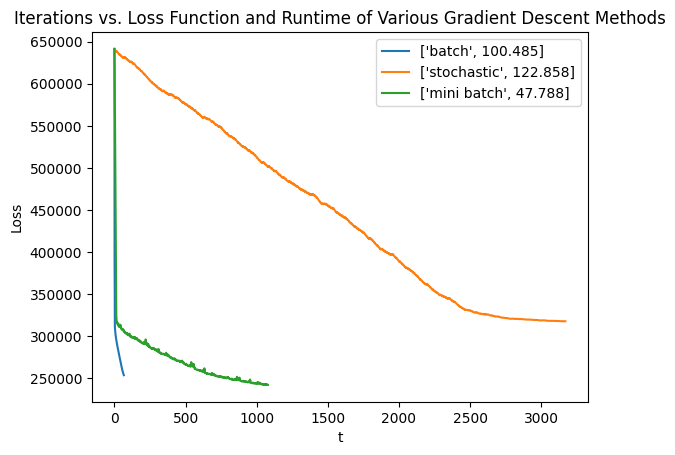

In [23]:
plt.plot(grad_loss)
plt.plot(stoch_loss)
plt.plot(mb_loss)
plt.xlabel("t")
plt.ylabel("Loss")
plt.title("Iterations vs. Loss Function and Runtime of Various Gradient Descent Methods")
leg = [["batch", round(grad_time,3)], ["stochastic", round(stoch_time,3)], ["mini batch", round(mb_time,3)]]
plt.legend(leg)

#### Solution

First, it's important to be clear in regards to runtime vs iteration count. It is to be expected that the more information we use per iteration (i.e larger batch size), the fewer iterations it will take to get a result, at the cost of more computations per iteration. This clearly seems to balance out for the case of mini batch and stochastic (with the settings I used), but has a much bigger impact on batch, where iterations are very low but computation time is very high.

As expected, the stochasitc plot has a very constant, linear downward direction towards its point of convergence, which we can infer would be around where the mini batch plot is near and where the batch plot stopped short of. This, I admit, is due to poor implimentation on my part, but I'm uncertain where I specifically went wrong. The other two plots are about what we expect: a sharp downward drop into a smoothing convergence, like what we see with the mini batch plot.




---



---

## Multinomial Naive Bayes

Implement a multinomial naive Bayes classifier in the `NaiveBayes` class.  Your implementation should support add-one smoothing. Whether or not to use add-one smoothing is controlled via an argument to the constructor; add-one smoothing is enabled by default.

-  `__init(useAddOneSmoothing=True)__` : constructor.

- `fit(X,Y)`: method to train the naive Bayes model.

- `predict(X)`: method to use the trained naive Bayes model for prediction.

- `predictProbs(X)`: outputs a matrix of predicted posterior class probabilities.


The training data for multinomial naive Bayes is specified as feature counts: `X[i,j]` is the number of times
feature $j$ occurs in instance $i$ (or you can think of it as that instance $i$ is characterized by a particular
real-valued amount of feature $j$).

We are here using the multinomial distribution. Suppose our dataset has $D$ features and $K$ classes. Then the
multinomial distribution for a particular sample $(\mathbf{x},y)$, where $\mathbf{x}=[x_1,\dots, x_D]\in \mathbb{R}^D$, $x_j\in\mathbb{N}$ for $j=1,\dots, D$ and $y\in \{1,\dots, K\}$ is
\begin{align}
p(\mathbf{x}|y) = \frac{(\sum_j x_j)! }{x_1! x_2! \dots x_D!} p_{y1}^{x_1}p_{y2}^{x_2}\dots p_{yD}^{x_D}
\end{align}
and the label distribution $p(y)$ (in this case, a categorical distribution) is $\boldsymbol{\pi}=[\pi_1, \dots, \pi_K]$.

The naive Bayes assumption (that each instance is independent given the class label) is used in the sense that
that we are assuming the generative process is

- Picking a class $y$ according to the label distribution
$p(y)$.

- Generate a sequence of features, independently according to a multinomial distribution conditioned on the class $y$: $\mathbf{p}_y=(p_{y1}, p_{y2}, \dots, p_{yD})$ with $\sum_j p_{yj}=1$.

What you are given is the count of each feature generated by this process stored in a vector $\mathbf{x}$. This is a useful model for predicting, say, document classes, where $d$ is size of vocabulary
and $K$ is number of document classes.

The MLE parameter estimation for this naive Bayes probabilistic model is
- The label distribution $\hat{p}(y)=\hat{\boldsymbol{\pi}}$
\begin{align}
\hat{\boldsymbol{\pi}} = \frac{N_c}{N}
\end{align}
where $N_c$ is the number of samples with label $y=c$ and $N$ is the total samples.

- The multinormial distribution with label $y=c$ is $\hat{\mathbf{p}}_c=[\hat{p}_{c1}, \dots, \hat{p}_{cD}]$ and
\begin{align}
\hat{p}_{cj}  =\frac{N_{cj}}{N_c}
\end{align}
where $N_{cj}$ is total occurrences of feature $j$ in samples with label $y=c$.


- When using add-one smoothing, we estimate $\hat{p}_{cj} $ with
\begin{align}
\hat{p}_{cj}  = \frac{N_{cj}+1}{N_c +D}
\end{align}

During prediction, given feature count vector $\mathbf{x}$, we estimate label $y$ posterior probability with
\begin{align}
\hat{p}(y|\mathbf{x})\propto \hat{p}(y)\hat{p}_{y1}^{x_1}\hat{p}_{y2}^{x_2}\dots \hat{p}_{yD}^{x_D}
\end{align}
up to normalization. You might want to implement the equation above with summation of log probabilities
for better numerical stability. If you choose to do so, you would need another **numerical trick** below.

After
obtaining the log probabilities for each classes, $\mathbf{z}=\left[\begin{array}{ccccccccc}\log \hat{p}(y=1|\mathbf{x}),\log \hat{p}(y=2|\mathbf{x}), \dots, \log \hat{p}(y=K|\mathbf{x}) \end{array}\right]$. The actual probability distribution to be output is
\begin{align}
p(y=c|\mathbf{x}) &=\frac{\exp(z_c)}{\sum_{c=1}^K \exp(z_c)}\\
&= \frac{\exp(z_c-z)}{\sum_{c=1}^K \exp(z_c-z)}
\end{align}
where $z=\max_c z_c$. Here we subtract $\max_c z_c$ from the log probabilities for better numerical stability.

The `predictProbs(X)` function takes in a matrix $X$ of $N$ instances and outputs an $N\times K$ matrix of posterior
probabilities. Each row $i$ of the returned matrix represents the posterior probability distribution over the $K$
classes for the $i$-th training instance. (Note that each row of the returned matrix will sum to 1.)

In [ ]:
class NaiveBayes:

    def __init__(self, useAddOneSmoothing=True, alpha=1):
        """
        Constructor
        """
        self.AOS = useAddOneSmoothing
        self.smoother = alpha

    def prior(self):
        """
        Solves for the priors \pi = P(y)
        Arguments:
            None
        Returns:
            \pi, a vector of size num_classes
        """
        p = np.zeros((self.num_classes,))
        for i in self.y:
            p[i] += 1
        return p/self.samples

    def fit(self, X, y):
        """
        Trains the model
        Arguments:
            X is a n-by-d numpy array
            y is an n-dimensional numpy array
        """

        ### baseline attributes and priors
        self.y = y
        self.samples, self.features = X.shape # m,d
        self.classes = np.unique(y)
        self.num_classes = self.classes.shape[0]
        self.priors = self.prior()


        ### distinct feature values per column
        self.unique_features = []
        for d in range(self.features):
            self.unique_features.append(np.unique(X[:,d]))


        ### counts
        self.N_cd = np.zeros((self.num_classes, self.features)) # count of feature i per c
        self.N_c = np.zeros((self.num_classes)) # total count of feautures per c

        for c in self.classes: # for each available y = c

            # get indices where class is c
            indices = []
            for i in range(self.samples):
                if c == self.y[i]:
                    indices.append(i)

            # get values of features where y = c
            temp_count = []
            for d in range(self.features):
                temp_count.append(np.sum(X[indices,d]))

            # adding to N_ci and N_c
            self.N_cd[c] = temp_count
            self.N_c[c] = np.sum(temp_count)


    def prod_theta(self, x_i, c):
        """
        Solves for theta_c = P(x_i|y=c) = P(x_0|y=c)*P(x_1|y=c)*...*P(x_D|y=c)
        Arguments:
            x_i is a sample of size self.features
        Returns:
            theta_c, an integer
        """
        # Add One Smoothing
        if self.AOS:
            self.smoother = 1
        else:
            self.smoother = 0

        value = 1
        for d in range(self.features):
            numer = self.N_cd[c,d] + self.smoother
            denom = self.N_c[c] + self.smoother*self.features
            value = value * ((numer/denom)**x_i[d])
        return value

    def log_theta(self, x_i, c):
        """
        Solves for log(theta_c) = log(P(x_i|y=c)) = log(P(x_0|y=c))+log(P(x_1|y=c))+...+log(P(x_D|y=c))
        Arguments:
            x_i is a sample of size self.features
        Returns:
            log(theta_c), an integer
        """
        if not self.AOS:
            self.smoother = 0

        value = 1
        for d in range(self.features):
            numer = self.N_cd[c,d] + self.smoother
            denom = self.N_c[c] + self.smoother*self.features
            value += np.log(((numer/denom)**x_i[d]))
        return value

    def predict(self, X, logLikelyhood=True):
        """
        Used the model to predict values for each instance in X
        Arguments:
            X is a n-by-d numpy array
        Returns:
            an n-dimensional numpy array of the predictions
        """
        ### prediction matrix y_hat
        test_samples = X.shape[0]
        self.prediction = np.zeros((test_samples,))

        ### calculating predictions for each sample x_i
        for i in range(test_samples):
            temp_likelyhood = np.zeros((self.num_classes,))

            # for logarithmic needs
            if logLikelyhood:
                for c in range(self.num_classes):
                    temp_likelyhood[c] = np.log(self.priors[c]) + self.log_theta(X[i,:], c)
            else:
                for c in range(self.num_classes):
                    temp_likelyhood[c] = self.priors[c]*self.prod_theta(X[i,:], c)

            # finding the most likely class
            max_index = np.argmax(temp_likelyhood)
            self.prediction[i] = self.classes[max_index]

        return self.prediction


    def predictProbs(self, X, logLikelyhood=True):
        """
        Used the model to predict a vector of class probabilities for each instance in X
        Arguments:
            X is a n-by-d numpy array
        Returns:
            an n-by-C numpy array of the predicted class probabilities (for C classes)
        """
        ### prediction matrix y_hat
        test_samples = X.shape[0]
        self.probabilities = np.zeros((test_samples, self.num_classes))

        ### calculating predictions for each sample x_i
        for i in range(test_samples):
            # for logarithmic needs
            if logLikelyhood:
                for c in range(self.num_classes):
                    self.probabilities[i,c] = np.log(self.priors[c]) + self.log_theta(X[i,:], c)
            else:
                for c in range(self.num_classes):
                    self.probabilities[i,c] = self.priors[c]*self.prod_theta(X[i,:], c)

        return self.probabilities

    def score(self, y):
        """
        Finds the accuracy of the predictions
        Arguments:
            y is a np array of size n, likely a testing set
        """
        n = len(self.prediction)
        error = self.prediction-y
        count = 0
        for i in error:
            if i == 0:
                count+=1
        return count/n

In [ ]:
#from sklearn import datasets
from sklearn.metrics import accuracy_score

# load the data set
dataset = datasets.load_digits()
X = dataset.data
y = dataset.target

n, d = X.shape
nTrain = int(0.5*n)  # training on 50% of the data

# shuffle the data
idx = np.arange(n)
np.random.seed(13)
np.random.shuffle(idx)
X = X[idx]
y = y[idx]

# split the data
Xtrain = X[:nTrain, :]
ytrain = y[:nTrain]
Xtest = X[nTrain:, :]
ytest = y[nTrain:]

print(Xtrain.shape)
print(ytrain.shape)
print(Xtest.shape)
print(ytest.shape)


(898, 64)
(898,)
(899, 64)
(899,)


In [ ]:
from sklearn.naive_bayes import MultinomialNB # as a check of my implimentation
"""
SKLEARN naiveBayes package
"""

sk_bayes = MultinomialNB()
sk_bayes.fit(Xtrain, ytrain)

print("Accuracy percent of sklearn Multinomial NBC is:", round(sk_bayes.score(Xtest, ytest),7))

Accuracy percent of sklearn Multinomial NBC is: 0.89099


In [ ]:
"""
My implimentation
"""

# train the naive Bayes
modelNB = NaiveBayes(useAddOneSmoothing=True)
modelNB.fit(Xtrain, ytrain)

# output predictions on the remaining data
ypred_NB = modelNB.predict(Xtest)

# calculate the posterior probability
yposterior_NB = modelNB.predictProbs(Xtest)

print("Accuracy percent of my implimentation of Multinomial NBC is:", round(modelNB.score(ytest),7))


Accuracy percent of my implimentation of Multinomial NBC is: 0.89099




---



---


## Decision Trees

In this question we are going to focus on decision trees, manually follow the algorithm, and investigate the decisions the algorithm makes. Our goal is to justify the steps of the algorithm and investigate the redundancy in the space of decision trees. Consider the following decision tree:


<img src="https://github.com/yexf308/MachineLearning/blob/main/homework/HW3/Decision_tree1.png?raw=true" width="400" />

### Drawing the Decision Boundaries
 Draw the decision boundaries defined by this tree. Each leaf of the tree is labeled with a letter. Write this letter in the corresponding region of instance space and label the axes. Your solution should look like Next Figure, where you will replace the boundary thresholds and labels based on the provided decision tree.

  <img src="https://github.com/yexf308/MachineLearning/blob/main/homework/HW3/Decision_tree2.png?raw=true" width="400" />

In [ ]:
!['Decision Bounds'](https://drive.google.com/uc?export=view&id=1xhTudA_9F3P5jVgXVpZd1m1__jwpcKm1)

/bin/bash: -c: line 1: syntax error near unexpected token `https://drive.google.com/uc?export=view'
/bin/bash: -c: line 1: `['Decision Bounds'](https://drive.google.com/uc?export=view&id=1xhTudA_9F3P5jVgXVpZd1m1__jwpcKm1)'



---

### Syntactic Redundancy
Give another decision tree that is different from decision tree in first Figure but defines the same decision boundaries. This demonstrates that the space of decision trees is syntactically redundant. Would this redundancy affect the accuracy of the learned trees? What are potential benefits of this redundancy? (i.e., Does it increase the computational complexity of finding an accurate tree?) Explain using 3-5 sentences.

In [ ]:
![](https://drive.google.com/uc?export=view&id=1AABvopogEiAN6TgmbbItNFttP0hgvcLL)

/bin/bash: -c: line 1: syntax error near unexpected token `https://drive.google.com/uc?export=view'
/bin/bash: -c: line 1: `[](https://drive.google.com/uc?export=view&id=1AABvopogEiAN6TgmbbItNFttP0hgvcLL)'


#### Solution

In this case, the trees only differ on when we decide to look at $x_2$, the first deciding after looking at $x_1$. The accuracy of either tree is only a matter of interpretation, and I would prefer to decide one feature at a time rather than reaccessing information about, say $x_1$, after already making a decision on it. Computationally, if we were to use the first tree as our model, we would be checking $x_1$ twice, where with proper implimentation and a three-leaf tree, we would only have to check each $x_1$ once.

As for benefits to the redundancy, it could be the case that over half of the sample has $x_1>25$, thus it would be wise to check it first to decrease overall computation time. Either way, I don't believe (for this particular example) that the accuracy of the tree changes much in regards to either displayed tree.



---


### Splitting on Information Gain
Consider the training samples in next Figure, where A, B, C denote three different features and Y denotes the output we want to predict:


<img src="https://github.com/yexf308/MachineLearning/blob/main/homework/HW3/Decision_tree3.png?raw=true" width="200" />

What feature would be chosen for the split at the root of a decision tree using the Information Gain criterion? Please show your calculations and explain your reasoning. What is the relationship between the selected feature and outcome Y?

#### Solution

We pick the feature with the highest information gain, with respect to ID3, which turns out to be feature $C$. From a glance, we can see $C$ and $Y$ have an inverse relationship.

$$
\begin{align*}
H(\mathcal{S}) &= -\sum_{i=1}^k p_i\log_2 p_i\\
&= -\frac{3}{6}\log_2\frac{3}{6} - \frac{3}{6}\log_2\frac{3}{6}\\
&= \frac{1}{2} + \frac{1}{2}\\
&= 1\\
\\
H(\mathcal{S}|A) &= \sum_{a\in A} \frac{|\mathcal{S}_a|}{|\mathcal{S}|}H(\mathcal{S}_a)\\
&= -\frac{3}{6}*(\frac{1}{3}\log_2\frac{1}{3}) - \frac{3}{6}*(\frac{2}{3}\log_2\frac{2}{3})\\
&≈ .459 \\
\text{IG}(\mathcal{S}, A) &= H(\mathcal{S}) - H(\mathcal{S}|A) = 1 - .459 = .541\\
\\
H(\mathcal{S}|B) &= \sum_{b\in B} \frac{|\mathcal{S}_b|}{|\mathcal{S}|}H(\mathcal{S}_b)\\
&= -\frac{4}{6}*(\frac{2}{4}\log_2\frac{2}{4}) - \frac{2}{6}*(\frac{1}{2}\log_2\frac{1}{2})\\
&= .5 \\
\text{IG}(\mathcal{S}, B) &= H(\mathcal{S}) - H(\mathcal{S}|B) = 1 - .5 = .5\\
\\
H(\mathcal{S}|C) &= \sum_{c\in C} \frac{|\mathcal{S}_c|}{|\mathcal{S}|}H(\mathcal{S}_c)\\
&= -\frac{3}{6}*(\frac{0}{3}\log_2\frac{0}{3}) - \frac{3}{6}*(\frac{3}{3}\log_2\frac{3}{3})\\
&= 0 \\
\text{IG}(\mathcal{S}, C) &= H(\mathcal{S}) - H(\mathcal{S}|C) = 1 - 0 = 1\\
\end{align*}
$$



---


### Random Splitting: Non-Empty Child Nodes
In the basic decision tree algorithm, we choose the feature/value pair with the maximum Information Gain (i.e., $IG(Y |X ) = H (Y ) − H (Y |X ))$ as the criterion to use at each internal node of the decision tree. Suppose we modified the algorithm to choose at random from among those feature/value combinations that had non-zero information gain, but that we kept all other parts of the algorithm unchanged.

Prove that if a splitting feature/value combination has non-zero information gain at an internal node, then at least one training example must be sent to each of the child nodes.

**Hint:** You may prove the contrapositive of the statement instead, that is, if all examples are sent to one of the child nodes (they have the same feature/value pair) then the information gain is zero.


#### Solution

We choose to prove the contrapositive. Let $\mathcal{S} = \{1,2,...,k\}$ be samples and $F = \{f_1, f_2, ..., f_{t}\}$ be options for a feature $F$ such that, WLOG, $\forall s\in\mathcal{S}, s\in\mathcal{S}_{f_1}.$ Thus, $\mathcal{S}\subset \mathcal{S}_{f_1}$, but by definition, $\mathcal{S}_{f_1}\subset \mathcal{S}$, so $\mathcal{S} = \mathcal{S}_{f_1}.$

Then, we have the following:
$$
\begin{align*}
H(\mathcal{S}|F) &= \sum_{f\in F} \frac{|\mathcal{S}_f|}{|\mathcal{S}|}H(\mathcal{S}_f)\\
&= \frac{|\mathcal{S}_{f_1}|}{|\mathcal{S}|}H(\mathcal{S}_{f_1}) + \frac{|\mathcal{S}_{f_2}|}{|\mathcal{S}|}H(\mathcal{S}_{f_2}) + ... + \frac{|\mathcal{S}_{f_t}|}{|\mathcal{S}|}H(\mathcal{S}_{f_t})\\
&= \frac{k}{k}H(\mathcal{S}_{f_1}) + \frac{0}{k}H(\mathcal{S}_{f_2}) + ... + \frac{0}{k}H(\mathcal{S}_{f_t})\\
&= 1*H(\mathcal{S}_{f_1}) + 0 + ... + 0\\
&= H(\mathcal{S}_{f_1})\\
&= H(\mathcal{S})\\
\\
\text{IG}(\mathcal{S}; F) &= H(\mathcal{S})- H(\mathcal{S}|F)\\
&= H(\mathcal{S})- H(\mathcal{S})\\
&= 0 \\
\blacksquare
\end{align*}
$$

This is equivalent to the above statement that if a splitting feature/value combination has non-zero information gain at an internal node, then at least one training example must be sent to each of the child nodes.



---


### Random Splitting: Effect on Accuracy and Tree Size
How do you think this change (i.e., choosing at random from among those feature/value combinations that have non-zero information gain) would affect the accuracy of the decision trees produced on average? To achieve the same accuracy, how are the trees different (e.g. size) on average? Why? Explain using 3-5 sentences.

#### Solution

Since there is no sense of quantifying which features are important, we must sort through each and every choice of each feature before we can be certain that we have finished the tree. Because of this, we will be accurate, but have massive amounts of overfitting and, if there are $k$ features $F$, where $F_i = \{ f_1, f_2,..., f_{j_i}\}$, then we will have a height of at least $k$ and number of decisions equal to $\prod_{i=1}^k|F_i|-1$, which can get quite large if $k$ and/or the $j_i$'s become large and become a bore to understand at a glance.

In other words, without a stopping threshold, we will have an extremely large runtime and have massive overfitting issues (massive tree size, etc.), but with a stopping threshold, we have the potential to lose out on accuracy if we don't randomly select any high information-gain features, which cannot be guarenteed. The same can be done for a ID3 derived tree by just decreasing the stopping threshold with a guarentee of getting high information-gain features in the tree first, leading to a more informative tree altogether.



---

# Part IV — Unsupervised Learning

Structure without labels: Lloyd's algorithm on MNIST, K-medians on NYC taxi data, and Gaussian mixtures fit by EM.


In [ ]:
%pylab inline
import pandas as pd
import scipy
import numpy as np
from scipy import linalg
import matplotlib.pyplot as plt

Populating the interactive namespace from numpy and matplotlib


---



## Note on These Implementations

For Q1, I took it upon myself to try my own implimentation of the K-means, which turned out to work most of the time, albeit has some issues generating clusters for higher $K$. While my answers could be wrong, I care more about trying it for myself rather than knowing the response will be correct and not learning as much.

For Q2, I used the lecture code to run things more efficiently, trying my best to learn from what was done in lecture, v.s my implimentation.

For Q3.5, again I used the lecture code, but in hindsight, it wasn't as necessary to do so. (also only worth 5 points)


---


---



## K-Means Clustering

In K-means, we are given dataset $\{\mathbf{x}^{(1)}, \dots,\mathbf{x}^{(N)} \}\subset \mathbb{R}^d$ and the number of clusters $K$, and we are trying to optimize the distortion value
$$J = \sum_{i=1}^N\sum_{j=1}^K r_{ij}\|\mathbf{x}^{(i)}-\mu_j\|_2^2$$
where $r_{ij}\in \{0,1\}$ is an indicator variable
$r_{ij}=1 \text{ if and only if } \mathbf{x}^{(i)}\in \mathcal{C}_{j}$. For each $i$, there is one and only one $j$ such that $r_{ij}=1$, i.e., the membership for $\mathbf{x}^{(i)}$ is unique.




### Alternating Optimization Steps

- Fix $\{\mu_j\}$ and minimize over $\{r_{ij}\}$, **show** the solution for $r_{ij}$ is

$$r_{ij} = \begin{cases} 1 & \text{if } j= \text{arg}\min_k \|\mathbf{x}^{(i)}-\mu_k\|_2^2 \\ 0 & \text{Otherwise}\end{cases}$$

- Fix $\{r_{ij}\}$ and minimize over $\{\mu_j\}$, **show** the solution for $\mu_j$ is  
$$\mu_j=\frac{\sum_i r_{ij}\mathbf{x}^{(i)}}{\sum_i r_{ij}}$$

Please show your derivation.




#### Solution

1) Fix $\mu_{j'}\in \{\mu_{j}\}$ and assume $J$ is minimal. By the assertion that for each $i$, there is one and only one $j$ such that $r_{ij}=1$,  we consider some $i'$ s.t. $J_{i'} = \sum_{j=1}^K r_{i'j}\|\mathbf{x}^{(i')}-\mu_j\|_2^2 = r_{i'j'}\|\mathbf{x}^{(i')}-\mu_{j'}\|_2^2,$ where $j'$ is the only such $j$ where $r_{i'j} = 1.$ By the assumption that $J$ is minimal, $J_{i'}$ is minimal, so we must have that $\|\mathbf{x}^{(i')}-\mu_{j'}\|_2^2$ is minimal for our choice of $j$, i.e. $j' = \text{arg}\min_{k \in \{ 1,2,...,K\}} \|\mathbf{x}^{(i)}-\mu_k\|_2^2.$ Thus,

$$r_{ij'} = \begin{cases} 1, & \text{if } j' = \text{arg}\min_k \|\mathbf{x}^{(i)}-\mu_k\|_2^2 \\ 0, & \text{Otherwise}\end{cases}$$

$$
\\
\\
$$

2) Fix $\{r_{ij}\}$ and assume $J$ is minimal. Consider some set $I$ s.t. $\forall i\in I,$ $J_{i}$ is minimal for some $j_i$. By the assertion that for each $i$, there is a unique $\mathbf{x}^{(i)}$ corresponding to $r_{ij_i}=1,$ we set $S_I = \{\mathbf{x}^{(i)}\}_{i\in I}$, where for some $i' \in I,$ there is an $\mathbf{x}^{(i')} \in S_I$. Thus, $|S_I| = |I| = \sum_{i\in I} r_{ij}$.

By the definition of $\mu_j$, we have $$\mu_j = \frac{\sum_{\mathbf{x}\in S_I} \mathbf{x}}{|S_I|} = \frac{\sum_{i\in I} \mathbf{x}^{(i)}}{|I|} = \frac{\sum_{i\in I} r_{ij}\mathbf{x}^{(i)}}{\sum_{i\in I} r_{ij}}$$





---


### Implementation on MNIST
The objective function in  K-means to minimize is
$$ \min_{\mu\in\mathbb{R}^{d\times K}}\sum_{j=1}^K \sum_{\mathbf{x}^{(i)}\in \mathcal{C}_j}\|\mathbf{x}^{(i)}-\mu_j\|^2$$

The Lloyd’s algorithm, the commonly-used heuristic which we discussed in lecture, typically works well to minimize this objective function. You need to use the function implemented in class.

In [ ]:
from keras.datasets import mnist
(train_X, train_y), (test_X, test_y) = mnist.load_data()
Xtr                   = train_X[0:6000, :]
train_y_part          = train_y[0:6000]
Xte                   = test_X[0:1000,:]
test_y_part           = test_y[0:1000]

n = Xtr.shape[0]
d = Xtr.shape[1]*Xtr.shape[2]
X_train = np.zeros((n,d))
for i in range(n):
    X_train[i] = Xtr[i].reshape((d,))

n_test = Xte.shape[0]
X_test = np.zeros((n_test,d))
for j in range(n_test):
    X_test[j] = Xte[j].reshape((d,))

Run the Lloyd's algorithm on the training dataset of MNIST with $K = 10$, plotting the objective function as a function of the iteration number.  Visualize (and include in your report) the cluster centers as a $28 \times 28$ image.

In [ ]:
from itertools import repeat

def get_initial_mu(K,d):
    '''
    returns an array of K mu vectors of size d to use as the initial
    cluster centers for the first iteration of Llyod's Algorithm.

    Input:
        K (int) - the number of clusters
        d (int) - the size of a single sample vector
    Output:
        a Kxd numpy array
    '''

    return_array = np.zeros((K,d))
    for k in range(K):
        # uses just a random selection from [0,1]
        temp = np.random.rand(d)
        return_array[k] = temp
    return return_array

def cluster_assignment(X, mu_array):
    '''
    returns the clustering of all x given a set of cluster centers
    as well as the distortion value J.

    Input:
        X ((n,d) array) - array of training data
        y ((n,1) array) - array of training data "solutions" (used later)
        mu_array ((K,d) array) - array of K cluster centers
    Output:
        list of size K, where each element is a subset of X
        list of size N, where each element is the class min_j,
            aligning with the samples in X
        float J, distortion of the clustering
    '''

    K, d = mu_array.shape
    cluster_array = [[] for i in repeat(None, K)]
    index_list = []

    J = 0

    # finding where each x belongs
    for x in X:
        min_dist = np.infty

        # find which cluster x belongs to
        for j in range(K):
            temp_dist = linalg.norm(x-mu_array[j])**2
            if temp_dist < min_dist:
                min_dist = temp_dist
                min_j = j
        # put x in cluster
        cluster_array[min_j].append(x)
        J += linalg.norm(x-mu_array[min_j])**2
        index_list.append(min_j)

    return cluster_array, index_list, J

def get_centers(clusters, K, d):
    '''
    returns new cluster centers given a set of clusters

    Input:
        clusters - list of K disjoint subsets of X
        K (int) - the number of clusters
        d (int) - the size of a single sample vector
    Output:
        a Kxd numpy array
    '''
    centers = np.zeros((K,d))

    for j in range(len(clusters)):
        cluster = clusters[j]
        sum = np.zeros((d,))
        for x in cluster:
            sum = sum + x
        centers[j] = sum/len(cluster)

    return centers


In [ ]:
K = 10
n, d = X_train.shape

# initialization
mu = get_initial_mu(K,d)
distortion_list = []

# stopping variables
iter = 0
# setting ratio to 1 means we stop when distortions are equal (no change)
ratio_stop_value = 1
max_iterations = 100
max_iter_reached = True

# loop has two exits: either the last two distortion values are equal (or close to equal)
# OR the iterations reaches the max iterations
while iter < max_iterations:

    # updating clusters using centers
    clusters, index_list, J = cluster_assignment(X_train, mu)
    distortion_list.append(J)

    # updating centers using clusters
    mu = get_centers(clusters, K, d)

    # stopping criterion - checks ratio of current and previous distortion
    # values and stops if above "ratio_stop_value"
    n = len(distortion_list)
    if n > 1:
        if distortion_list[n-1]/distortion_list[n-2] >= ratio_stop_value:
            max_iter_reached = False
            break

    # iteration
    iter += 1

if max_iter_reached:
    print("Max iterations reached.")
    print("Number of iterations:", iter)
else:
    print("Stopping Criterion met!")
    print("Number of iterations:", iter)


Stopping Criterion met!
Number of iterations: 54


Text(0.5, 1.0, 'Distortion of MNIST K-Means')

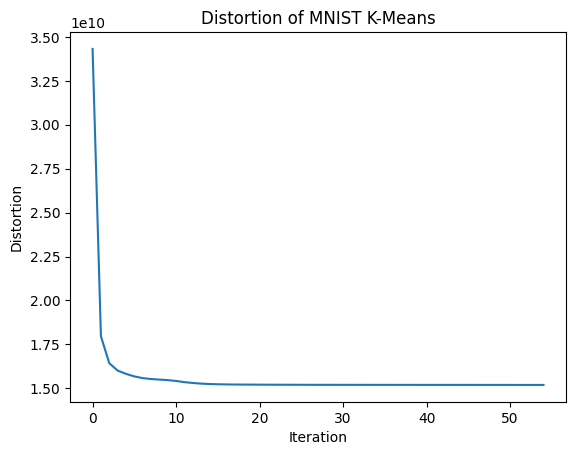

In [ ]:
plt.plot(distortion_list)
plt.xlabel("Iteration")
plt.ylabel("Distortion")
plt.title("Distortion of MNIST K-Means")

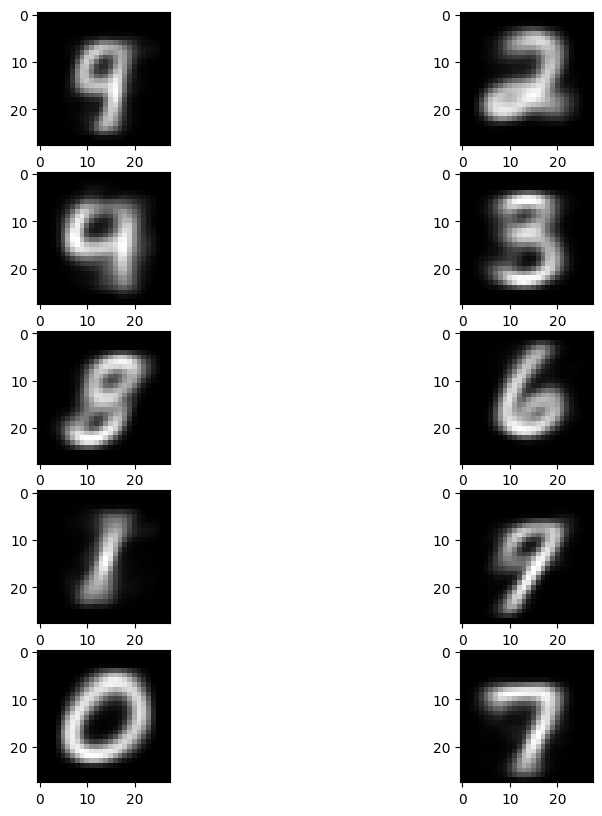

In [ ]:
mu = mu.reshape(K,28,28)

fig, axs = plt.subplots(5, 2,figsize=(10,10))
axs = axs.ravel()

for i in range(K):
    axs[i].imshow(mu[i], cmap=plt.get_cmap('gray'))



---


### Choosing $K$ on MNIST
For $K = \{2, 4, 8, 16, 32\}$, run the  Lloyd's  algorithm on the training dataset to obtain centers $\{\mu_j\}_{j=1}^K$. If $\{\mathbf{x}^{(i)}, y^{(i)}\}_{i=1}^{6000}$ and $\{\mathbf{x}'^{(j)}, y'^{(j)}\}_{j=1}^{1000}$ denote the training and test sets, respectively, plot the training error and test error (defined below) as a function of $K$ on the same
plot.
\begin{align}
&\text{Training Error: } \frac{1}{6000}\sum_{i=1}^{6000} \min_{k=1,\dots,K} \|\mu_k -\mathbf{x}^{(i)}\|_2^2\\
& \text{Testing Error: } \frac{1}{1000}\sum_{j=1}^{1000} \min_{k=1,\dots,K} \|\mu_k -\mathbf{x}'^{(j)}\|_2^2\\
\end{align}

You need to use the function implemented in class.

In [ ]:
def error(X, centers, K):

    error = 0
    for x in X:
        min_val = np.infty
        for k in range(K):
            temp = linalg.norm(x-centers[k])**2
            if linalg.norm(x-centers[k])**2 < min_val:
                min_val = temp
                min_k = k
        error += min_k
    return error/len(X)

k_list = [2,4,8,16,32]

n, d = X_train.shape

error_list = []

# doesn't work sometimes due to randomness of the initialization of mu
# on K = 32 for some reason (getting NaN/inf error). Probably would do well
# to impliment the hueristical initialization (kmeans++)
for K in k_list:

    mu = get_initial_mu(K,d)
    distortion_list = []

    iter = 0
    ratio_stop_value = 1
    max_iterations = 25

    while iter < max_iterations:

        clusters, index_list, J = cluster_assignment(X_train, mu)
        distortion_list.append(J)
        mu = get_centers(clusters, K, d)

        n = len(distortion_list)
        if n > 1:
            if distortion_list[n-1]/distortion_list[n-2] >= ratio_stop_value:
                max_iter_reached = False
                break

        iter += 1

    error_list.append([K, error(X_train, mu, K), error(X_test, mu, K)])


2
4
8
16
32


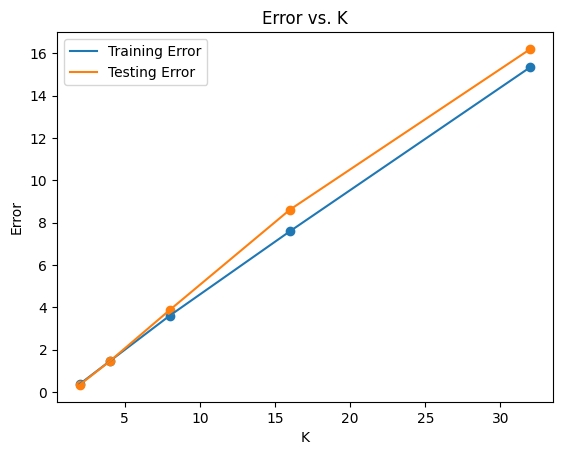

In [ ]:
a = len(k_list)
error_list = np.array(error_list).reshape((3,a))

plt.plot(error_list[0], error_list[1], label="Training Error")
plt.plot(error_list[0], error_list[2], label="Testing Error")
plt.scatter(error_list[0], error_list[1])
plt.scatter(error_list[0], error_list[2])
plt.xlabel("K")
plt.ylabel("Error")
plt.title("Error vs. K")
plt.legend()



---



---

## K-Medians for NYC Taxi Parking

As part of the effort of NYC to make its data publicly available and accessible, the city releases every month the full list of all taxi rides around the city. We will be using the dataset from January 2016, which can be found [here](https://www1.nyc.gov/site/tlc/about/tlc-trip-record-data.page).

The full dataset includes over 10M taxi rides. In our course, we will be using a smaller subset of this dataset with only 100k rides (which has also been cleaned up a bit). We will start by loading the data and printing the 10 first rows.

In this homework we will only be interested in the following columns:

- **dropoff_easting** - The horizontal coordinate (east-west) (in UTM-WGS84 (~ in kilometers))
- **dropoff_northing** - The vertical coordinate (north-south) (in UTM-WGS84 (~ in kilometers))

(A full description for each of the other columns can be found [here](https://www1.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_yellow.pdf))

Define the $2\times N$ array $X$ of drop off locations.

In [ ]:
!wget https://github.com/yexf308/MAT592/raw/main/homework/HW3/nyc_taxi_rides.csv?raw=true -O nyc_taxi_rides.csv

--2024-11-10 19:15:12--  https://github.com/yexf308/MAT592/raw/main/homework/HW3/nyc_taxi_rides.csv?raw=true
Resolving github.com (github.com)... 140.82.113.3
Connecting to github.com (github.com)|140.82.113.3|:443... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://github.com/yexf308/MachineLearning/raw/main/homework/HW3/nyc_taxi_rides.csv?raw=true [following]
--2024-11-10 19:15:12--  https://github.com/yexf308/MachineLearning/raw/main/homework/HW3/nyc_taxi_rides.csv?raw=true
Reusing existing connection to github.com:443.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/yexf308/MachineLearning/main/homework/HW3/nyc_taxi_rides.csv [following]
--2024-11-10 19:15:12--  https://raw.githubusercontent.com/yexf308/MachineLearning/main/homework/HW3/nyc_taxi_rides.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.111.133, 185.199.109.133, ...
Connecting to raw.gi

In [ ]:
dataset = pd.read_csv('nyc_taxi_rides.csv')

## Print the number of rows in the data set
number_of_rows = len(dataset)
print('Number of rows in the dataset: N={}'.format(number_of_rows))

## Show the first 5 rows and last 5 rows
print(dataset.loc[0:4])
print(dataset.loc[number_of_rows-5:number_of_rows-1])



Number of rows in the dataset: N=100000
   passenger_count  trip_distance  payment_type  fare_amount  tip_amount  \
0                2       2.768065             2          9.5        0.00   
1                1       3.218680             2         10.0        0.00   
2                1       2.574944             1          7.0        2.49   
3                1       0.965604             1          7.5        1.65   
4                1       2.462290             1          7.5        1.66   

   pickup_easting  pickup_northing  dropoff_easting  dropoff_northing  \
0      586.996941      4512.979705       588.155118       4515.180889   
1      587.151523      4512.923924       584.850489       4512.632082   
2      587.005357      4513.359700       585.434188       4513.174964   
3      586.648975      4511.729212       586.671530       4512.554065   
4      586.967178      4511.894301       585.262474       4511.755477   

    duration  day_of_week  day_of_month  time_of_day  
0  11.516

In [ ]:
X = dataset[['dropoff_easting','dropoff_northing']].values
print('The first 10 rows in X are:\n{}'.format(X[:10, :]))

The first 10 rows in X are:
[[ 588.15511774 4515.18088924]
 [ 584.85048892 4512.63208213]
 [ 585.43418784 4513.17496388]
 [ 586.67153039 4512.55406531]
 [ 585.26247362 4511.75547748]
 [ 585.16897267 4511.54010337]
 [ 588.71017492 4514.20918449]
 [ 585.84396658 4509.54508925]
 [ 583.67108081 4507.73557339]
 [ 587.7012478  4513.70969066]]


In [ ]:
X.shape

(100000, 2)

The following code plots the map of drop off points. The figure you got resembles the shape of the
streets in NYC: [map](https://www.google.com/maps/@40.7328589,-73.9545177,13z)

Text(0.5, 1.0, 'Dropoffs')

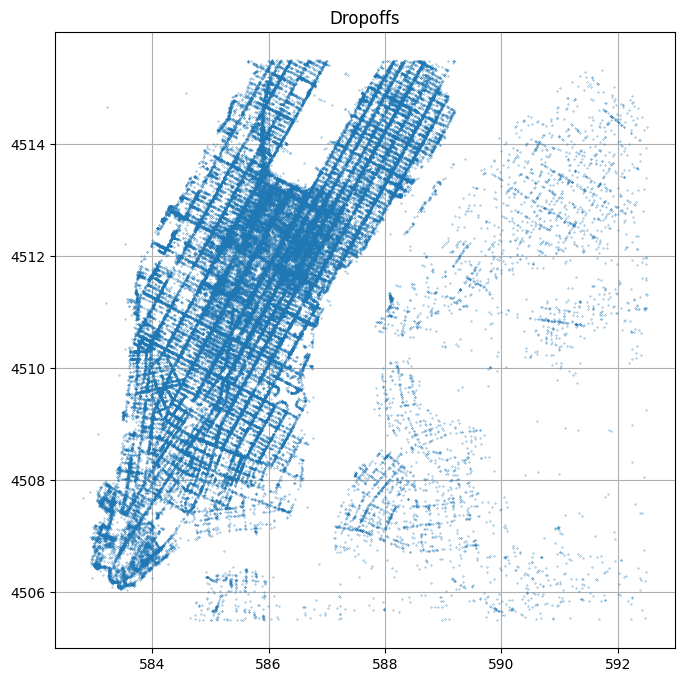

In [ ]:
## Plot the map
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(1, 1, 1)
ax.grid(True)
ax.plot(X[:, 0], X[:, 1], '.', markersize=0.5);
ax.set_title('Dropoffs')



---


### Finding the Optimal Lot Locations
A NY taxi company is looking to rent $K$ parking lots so that their taxis can wait in them in between rides.

It would like to select the optimal locations to place these parking lots such that the average distance from the drop off location to the nearest parking lot will be minimal.

In class, we have searched for the best $K$ locations which will minimize the $L_2$ (Euclidean) distances, but actually, in the case of NYC, it makes more sense to minimize the $L_1$ distance.

In order for the L1 distance to actually be the ride distance, we need to rotate the map such that the streets of NYC will be parallel to the axis.


---


#### Rotating the Map
Rotate the array of drop off points $x$ such that:
- The streets of NYC (going from South-East to North-West) will be parallel to the x axis
- The Avenues of NYC (going from South-west to North-East) will be parallel to the y axis.

Do so by constructing a rotation matrix, and multiply $x$ by that matrix to get the rotated drop off points.

Use the following:

- A normalized vector pointing in a direction parallel to the avenues of NYC:

$$
\boldsymbol{e}_1=\left(0.88, -0.47\right)^T
$$

- A normalized vector pointing in a direction parallel to the streets of NYC:
$$
\boldsymbol{e}_2=\left(0.47, 0.88\right)^T
$$

Make sure that that the streets are now more or less aligned to $x$ and $y$ axis.


(100000, 2)


Text(0.5, 1.0, 'Dropoffs')

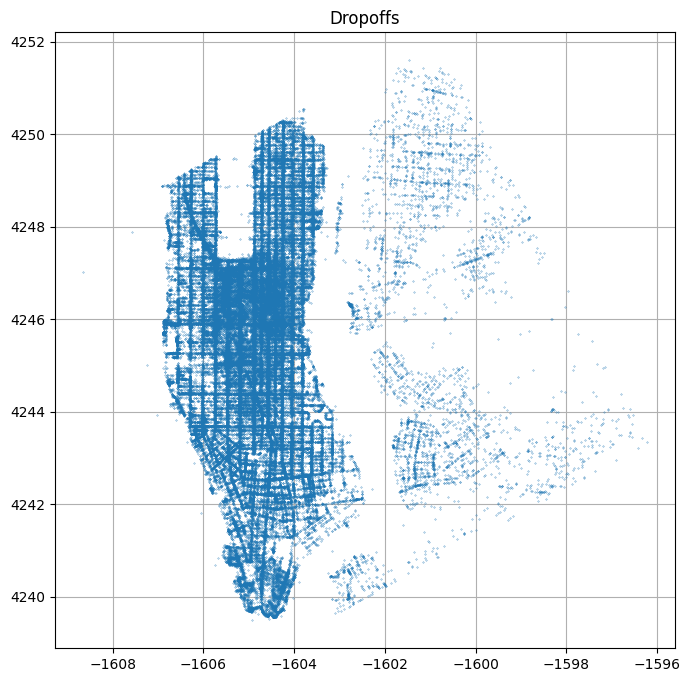

In [ ]:
n, d = X.shape
e = np.array([[0.88,-0.47], [.47, .88]]).T
X_rot = np.dot(X,e)
print(X_rot.shape)

## Plot the map
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(1, 1, 1)
ax.grid(True)
ax.plot(X_rot[:, 0], X_rot[:, 1], '.', markersize=0.5);
ax.set_title('Dropoffs')



---


#### The K-Medians Algorithm

Similar to the K-Means algorithm, which tries to minimize the sum of squared $L_2$ distances between each point and one of the $K$ centers, there is also a K-Medians algorithm which tries to minimize the sum of $L_1$ distances.

As we saw for the case of the $L_2$, the center point which minimizes the sum of squared $L_2$ distances from a given set of points, is the **mean** point of the given points.

Equivalently, the center point which minimizes the sum of $L_1$ distances from a given set of points is the point which is **median** (in each one of the axis) of the given points.

##### Differences from K-Means

The K-Medians algorithm differs from the K-means algorithm in the following way:

1. The assignment of each point the nearest center will now be based upon the $L_1$ distance instead of the $L_2$ distance.
2. The center will be now calculated using the Median value insted of Mean value.

(a) **Modify K-means code** so that it will implement the K-Medians algorithm with $K=5$. You may use `cdist` to speed up the calculation.

(b) Write a separate function to plot the clusters.



In [ ]:
import random

def plot_clusters(X,  centroids=np.array([[0,0]])):
    plt.scatter(X[:, 0], X[:, 1],  s=1, label='data points')
    plt.xlabel("$x_1$", fontsize=14)
    plt.ylabel("$x_2$", fontsize=14, rotation=0)
    if centroids[0].all():
      plt.scatter(centroids[:-1, 0], centroids[:-1, 1],
                  color = 'black', label = 'previously selected centroids')
      plt.scatter(centroids[-1, 0], centroids[-1, 1],
                  color = 'red', label = 'next centroid')
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
    plt.show()

def taxicab_distance(x1, x2):
    return np.sum(np.abs(x1 - x2))

# initialization for Kmeans++ algorithm
def initialize(X, K):

    ## Step 1: initialize the centroids list and add
    ## a randomly selected data point to the list
    n_samples, n_features = X.shape
    random_sample_idxs = np.random.choice(n_samples, 1, replace=False)
    centroids = X[random_sample_idxs,:]
    # plot_clusters(X,centroids)

    ## compute remaining K - 1 centroids
    for c_id in range(K - 1):
        ## Step 2: initialize a list to store distances of data
        ## points from nearest centroid
        ## compute distance of 'point' from each of the previously
        ## selected centroid and store the minimum distance
        dist = np.zeros(n_samples)
        for idx, sample in enumerate(X):
          distances     = [taxicab_distance(sample, point) for point in centroids]
          dist[idx]     = min(distances)

        ## Step 3: select data point with maximum distance as our next centroid
        next_centroid = X[np.argmax(dist), :]
        centroids=np.vstack([centroids,next_centroid])
        # plot_clusters(X,centroids)

    return centroids

def plot_kmeans(X,closest, centroids):
    fig, ax = plt.subplots(figsize=(12, 8))
    K = centroids.shape[0]

    for k in range(K):
       point = X[closest==k].T
       ax.scatter(*point)

    for point in centroids:
      ax.scatter(*point, marker="x", color="black", linewidth=2)

    plt.show()

def median_centroids(X, closest,K):
    centroids = np.zeros((K,2))
    for k in range(K):
        centroid = []
        for j in range(len(closest)):
            if closest[j] == k:
                centroid.append(X[j])
        centroid = np.asanyarray(centroid)
        centroids[k] = np.median(centroid, axis=0)

    return centroids

def mykmeans_plus(X, K, centroids, max_iter=100, plot_steps=False):

  distortion_list = []
  for i in range(max_iter):
    # step 1
    distances = (np.abs(X - centroids[:, np.newaxis])).sum(axis=2)
    distortion_list.append(sum(np.min(distances, axis=0)))
    closest   = np.argmin(distances, axis=0)
    centroids_old = centroids
    if plot_steps:
      plot_kmeans(X,closest, centroids)
    # step 2
    ###
    # centroids = np.array([X[closest==k].mean(axis=0) for k in range(K)])
    centroids = median_centroids(X_rot, closest, K)
    ###
    if plot_steps:
      plot_kmeans(X,closest, centroids)
    # step 3
    if sum(centroids-centroids_old) == 0.:
      print('Number of iteration is ', i+1)
      break

  print("plot for K =", K)
  plot_kmeans(X,closest, centroids)
  return centroids, closest, distortion_list

In [ ]:
K=5

parking_lot_locations, closest, distortion_list = mykmeans_plus(X_rot, K, initialize(X_rot, K))


Number of iteration is  24




---




### Choosing the Number of Lots



Now let us address the topic of selecting the number of parking lots (the number of clusters)

Basically, to reduce the average ride distance we would like as much parking lots as possible, but in practice operating a parking lots cost money. Let us assume that:

1. The price of operating a parking lot is 10k\$ per month.

2. There will be exactly 100k rides to the parking lots per month.

3. The estimated price per kilometer for when driving to the parking is estimated at 3\$ / kilometer.

Basically, we would now like to minimize the following risk function, which is the monthly cost (in k\$) of operating the parking lots plus the cost of driving to them:

$$
\hat{R}\left(\left\{\boldsymbol{c}_i\right\}, K\right)= 10\cdot K+3 \cdot 100\cdot\frac{1}{N}\sum_{i=1}^K\sum_{\boldsymbol{x}_j\in S_i}\left\lVert\boldsymbol{x}_j-\boldsymbol{c}_i\right\rVert_1
$$

Where:

- $K$ is the number of parking lots.
- $\left\{\boldsymbol{c}_i\right\}$ is the locations of the $K$ parking lots.
- $N$ is the number of rides in the dataset.
- $\left\{\boldsymbol{x}_i\right\}$ is the set of dropping points in the data set.
- $S_i$ is the set of dropping points which are assigned to the $i$-th parking lot.


---



#### Calculating Risk
Complete the following code to calculate for calculating the risk function.



In [ ]:
def calc_risk(parking_lots_locations, x, closest, cost_per_parking, cost_per_avarage_distance):
    n, d = x.shape
    K = parking_lots_locations.shape[0]

    risk = 10*cost_per_parking
    summand = np.zeros((K,))
    for j in range(n):
        k = closest[j]
        summand[k] += np.sum(np.abs(x[j]-parking_lots_locations[k]))
    return risk + (3*cost_per_avarage_distance/n)*np.sum(summand)

In [ ]:
cost_per_parking = 10
cost_per_avarage_distance = 300

risk = calc_risk(parking_lot_locations, X_rot, closest, cost_per_parking, cost_per_avarage_distance)
print(risk)

1266.8275614384863




---





#### Brute Force Optimization

We will find the optimal $K$ simply be checking all the relevant values of $K$. For this case, we will check all $K$'s between 1 and 30.

We will split data (80% train, 20% test) for selecting the optimal $K$.


Complete the following code to split the data and calculate the risks for $K=1,2,3,...,30$.

- For each $K$, use the training data to find the $K$ parking lots locations.

- Use the test dataset to calculate the risk.


Number of iteration is  2
plot for K = 1


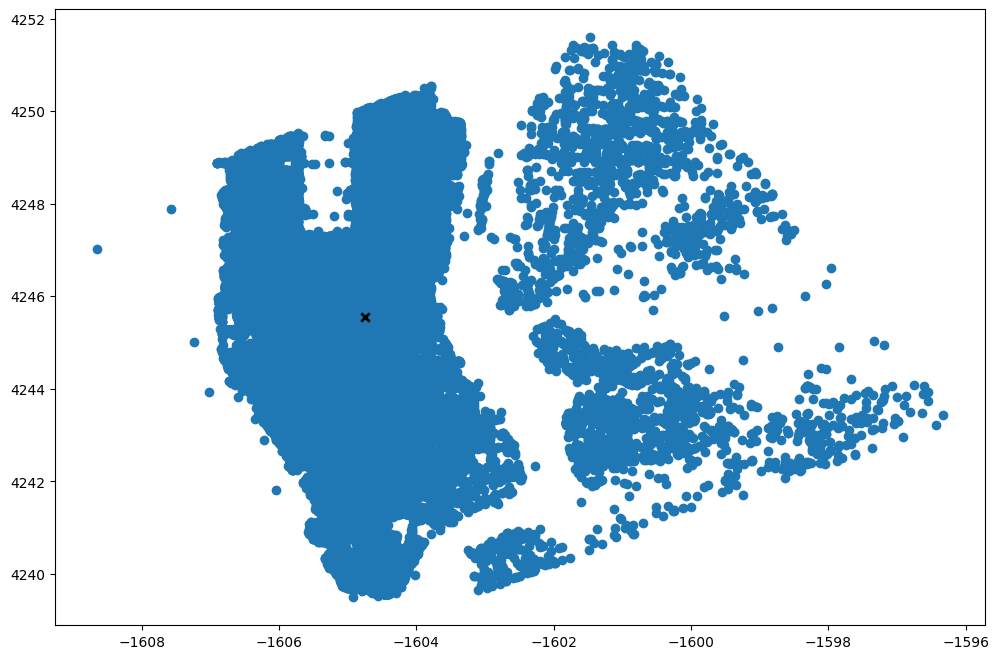

Number of iteration is  28
plot for K = 2


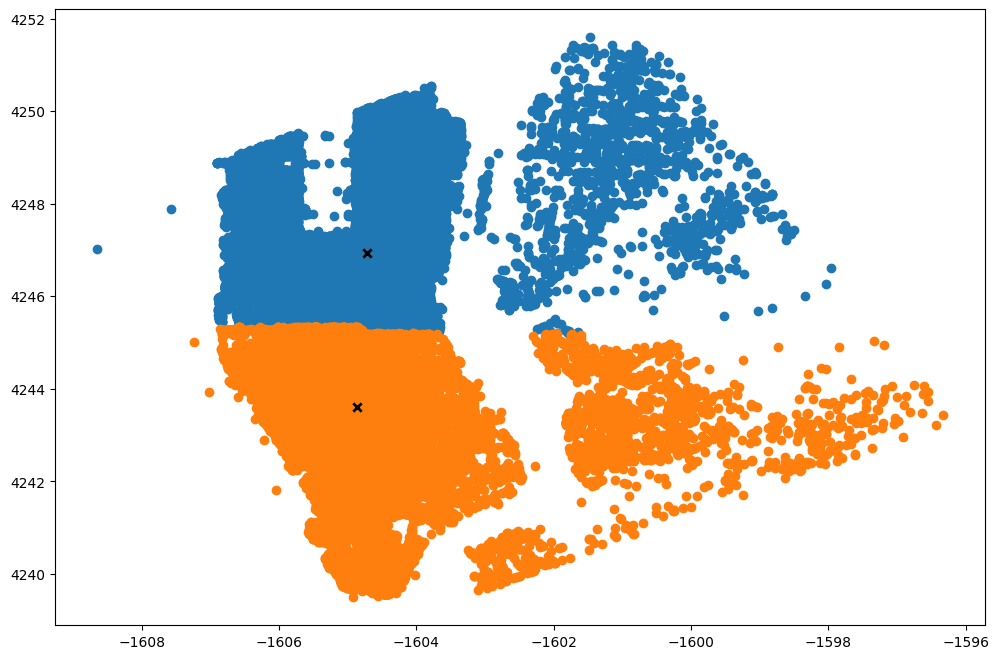

Number of iteration is  22
plot for K = 3


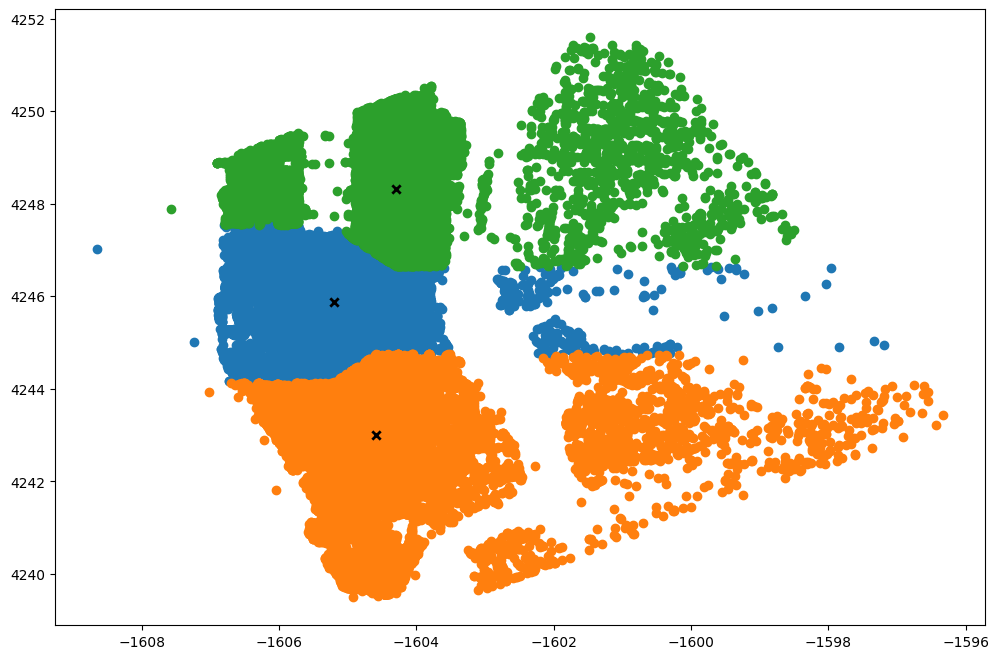

Number of iteration is  44
plot for K = 4


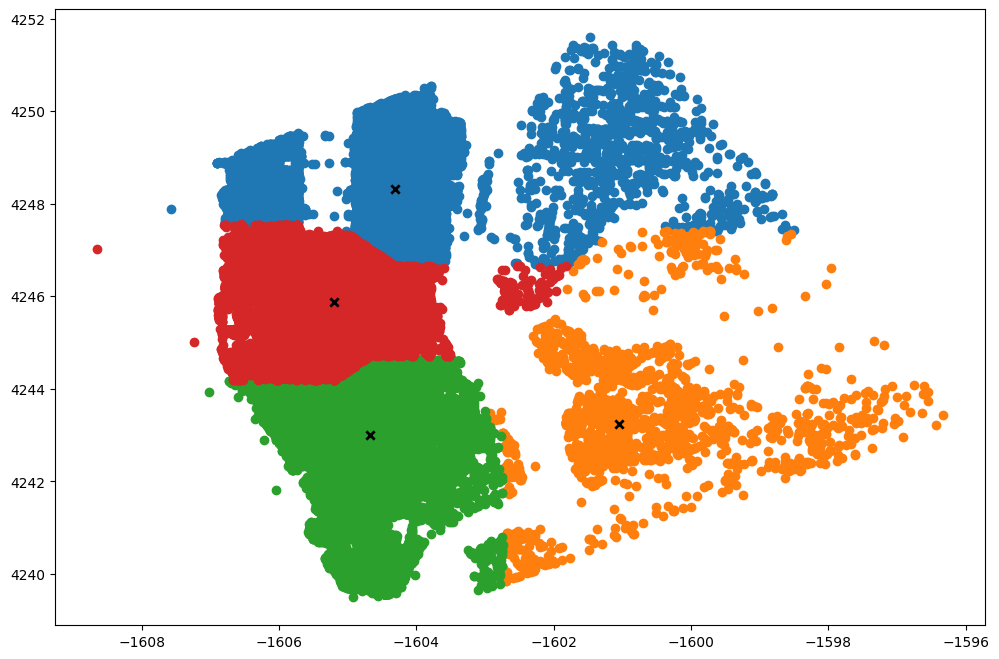

Number of iteration is  23
plot for K = 5


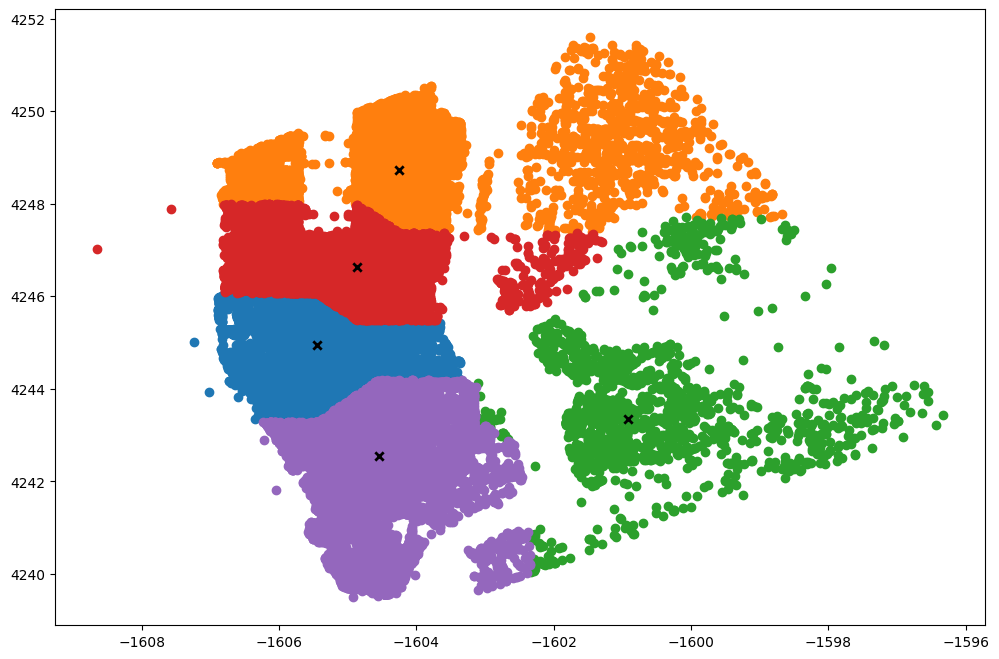

Number of iteration is  78
plot for K = 6


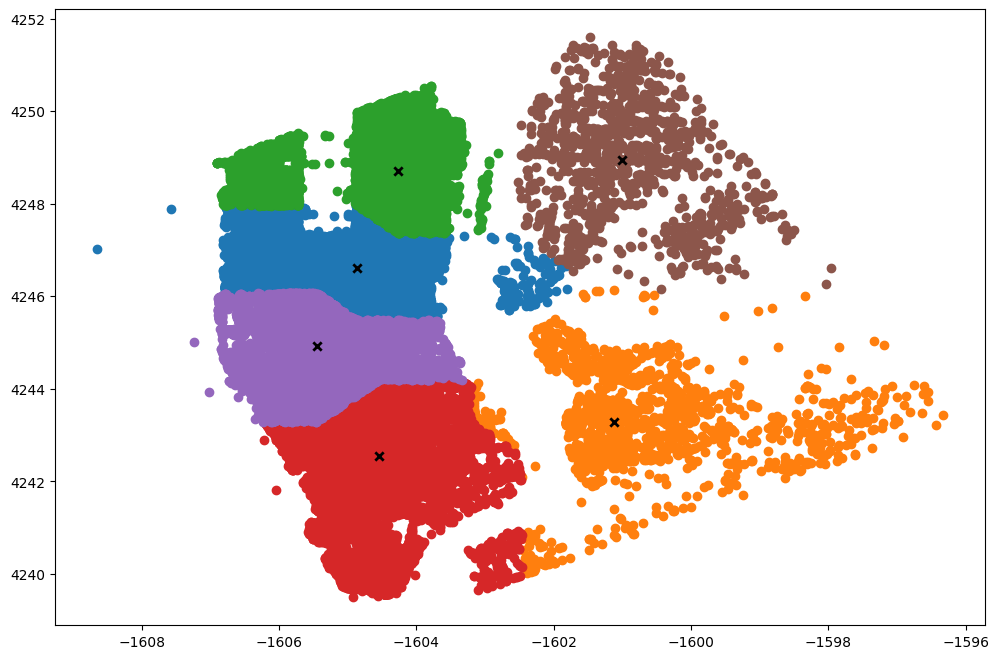

Number of iteration is  29
plot for K = 7


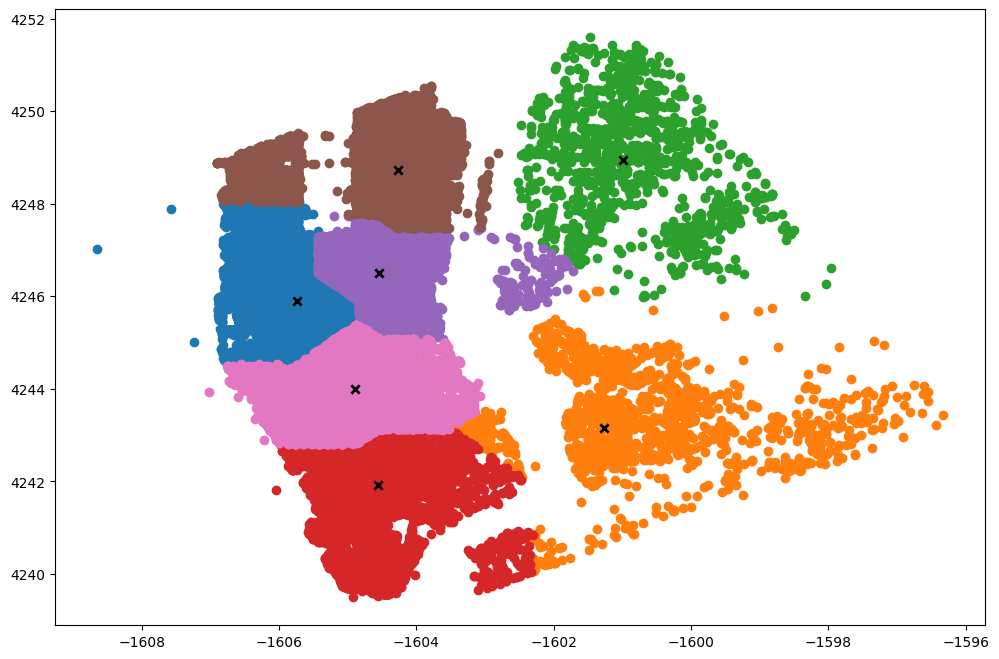

Number of iteration is  52
plot for K = 8


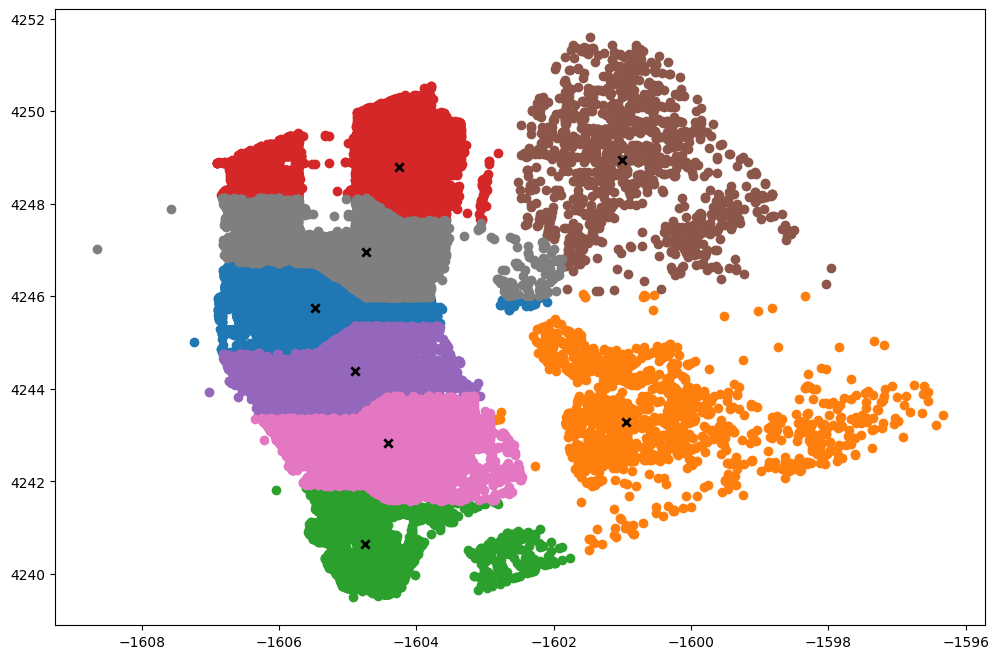

Number of iteration is  32
plot for K = 9


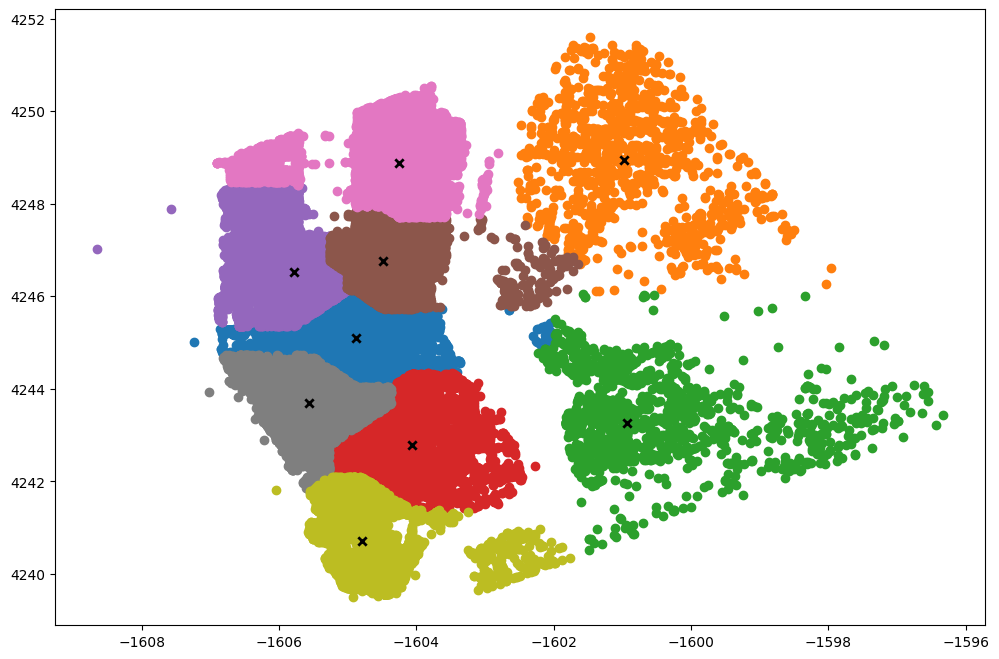

Number of iteration is  58
plot for K = 10


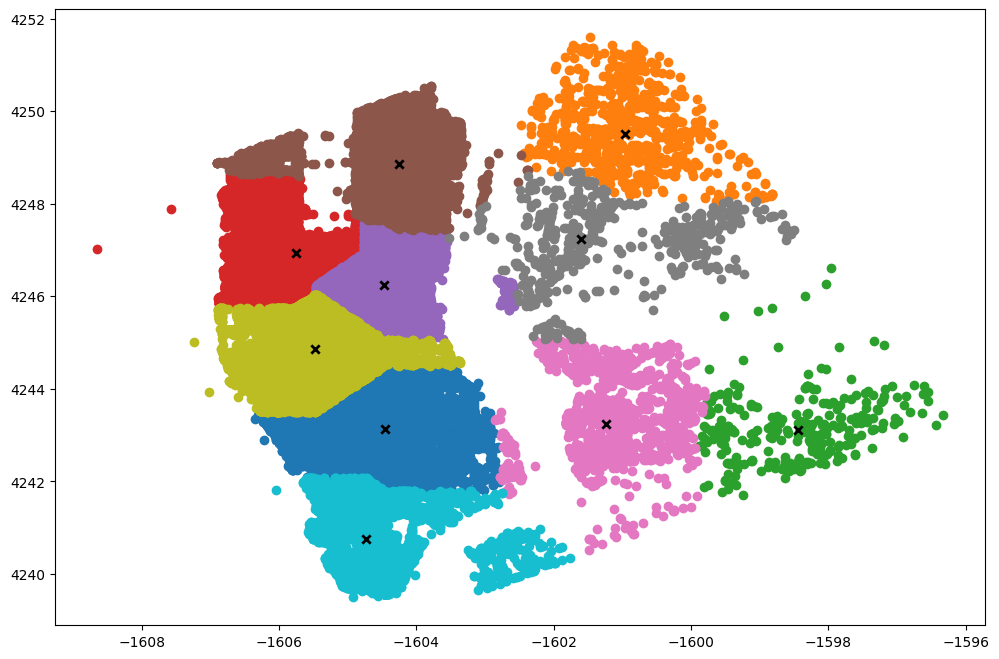

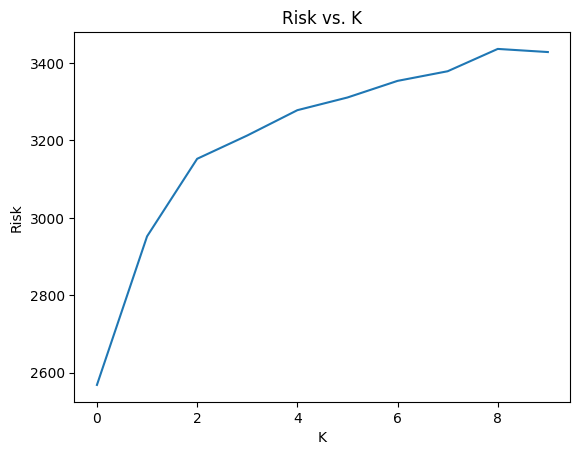

In [ ]:
n = X_rot.shape[0]
train_test_ratio = .8

X_rot_train = X_rot[:int(n*train_test_ratio)]
X_rot_test = X_rot[int(n*train_test_ratio):]

# code was taking forever
max_K = 10
K_list = range(1,max_K+1)
risk_list = []

for K in K_list:
    parking_lots_locations, closest, distortion_list = mykmeans_plus(X_rot_train, K, initialize(X_rot_train, K))
    risk_list.append(calc_risk(parking_lots_locations, X_rot_test, closest, cost_per_parking, cost_per_avarage_distance))

plt.plot(risk_list)
plt.xlabel("K")
plt.ylabel("Risk")
plt.title("Risk vs. K")
plt.show()



---



---



## Gaussian Mixture Models
### KL Divergence
In class, we defined the **Kullback-Leibler divergence** (or **KL divergence** for short) between two probability distributions $q$ and $p$,
$$ \text{KL}(q||p)=\sum_{z=1}^K q(z) \log\left( \frac{q(z)}{p(z)}\right)$$
where $\sum_{z=1}^K q(z)=1$ and $\sum_{z=1}^K p(z)=1$. For simplicity, assume $p(z)>0$ for all $z$.

Please show the following two key properties
- $\text{KL}(q||p)\ge 0$

- $\text{KL}(q||p)=0$ iff $p=q$.

#### Solution

1.

First, note that $\log a \leq a-1, \forall a>0$. From the fact that $q,p$ are probability distributions, we know they are non-negative $\forall z$. Then, using $\sum_{z=1}^K q(z)=1$ and $\sum_{z=1}^K p(z)=1$, we have the following:

\begin{align*}
- \text{KL}(q||p) &= - \sum_{z=1}^K q(z) \log\left( \frac{q(z)}{p(z)}\right)\\
&= \sum_{z=1}^K q(z) \log\left( \frac{p(z)}{q(z)}\right)\\
&\leq \sum_{z=1}^K q(z) (\frac{p(z)}{q(z)} - 1)\\
&= \sum_{z=1}^K p(z) - q(z)\\
&= \sum_{z=1}^K p(z) - \sum_{z=1}^K q(z)\\
&= 1 - 1\\
&= 0.
\end{align*}

So, $- \text{KL}(q||p) \leq 0$, therefore $\text{KL}(q||p) \geq 0$.

2.

($\Rightarrow$) Suppose $\text{KL}(q||p)=0.$ Then, $\forall z$, either $q(z)=0$ or $\log(\frac{q(z)}{p(z)}) = 0.$ Since $\sum_{z=1}^K q(z)=1,$ there must be a nonempty set of $z$'s where $q(z) \neq 0.$ $\forall z$ where $q(z) \neq 0,$ we have $\log(\frac{q(z)}{p(z)}) = 0 \Rightarrow \frac{q(z)}{p(z)} = 1 \Rightarrow q(z) = p(z)$. Since $p(z) > 0, \forall z,$ and $\sum_{z=1}^K q(z) = 1$, the set of z where $q(z) \neq 0$ must include every $z$, since $\sum_{z=1}^K p(z) = 1$. Thus, $q(z) = p(z), \forall z$.

($\Leftarrow$) If $p(z) = q(z), \forall z,$ then $\log(\frac{q(z)}{p(z)}) = \log(\frac{q(z)}{q(z)}) = \log(1) = 0,$ so $\text{KL}(q||p)=\sum_{z=1}^K q(z) \log\left( \frac{q(z)}{p(z)}\right) = \sum_{z=1}^K q(z)*0 = 0.$



---

### Analytical Solutions for the EM Updates
Show the following results,
- \begin{align}
\hat\pi_k=\arg\max_{ \pi_k} \sum_{i=1}^N \phi_{k}^{(i)} \log \pi_k = \frac{1}{N}\sum_{i=1}^N \phi_{k}^{(i)}
\end{align}
with the constraint that $\sum_{k}\pi_k=1$ and $0\le \pi_k\le 1$

- \begin{align}
(\hat{\boldsymbol{\mu}}_k, \hat{\boldsymbol{\Sigma}}_k)=\arg\max_{ \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k} \sum_{i=1}^N \phi_{k}^{(i)} \log p(\mathbf{x}^{(i)} |\boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k) = \left(\frac{\sum_{i=1}^N \phi_{k}^{(i)}  \mathbf{x}^{(i)}}{\sum_{i=1}^N \phi_{k}^{(i)}}, \frac{\sum_{i=1}^N \phi_{k}^{(i)}  \left[\mathbf{x}^{(i)}-\hat{\boldsymbol{\mu}}_k\right]\left[\mathbf{x}^{(i)}-\hat{\boldsymbol{\mu}}_k\right]^T}{\sum_{i=1}^N \phi_{k}^{(i)}}\right)
\end{align}


#### Solution

We must consider the following equation from lecture for these derivations:
$$\theta^{t+1} = \arg\max_{ \boldsymbol{\pi}_k, \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k} \sum_{i=1}^N \phi_{k}^{(i)} \log \pi_k + \phi_{k}^{(i)} \log p(\mathbf{x}^{(i)} |\boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)$$

When optimized, $\theta^{t+1} = \log(\ell(\theta^{t+1})) = L(\theta^{t+1})$, thus...

1.

\begin{align*}
\frac{\delta L(\theta)}{\delta \pi_k} = 0 &= \sum_{i=1}^N \frac{\phi_{k}^{(i)}}{\pi_k} + \alpha\\
\pi_k &= -  \frac{ \sum_{i=1}^N\phi_{k}^{(i)}}{\alpha}\\
\text{where...  } \sum_{k=1}^K \pi_k = 1 &= - \sum_{k=1}^K  \frac{ \sum_{i=1}^N\phi_{k}^{(i)}}{\alpha}\\
&= - \frac{ \sum_{k=1}^K \sum_{i=1}^N\phi_{k}^{(i)}}{\alpha}\\
\alpha & = - \sum_{k=1}^K \sum_{i=1}^N\phi_{k}^{(i)}\\
\text{so...  } 0 &= \sum_{i=1}^N \frac{\phi_{k}^{(i)}}{\pi_k} + \alpha\\
0 &= \sum_{i=1}^N \frac{\phi_{k}^{(i)}}{\pi_k} - \sum_{k=1}^K \sum_{i=1}^N\phi_{k}^{(i)}\\
\frac{\sum_{i=1}^N \phi_{k}^{(i)}}{\pi_k} &= \sum_{k=1}^K \sum_{i=1}^N\phi_{k}^{(i)}\\
\pi_k &= \frac{\sum_{i=1}^N \phi_{k}^{(i)}}{\sum_{k=1}^K \sum_{i=1}^N\phi_{k}^{(i)}}\\
&= \frac{\sum_{i=1}^N \phi_{k}^{(i)}}{\sum_{i=1}^N \sum_{k=1}^K\phi_{k}^{(i)}}\\
&= \frac{\sum_{i=1}^N \phi_{k}^{(i)}}{\sum_{i=1}^N 1}\\
\hat\pi_k &= \frac{1}{N} \sum_{i=1}^N \phi_{k}^{(i)}\\
\end{align*}





2.

\begin{align*}
\frac{\delta L(\theta)}{\delta \mu_k} = 0 &= \sum_{i=1}^N \phi_{k}^{(i)} \frac{\delta }{\delta \mu_k} \left(\log p(\mathbf{x}^{(i)} |\boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)\right)\\
&= \sum_{i=1}^N \phi_{k}^{(i)} \frac{\delta }{\delta \mu_k} \left(\log \mathcal{N}(\mathbf{x}^{(i)} |\boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)\right)\\
&= \sum_{i=1}^N \phi_{k}^{(i)} \frac{\mathcal{N}(\mathbf{x}^{(i)} |\boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k) * \boldsymbol{\Sigma}_k^{-1}(\mathbf{x}^{(i)}-\mu_k)}{\mathcal{N}(\mathbf{x}^{(i)} |\boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)}\\
&= \sum_{i=1}^N \phi_{k}^{(i)} \boldsymbol{\Sigma}_k^{-1}(\mathbf{x}^{(i)}-\mu_k)\\
&= \boldsymbol{\Sigma}_k^{-1} \sum_{i=1}^N \phi_{k}^{(i)}(\mathbf{x}^{(i)}-\mu_k)\\
\boldsymbol{\Sigma}_k*0 &= \boldsymbol{\Sigma}_k \boldsymbol{\Sigma}_k^{-1} \sum_{i=1}^N \phi_{k}^{(i)}(\mathbf{x}^{(i)}-\mu_k)\\
0 &= \sum_{i=1}^N \phi_{k}^{(i)}\mathbf{x}^{(i)} - \sum_{i=1}^N \phi_{k}^{(i)}\mu_k\\
\hat\mu_k &= \frac{\sum_{i=1}^N \phi_{k}^{(i)}\mathbf{x}^{(i)}}{\sum_{i=1}^N \phi_{k}^{(i)}}\\
\end{align*}

3.

First, we note that

\begin{align*}
\log\left(\mathcal{N}(\mathbf{x}^{(i)} |\boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k) \right) &= \log\left(  \frac{\exp\left(-\frac{1}{2}(\mathbf{x}-\mu_c)^\top\Sigma_c^{-1}(\mathbf{x}-\mu_c)\right) }{\sqrt{(2\pi)^d|\Sigma_c|}}  \right)\\
&= \log \left( \exp\left(-\frac{1}{2}(\mathbf{x}-\mu_c)^\top\Sigma_c^{-1}(\mathbf{x}-\mu_c)\right) \right)\\
&- \log \left( \sqrt{(2\pi)^d|\Sigma_c|}  \right)\\
&= -\frac{1}{2}(\mathbf{x}-\mu_c)^\top\Sigma_c^{-1}(\mathbf{x}-\mu_c) - \frac{d}{2} \log(2\pi) - \frac{1}{2}\log(|\Sigma_c|)
\end{align*}

Then, we have the following:

\begin{align*}
\frac{\delta L(\theta)}{\delta \Sigma_k} = 0 &= \sum_{i=1}^N \phi_{k}^{(i)} \frac{\delta }{\delta \Sigma_k} \left(\log \mathcal{N}(\mathbf{x}^{(i)} |\boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)\right)\\
&= \sum_{i=1}^N \phi_{k}^{(i)} \frac{\delta }{\delta \Sigma_k} \left( -\frac{1}{2}(\mathbf{x}-\mu_c)^\top\Sigma_c^{-1}(\mathbf{x}-\mu_c) - \frac{d}{2} \log(2\pi) - \frac{1}{2}\log(|\Sigma_c|) \right)\\
&= \frac{1}{2}\sum_{i=1}^N \phi_{k}^{(i)} \left(\Sigma_c^{-1}(\mathbf{x}-\mu_c)(\mathbf{x}-\mu_c)^\top\Sigma_c^{-1} - \Sigma_c^{-1} \right)\\
0*(-2)&= \sum_{i=1}^N \phi_{k}^{(i)} \Sigma_c^{-1}(\mathbf{x}-\mu_c)(\mathbf{x}-\mu_c)^\top\Sigma_c^{-1} - \sum_{i=1}^N \phi_{k}^{(i)}\Sigma_c^{-1}\\
0*\Sigma_c &= \Sigma_c^{-1}\sum_{i=1}^N \phi_{k}^{(i)} (\mathbf{x}-\mu_c)(\mathbf{x}-\mu_c)^\top\Sigma_c^{-1}\Sigma_c - \sum_{i=1}^N \phi_{k}^{(i)}\Sigma_c^{-1}\Sigma_c\\
\Sigma_c*0 &= \Sigma_c\Sigma_c^{-1}\sum_{i=1}^N \phi_{k}^{(i)} (\mathbf{x}-\mu_c)(\mathbf{x}-\mu_c)^\top - \Sigma_c\sum_{i=1}^N \phi_{k}^{(i)}\\
0 &= \sum_{i=1}^N \phi_{k}^{(i)} (\mathbf{x}-\mu_c)(\mathbf{x}-\mu_c)^\top - \Sigma_c\sum_{i=1}^N \phi_{k}^{(i)}\\
\hat\Sigma_c & = \frac{\sum_{i=1}^N \phi_{k}^{(i)} (\mathbf{x}-\mu_c)(\mathbf{x}-\mu_c)^\top}{\sum_{i=1}^N \phi_{k}^{(i)}}
\end{align*}



---

### Log-Likelihood Function
Say you have applied EM algorithm in the Gaussian Mixture model and have found the optimal parameter $\hat{\boldsymbol{\theta}}=\{\hat\pi_k, \hat{\boldsymbol{\mu}}_k, \hat{\boldsymbol{\Sigma}}_k\}_{k=1}^K$. Construct a function to calculate the log likelihood $\ell(\theta)$

In [ ]:
#  Q3.3 your code starts here
def take_normal(X, Mu, Sigma):
    # for vector X, mu and covariance matrix sigma
    top = np.exp((-1/2)*np.matmul(np.matmul((X-Mu).T,np.linalg.inv(Sigma)),(X-Mu)))
    bottom = np.sqrt(np.linalg.det(Sigma)*((2*np.pi)**X.shape[0]))
    return top/bottom

def log_likelihood(X,K,Pi_opt,Mu_opt, Sigma_opt):

    N = X.shape[0]
    total = 0
    for i in range(N):
        inner = 0
        for k in range(K):
            temp = Pi[k] * take_normal(X[i], Mu_opt[k], Sigma_opt[k])
            inner += temp
        total += np.log(inner)

    return total



---





---



### Model Selection with BIC

In Gaussian mixture models, one question is how to choose the number of the cluster $K$. We will use slightly more complicated criterion, Bayesian information criterion (BIC).

Remember the definition of BIC is
\begin{align}
\mathrm{BIC}(K) = \log p(D|\hat{\boldsymbol{\theta}})-\frac{d_K}{2}\log(N)
\end{align}
The first term is the log-likelihood $\log\ell(\hat{\boldsymbol{\theta}})$, $d_K$ is the number of free parameters in the model and $N$ is the number of samples. Overall, the higher BIC value, the better of the model.

What is $d_K$ in GMM for $K$ clusters?
Please construct a function to calculate the Bayesian information criterion.


#### Solution

In [ ]:
def BIC(X,K,lg):
    # d_K is just K in GMM
    return lg - (K * np.log(X.shape[0]))/2



---




### Testing on a Synthetic Dataset
Performing Gaussian mixture models over the loop for an increasing number of $K$ from 2 to 6. Note for each $K$, you should run your GMM several times with different random initial conditions, to make sure the parameter is not trapped in the local optimum. Plot BIC value vs. the number of the cluster $K$. From the plot, please comment what is the optimal $K$.

(It is always a good habit to start your code for some special $K$, say $K=3$. Make sure your code produces the correct result first, then put it into the loop with different $K$. )

In [ ]:
!wget https://raw.githubusercontent.com/yexf308/AppliedStatistics/main/Homework/HW4/2DGaussianMixture.csv?raw=true -O 2DGaussianMixture.csv


--2024-11-21 16:33:39--  https://raw.githubusercontent.com/yexf308/AppliedStatistics/main/Homework/HW4/2DGaussianMixture.csv?raw=true
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 12901 (13K) [text/plain]
Saving to: ‘2DGaussianMixture.csv’

2DGaussianMixture.c 100%[===================>]  12.60K  --.-KB/s    in 0s      

2024-11-21 16:33:40 (63.6 MB/s) - ‘2DGaussianMixture.csv’ saved [12901/12901]



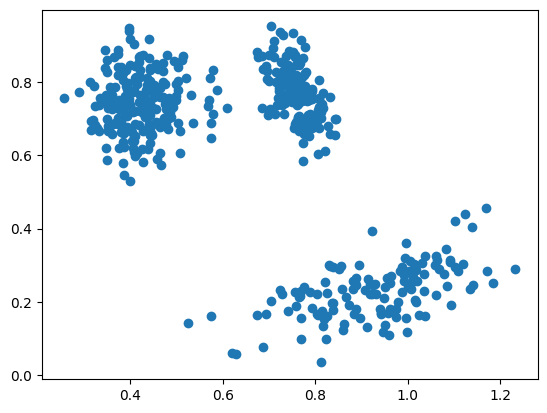

In [ ]:
X = np.genfromtxt("2DGaussianMixture.csv", delimiter=",")
X = X[1:]
X = X[:,1:]
plt.scatter(X[:,0],X[:,1])
plt.show()

In [ ]:
from scipy.stats import multivariate_normal

def euclidean_distance(x1, x2):
    return np.sqrt(sum((x1 - x2) ** 2))

def plot_clusters(X, y=None, Mu_array=0):
    fig, ax = plt.subplots(figsize=(6, 4))
    plt.scatter(X[:, 0], X[:, 1], c=y, s=1)
    if sum(Mu_array) != 0:
        plt.scatter(Mu_array[:,0],Mu_array[:,1],marker="x", color="black", linewidth=2)

    plt.xlabel("$x_1$", fontsize=14)
    plt.ylabel("$x_2$", fontsize=14, rotation=0)
    plt.grid()
    plt.tight_layout()
    plt.show()

# initialization for Kmeans++ algorithm
def initialize(X, K):

    ## Step 1: initialize the centroids list and add
    ## a randomly selected data point to the list
    n_samples, n_features = X.shape
    random_sample_idxs = random.choice(n_samples, 1, replace=False)
    centroids = X[random_sample_idxs,:]

    ## compute remaining K - 1 centroids
    for c_id in range(K - 1):
        ## Step 2: initialize a list to store distances of data
        ## points from nearest centroid
        ## compute distance of 'point' from each of the previously
        ## selected centroid and store the minimum distance
        dist = np.zeros(n_samples)
        for idx, sample in enumerate(X):
          distances     = [euclidean_distance(sample, point) for point in centroids]
          dist[idx]     = min(distances)

        ## Step 3: select data point with maximum distance as our next centroid
        next_centroid = X[np.argmax(dist), :]
        centroids=np.vstack([centroids,next_centroid])

    return centroids

def initialize_theta(X, K, centroids):
    # N has the number of rows while d has the number of columns of dataset X
    N, d = X.shape

    # initial weights given to each cluster are stored in phi or P(Zi=c)
    Pi = np.full(shape=K, fill_value=1/K)

    # initial weights given to each data point wrt to each cluster or P(Zi=c|Xi)
    weights = np.full(shape=(N,K), fill_value=1/K)


    # initial value of mean of K Gaussians
    Mu = [  centroids[i,:] for i in range(K) ]

    # initial value of covariance matrix of K Gaussians
    Sigma = [ np.cov(X.T) for _ in range(K) ]
    # theta =(Mu,Sigma,Pi)
    return Pi, Mu, Sigma, weights

# computer posterior probability of each data point wrt each cluster
# parameters are Pi, Mu, Sigma
def predict_posterior(X, K, Pi, Mu, Sigma):
    N = X.shape[0]
    # Creates a N*K matrix denoting probability of each point wrt each cluster
    likelihood = np.zeros( (N, K) )
    for i in range(K):
        distribution = multivariate_normal(mean=Mu[i],cov=Sigma[i])
            # pdf : probability denisty function
        likelihood[:,i] = distribution.pdf(X)

    numerator = likelihood * Pi
    denominator = numerator.sum(axis=1)[:, np.newaxis]
    weights = numerator / denominator
    return weights


# E-Step: update weights holding Pi Mu Sigma constant
def e_step(X, K, Pi, Mu, Sigma):
    # updated weights(i,c)=P(Zi=c|Xi)
    weights   = predict_posterior(X, K, Pi, Mu, Sigma)
    return weights


# M-Step: update Mu, Sigma, Pi, holding weights constant
def m_step(X, K, weights):
    # mean of sum of probability of all data points wrt to one cluster is new updated probability of cluster Pi_c
    Pi_update = weights.mean(axis=0)
    Mu_update = [[] for _ in range(K)]
    Sigma_update = [[] for _ in range(K)]
    for i in range(K):
        weight_i = weights[:, [i]]
        total_weight = weight_i.sum()
        Mu_update[i]    = (X * weight_i).sum(axis=0) / total_weight
        Sigma_update[i] = np.cov(X.T, aweights=(weight_i/total_weight).flatten(), bias=True)

    return Pi_update, Mu_update, Sigma_update

# predict function
def predict(X, K, Pi, Mu, Sigma):
   weights = predict_posterior(X, K, Pi, Mu, Sigma)
   # datapoint belongs to cluster with maximum probability
   # returns this value
   return np.argmax(weights, axis=1)

def GMM_fit(X, K,centroids, max_iter=200, threshold =0.0001):
  # initialise parameters like weights, Pi, Mu, Sigma of all Gaussians in dataset X
  # step 1
  Pi, Mu, Sigma, weights = initialize_theta(X,K,centroids)
  for j in range(max_iter):
    z = predict(X, K, Pi, Mu, Sigma)
    Mu_array = np.array(Mu)
    # plot_clusters(X, z, Mu_array)
    # step 2 iterate to update the value of P(Zi=c|Xi)
    weights = e_step(X, K, Pi, Mu, Sigma)
    Pi_old  = Pi;
    Mu_old  = Mu;
    # step 3 iterate to update the value of Mu, Sigma and Pi as the clusters shift
    Pi, Mu, Sigma  = m_step(X, K, weights)

    # for stopping
    distances = [ linalg.norm(Mu[i] - Mu_old[i]) for i in range(K)]
    if sum(distances) < threshold:
      print('Number of iteration is ', j+1)
      break

  z = predict(X, K, Pi, Mu, Sigma)
  Mu_array = np.array(Mu)
  plot_clusters(X, z, Mu_array)

  return z, Pi, Mu, Sigma

Number of iteration is  7


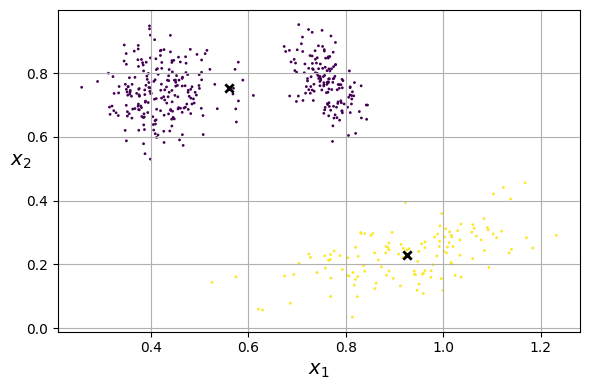

Number of iteration is  22


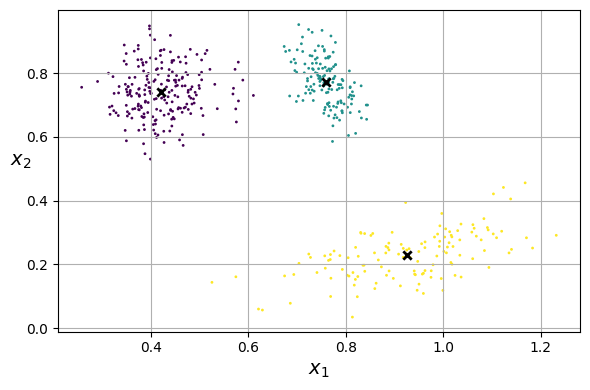

Number of iteration is  91


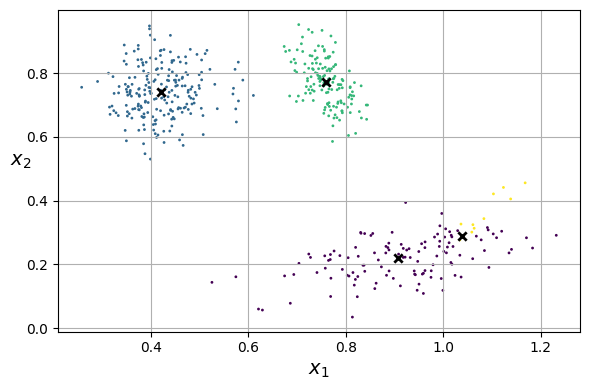

Number of iteration is  56


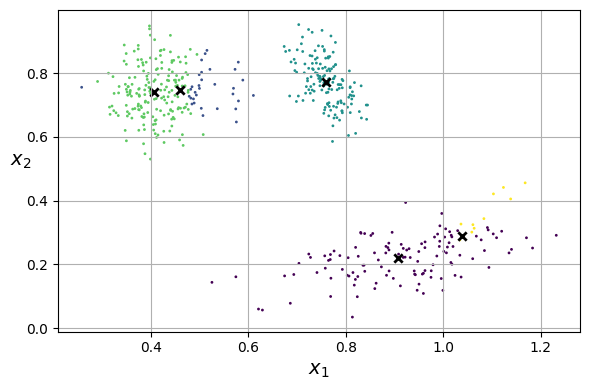

Number of iteration is  78


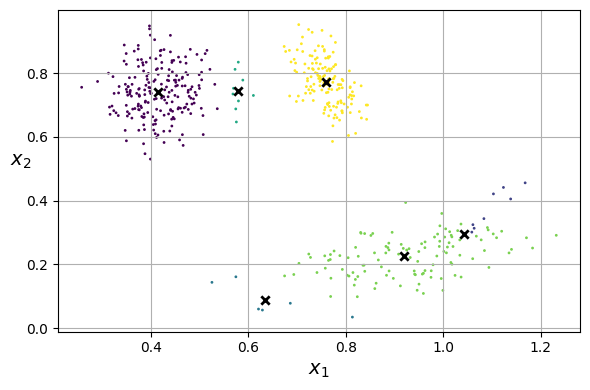

In [ ]:
min_K = 2
max_K = 6
K_list = range(min_K,max_K+1)
BIC_list = []
run_sim = True

if run_sim:
    sim_num = 10
else:
    sim_num = 1

for sim in range(sim_num):
    for K in K_list:
        centroids = initialize(X,K)
        z, Pi, Mu, Sigma=GMM_fit(X, K,centroids)
        Pi = np.array(Pi)
        Mu = np.array(Mu)
        Sigma = np.array(Sigma)
        lg = log_likelihood(X,K,Pi,Mu,Sigma)
        if sim == 0:
            BIC_list.append(BIC(X,K,lg))
        else:
            BIC_list[K-min_K] += BIC(X,K,lg)

BIC_list = np.array(BIC_list)
BIC_list = BIC_list/sim_num

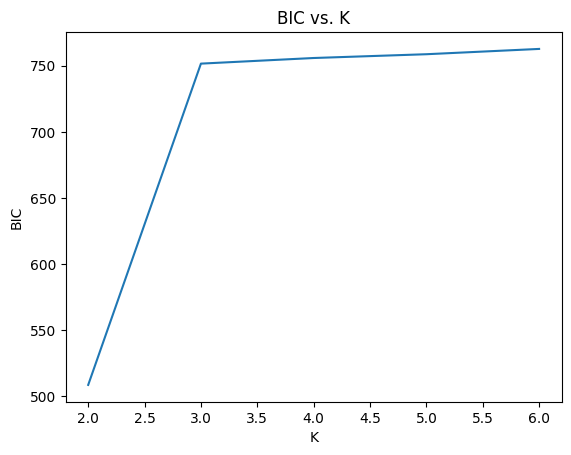

In [ ]:
plt.plot(K_list, BIC_list)
plt.xlabel("K")
plt.ylabel("BIC")
plt.title("BIC vs. K")
plt.show()

In [ ]:
print(BIC_list)

[508.61468914 751.56421253 755.81375715 758.67386677 762.6824829 ]


Since the BIC values for $K=4,5,6$ are all very similar, it depends on randomness which outputs as "the best" $K$ for this particular clustering, typically within an integer value of each other hovering around $BIC = 759$. I did a small simulation of size 10 to take the average over multiple runs and got $K=6$ with $BIC = 759.9$, so I choose $K=6$ as the best cluster number.



---

# Part V — Dimensionality Reduction and Neural Networks

Compressing and classifying face images: PCA by eigendecomposition on the Yale database, then softmax regression and feedforward networks on Labeled Faces in the Wild.


In [150]:
%pylab inline
import numpy as np
import numpy.linalg as LA
from time import time
import plotly.express as px
from scipy import sparse
import pandas as pd
from matplotlib import pyplot as plt
plt.rcParams["figure.figsize"] = (8,6)

Populating the interactive namespace from numpy and matplotlib


/usr/local/lib/python3.10/dist-packages/IPython/core/magics/pylab.py:159: UserWarning: pylab import has clobbered these variables: ['time']
`%matplotlib` prevents importing * from pylab and numpy
  warn("pylab import has clobbered these variables: %s"  % clobbered +


## Principal Component Analysis
Principal Component Analysis (PCA) is a dimensionality reduction algorithm that represents the data matrix as a set of principal components that are orthogonal to each other. Each of these principal components captures a source of variation in the original data matrix such that we can reduce the dimensions of the data while preserving as much information as possible. Principal components are defined as the eigenvectors of the covariance matrix of the data; thus, we will be implementing PCA using eigendecomposition.

This question will help you understand the basics of eigendecomposition. By examining the dimensionality reduction and reconstruction of images, you will think and learn more about informative representations of data.

Let’s do PCA and reconstruct pictures of faces in the PCA basis. As we will be making many visualizations of images, plot these images in a reasonable way (e.g. make the images smaller).

### Trace and Eigenvalue Identities
The trace of a square matrix $\textbf{M}$, denoted, by $Tr(\textbf{M})$ is defined as the sum of
the diagonal entries of $\textbf{M}$.

 Now we prove a few claims that will be
helpful in the next problem. Define $\mathbf{\Sigma} := \frac{1}{n}
\mathbf{{X}^{\mathrm{T}}X}$, where $\mathbf{X}$ is the $n \times d$ data matrix. Let $\mathbf{x}_i$ be the $i$-th row of $\mathbf{X}$ (so $\mathbf{x}_i$ is a $d$-dimensional vector). Let $\lambda_1 \ge \lambda_2 \ge \dots \ge
\lambda_d$ be the eigenvalues of $\mathbf{\Sigma}$. Show the following two
properties:
\begin{aligned}
    Tr(\boldsymbol{\Sigma}) &= \sum_{i=1}^d \lambda_i \\
    Tr(\boldsymbol{\Sigma}) &= \frac{1}{n} \sum_{i=1}^n
||{\mathbf{x}_i}||_2^2
\end{aligned}

<p><em>Hint 1:</em> Symmetric matrices are orthogonally diagonalizable.
That is, a symmetric matrix <span
class="math inline">\(\textbf{A}\)</span> can always be written as <span
class="math inline">\(\textbf{A} = \textbf{UDU}^T\)</span>, where <span
class="math inline">\(\textbf{D}\)</span> is a diagonal matrix with the
eigenvalues of <span class="math inline">\(\textbf{A}\)</span> along the
diagonal and <span class="math inline">\(\textbf{U}\)</span> is an
orthogonal matrix, whose columns are the eigenvectors of <span
class="math inline">\(\textbf{A}\)</span>.</p>
<p><em>Hint 2:</em> <span
class="math inline">\(Tr(\textbf{A}{\textbf{B}}^{\mathrm{T}}) =
Tr({\textbf{B}}^{\mathrm{T}}\textbf{A})\)</span> for two matrices <span
class="math inline">\(\textbf{A}\)</span> and <span
class="math inline">\(\textbf{B}\)</span> of size <span
class="math inline">\(n \times d\)</span>.</p></li>

#### Solution

1.

First, note $\mathbf{\Sigma}^{\mathrm{T}} = (\frac{1}{n}\mathbf{X}^{\mathrm{T}}\mathbf{X})^{\mathrm{T}} = \frac{1}{n}(\mathbf{X}^{\mathrm{T}}\mathbf{X})^{\mathrm{T}} = \frac{1}{n}(\mathbf{X})^{\mathrm{T}}(\mathbf{X}^{\mathrm{T}})^{\mathrm{T}} = \frac{1}{n}\mathbf{X}^{\mathrm{T}}\mathbf{X} = \mathbf{\Sigma}$, so $\mathbf{\Sigma}$ is symmetric.

Since $\mathbf{\Sigma} \in \mathcal{R}^{d\times d}$ is symmetric, we can decompose as $\mathbf{\Sigma} = \mathbf{UDU}^{\mathrm{T}},$ where $\mathbf{U} \in \mathcal{R}^{d\times d}$ is orthogonal and $\mathbf{D} \in \mathcal{R}^{d\times d}$ is diagonal with each value an eigenvalue of $\mathbf{\Sigma}$, i.e. $\mathbf{D}_{ii} = \lambda_i$.

Now, we wish to show the cyclic property of trace. Suppose we have matricies $G\in \mathcal{R}^{a\times b}$ and $H\in \mathcal{R}^{b\times a}$. Then, $Tr(GH) = \sum_{i=1}^a \sum_{j=1}^b G_{ij}H_{ji} = \sum_{i=1}^a \sum_{j=1}^b H_{ji}G_{ij} = Tr(HG)$.

We can use this in conjuntion with the associative rules of matrix multiplication, i.e. $Tr(A(BC)) = Tr((BC)A)$ (so long as the matrix multiplication is valid).

Then, using the cyclic property of trace and orthogonal matrix property $\mathbf{U}^{\mathrm{T}}\mathbf{U}=\mathbf{I}$, we have:
$Tr(\mathbf{\Sigma}) = Tr(\mathbf{U}(\mathbf{DU}^{\mathrm{T}})) = Tr((\mathbf{DU}^{\mathrm{T}})\mathbf{U}) = Tr(\mathbf{D}(\mathbf{U}^{\mathrm{T}}\mathbf{U})) = Tr(\mathbf{D}\mathbf{I}) = Tr(\mathbf{D}) = \sum_{i=1}^d \mathbf{D}_{ii} = \sum_{i=1}^d \lambda_i$.


2.

First, note $Tr(\frac{1}{n}M) = \sum_{i=1}^n \frac{1}{n}M_{ii} = \frac{1}{n} \sum_{i=1}^n M_{ii} = \frac{1}{n} Tr(M).$

Now, consider $A = \mathbf{X}\mathbf{X}^{\mathrm{T}} \in \mathcal{R}^{n\times n}$. The ith diagonal entry of $A$ (by matrix multiplication) is $A_{ii} = \mathbf{x}_i\mathbf{x}_i^{\mathrm{T}} = ||{\mathbf{x}_i}||_2^2$.

Then, $Tr(\mathbf{\Sigma}) = Tr(\frac{1}{n}\mathbf{X}^{\mathrm{T}}\mathbf{X}) = \frac{1}{n}Tr(\mathbf{X}^{\mathrm{T}}\mathbf{X}) = \frac{1}{n}Tr(\mathbf{X}\mathbf{X}^{\mathrm{T}}) = \frac{1}{n}Tr(A) = \frac{1}{n}\sum_{i=1}^n ||{\mathbf{x}_i}||_2^2$.



---

### The Optimal Projection Matrix
Now we have a $d \times k$ projection matrix $\mathbf{P}$ with $\mathbf{P}^{T}\mathbf{P}=\mathbf{I}_{k}$.
We have the linear projection from $\mathbb{R}^{n \times d}$ to $\mathbb{R}^{n \times k}$: $\mathbf{X} \mapsto \mathbf{X}\mathbf{P}$.
We have the following result:</p>
<p><span class="math display">\[\mathop{\arg\max}_{\mathbf{P} \in
\mathbb{R}^{d \times k}, \mathbf{P}^{T} \mathbf{P}=\mathbf{I}}
\operatorname{Tr}\left(\frac{1}{n}\mathbf{P}^{T}\mathbf{X}^{T} \mathbf{
X P}\right) =  \mathbf{P}^{*}\]</span></p>
<p>where each column of <span
class="math inline">\(\mathbf{P}^{*}\)</span> is the corresponding
eigenvector <span class="math inline">\(u_{i}\)</span> for <span
class="math inline">\(\lambda_{i}\)</span> with <span
class="math inline">\(i = 1, ..., k\)</span>. Note that <span
class="math inline">\(u_{i}\)</span> and <span
class="math inline">\(\lambda_{i}\)</span> are the eigenvectors and
eigenvalues of <span class="math inline">\(\mathbf{\Sigma}\)</span> as
defined in 1.a.1. Please prove: <span
class="math display">\[Tr(\frac{1}{n}\mathbf{P}^{*T}\mathbf{X}^{T}\mathbf{X}\mathbf{P}^{*})
= \sum_{i = 1}^{k}\lambda_{i}\]</span>.</p>
<p>With the result obtained in part 1, we have <span
class="math inline">\(1 -
\frac{\lambda_{1}+\cdots+\lambda_{k}}{\lambda_{1}+\cdots+\lambda_{d}} =
1 -
\frac{\sum_{i=1}^n||{\mathbf{P}^{*T}\mathbf{x}_i}^2||}{\sum_{i=1}^n||{\mathbf{x}_i}^2||}\)</span>.
This metric is called the PCA fractional reconstruction error of using
the top <span class="math inline">\(k\)</span> out of $d$ directions.

#### Solution

Define $\mathbf{\Sigma} = \frac{1}{n}\mathbf{X}^{\mathrm{T}}\mathbf{X}$ and note $\frac{1}{n}\mathbf{P}^{*T}\mathbf{X}^{T}\mathbf{X}\mathbf{P}^{*} = \mathbf{P}^{*T}(\frac{1}{n}\mathbf{X}^{T}\mathbf{X})\mathbf{P}^{*} = \mathbf{P}^{*T}\mathbf{\Sigma}\mathbf{P}^{*}$.

Since $\mathbf{\Sigma}$ is symmetric, we have $\mathbf{P}^{*T}\mathbf{\Sigma}\mathbf{P}^{*} = \mathbf{P}^{*T}\mathbf{UDU}^{\mathrm{T}}\mathbf{P} := \mathbf{Y}^{\mathrm{T}}\mathbf{DY}, \mathbf{Y}\in \mathcal{R}^{d\times k}$

Consider the matrix multiplication of $A = \mathbf{Y}^{\mathrm{T}}\mathbf{D} \in \mathcal{R}^{k\times d}.$ Each row of $A$ is $\mathbf{y}_i\vec{\lambda}$, where $\mathbf{y}_i$ is the $ith$ column of $\mathbf{Y}.$

Then, the $i$th diagonal of $\mathbf{Y}^{\mathrm{T}}\mathbf{DY}$ is simply $\lambda_i (\mathbf{y}_i \cdot \mathbf{y}_i),$ but under our initial conditions, $\mathbf{y}_i \cdot \mathbf{y}_i = 1,$ so each diagonal entry is just $\lambda_i$.

Thus,

$$
\begin{align*}
Tr(\frac{1}{n}\mathbf{P}^{*T}\mathbf{X}^{T}\mathbf{X}\mathbf{P}^{*}) &= Tr(\mathbf{P}^{*T}\mathbf{\Sigma}\mathbf{P}^{*})\\
&= Tr(\mathbf{P}^{*T}\mathbf{UDU}^{\mathrm{T}}\mathbf{P}^{*})\\
&= Tr(\mathbf{Y}^{\mathrm{T}}\mathbf{D}\mathbf{Y})\\
&= \sum_{i = 1}^{k}\lambda_{i} (\mathbf{y}_i \cdot \mathbf{y}_i)\\
&= \sum_{i = 1}^{k}\lambda_{i} .
\end{align*}
$$



---



### Eigendecomposition of the Yale Face Database
For this question we will use the dataset
<span><code>faces.csv</code></span> from <code>pca/data</code> (adapted
from <a
href="http://vision.ucsd.edu/~leekc/ExtYaleDatabase/ExtYaleB.html">the
Extended Yale Face Database B</a>), which is composed of facial pictures
of 38 individuals under 64 different lighting conditions such as lit
from the top, front, and side (some lighting conditions are missing for
some people). In total, there are 2414 images, where each image is 96
pixels high and 84 pixels wide (for a total of 8064 pixels per image).
Each row in the dataset is a single image flattened into a vector in a
column-major order. The images are in grayscale, so each pixel is
represented by a single real number between <span
class="math inline">\(0\)</span> (black) and <span
class="math inline">\(1\)</span> (white).

Define $\boldsymbol{\Sigma}$, a
$8064 \times 8064$ matrix, as
follows: $$\boldsymbol{\Sigma} = \frac{1}{n}
\sum_{i=1}^n \textbf{x}_i {\textbf{x}}^{\mathrm{T}}_i$$ where the
$\textbf{x}_i$’s are points in our
dataset as <strong>column</strong> vectors and $n = 2414$ is the number of points in the
dataset. Now compute the top 50 PCA dimensions; these are the 50
dimensions which best reconstruct the data.</p>
<p>We will be implementing PCA using eigendecomposition. Thus, you may
use library functions for obtaining the eigenvalues and eigenvectors of
a matrix (e.g. <code>numpy.linalg.eigh</code> in Python). You should
<strong>not</strong> use functions which directly compute the principal
components of a matrix.

**Data access:** the data is stored in https://drive.google.com/file/d/1h0-DSjz59VOQJMbghIh1pKReTtU7_owV/view?usp=sharing.

**Load Data:** Once you open the link in the brower, make sure you click the "Add shortcut to Drive" and now your google drive should show up the zip file.  Then you run the following code to link colab to your google drive.

Please answer the following questions.
1. What are the eigenvalues $\lambda_1, \lambda_2, \lambda_{10}, \lambda_{30}$ and $\lambda_{50}$? Also, what is the sum of eigenvalues $\sum_{i=1}^d\lambda_i$?

2. We know fractional reconstruction error of using the top $k$ out of $d$ directions is $1 -
\frac{\lambda_{1}+\cdots+\lambda_{k}}{\lambda_{1}+\cdots+\lambda_{d}}$. This means that when $k = d$, our reconstruction error is 0, which basically means that we use all the principal components and simply reconstruct the original matrix. Plot this fractional reconstruction error for each of the first 50 values of $k$ (i.e. $k$ from 1 to 50). So the X-axis is $k$ and the Y-axis is the fractional reconstruction error. Make sure your plots are legible at reasonable zoom and the axes are labeled in your write-up.

3. Using 1-3 sentences, explain what the first eigenvalue captures, and why you think $\lambda_1$ is much larger than the other eigenvalues.

In [151]:
from google.colab import drive
drive.mount('/content/drive')
import os
os.chdir("/content/drive/My Drive/ualbany courses/Machine Learning/hw5")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [152]:
faces = np.genfromtxt('faces.csv', delimiter=',')
faces_mean = np.mean(faces, axis=0)
faces = faces - faces_mean

In [153]:
n,d = faces.shape
print(n,d)

# get eigen information
sigma = faces.T @ faces / n
eig_val , eig_vec = LA.eigh(sigma)

2414 8064


Eigenvalue 1: 167.46953849118606 ; Sum of Eigenvalues up to Eigenvalue 1: 167.46953849118606
Eigenvalue 2: 160.94165806576297 ; Sum of Eigenvalues up to Eigenvalue 2: 328.411196556949
Eigenvalue 10: 3.0804228105122173 ; Sum of Eigenvalues up to Eigenvalue 10: 393.21708078405436
Eigenvalue 30: 0.7831902761674437 ; Sum of Eigenvalues up to Eigenvalue 30: 422.23653217239996
Eigenvalue 50: 0.3895740862028482 ; Sum of Eigenvalues up to Eigenvalue 50: 433.3018731283802


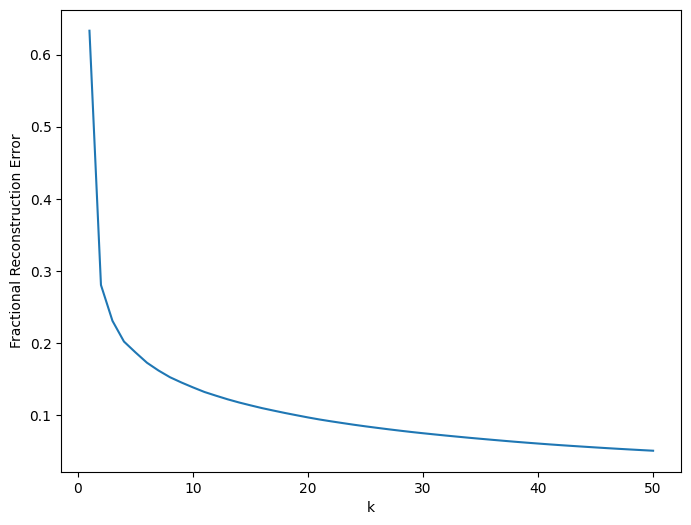

In [154]:
eig_vec = np.real(eig_vec).T
idx = np.argsort(eig_val)[::-1]
eig_val = eig_val[idx]
eig_vec = eig_vec[idx]

index_list = [1,2,10,30,50]

# 1.
for i in index_list:
    print('Eigenvalue '+str(i)+': '+str(eig_val[i-1])+
          ' ; Sum of Eigenvalues up to Eigenvalue '+str(i)+': '+str(np.sum(eig_val[:i])))

# 2.
frac_recon = []
for k in range(50):
    frac_recon.append([k+1, 1 - (np.sum(eig_val[:k+1]) / np.sum(eig_val))])
frac_recon = np.asarray(frac_recon).T
plt.plot(frac_recon[0],frac_recon[1])
plt.xlabel('k')
plt.ylabel('Fractional Reconstruction Error')
plt.show()

#### Solution

The eigenvalues capture the amount of vairance associated with each feature, thus higher valued eigenvalues correlate to higher variance features, and lower valued eigenvalues correlate to lower variance features. In essence, this means the highest valued eigenvalue (which in our sorted form is $\lambda_1$) holds the most information, because it represents the highest variance in our model.

$\lambda_1$ represents facial structure, i.e a gray scale that generates a generic face. The more "information" we get about the face (i.e. more eigen values we add), the more details the face recovers.



---

### Visualizing the Eigen-Directions
Now let us get a sense of the what the top PCA directions are capturing (recall these are the directions which capture the most variance).

Display the first 10 eigenvectors as images. Label the images to denote which eigenvector each image denotes. Provide a brief interpretation (4-6 sentences) of what you think each eigenvector captures (Hint: Look at each image and think about what features of the image the eigenvector is capturing).

  - **Hint 1**: If the images appear like random lines, try reshaping differently and then transposing.
  - **Hint 2**: The eigenvectors you obtain are normalized to have length 1 in the L2 norm, thus their entries are extremely small. To avoid getting all-black images, make sure to re-normalize the image. in Python, `matplotlib.pyplot.imshow` does this by default.

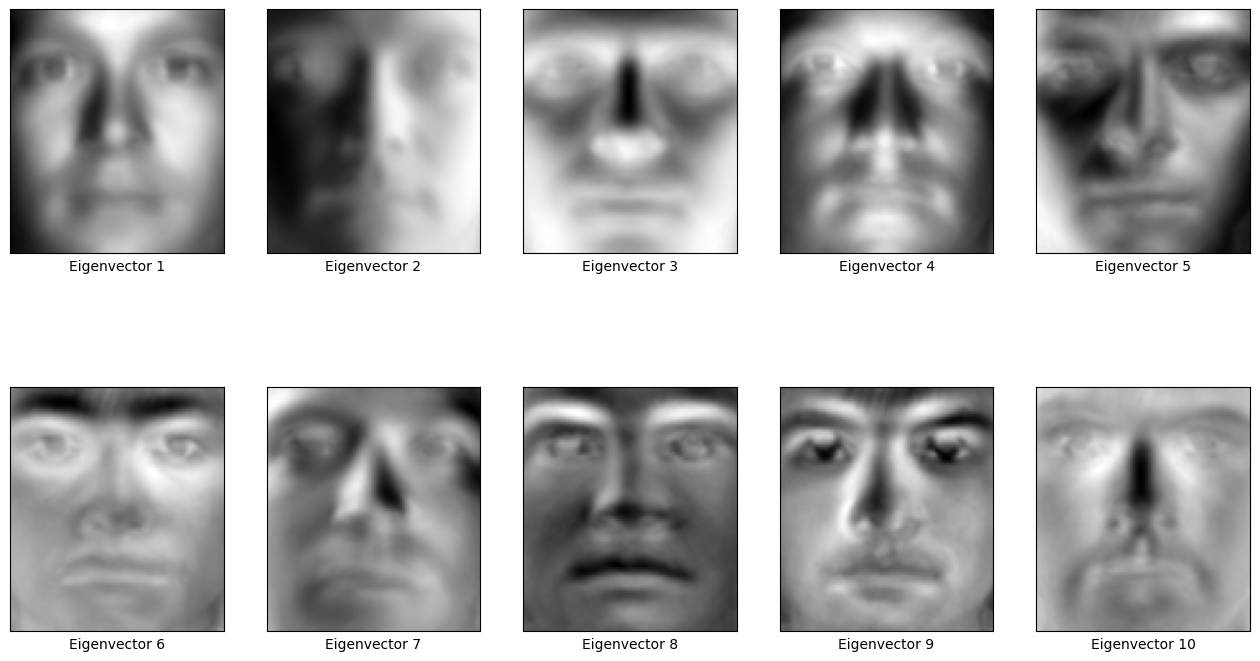

In [155]:
# Plot eigenvectors
fig, axs = plt.subplots(2,5, figsize=(16,9))

for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.xlabel('Eigenvector '+str(i+1))
    plt.imshow(eig_vec[i].reshape((84,96)).T, cmap='gray')

plt.setp(plt.gcf().get_axes(), xticks=[], yticks=[])
plt.show()


#### Solution

It looks as if each eigenvector has some attribute to the greyscale of the overall set of images. The greyscale of the eigenvectors corresponds to defining features of a human face, seeming to range in importance to what that feature gives a face in terms of uniqueness.

For example, the first eigen vector seems to outline the general structure of a face with where the darker spots lie, the second looks like lighting, the third and tenth seem to be nose structure, the sixth looks like eyebrows and so on.

Eigenvalues determine the importance of each of these eigenvectors (at least in terms of "facial structure" information).



---
### Reconstruction from the Top Components
We will now observe the reconstruction using PCA on a sample of images composed of the following images:
- image 1 (row 0).

- image 24 (row 23).

- image 65 (row 64).

- image 68 (row 67).

- image 257 (row 256).

In the previous parts, we used eigendecomposition to extract the top $k$ eigenvectors of $\Sigma$. Now, we will examine reconstruction using PCA.

For each of these images, plot the original image and plot the projection of the image onto the top $k$ eigenvectors of $\Sigma$ for $k = 1,2,5,10,50$. In particular, if $U$ is the $d × k$matrix of the top $k$ eigenvectors, the reconstruction matrix will be $UU^\top$.

Specifically, you should obtain a $5 × 6$ table where in each row corresponds to a single image, the first cell in every row is the original image and the following cells are the reconstructions of the image with the 5 different values of $k$.

**Hint:** In this problem, we are observing (partial) combinations of images that already have a meaningful scale. Therefore, we want to keep the scale of the results and not re-normalize the images (in contrast to part (c)). If you are using matplotlib.pyplot.imshow in Python, you should pass the additional arguments vmin=0, vmax=1, e.g. `imshow(im, vmin=0, vmax=1)`.

In [156]:
# running this if needing a transpose
eig_vec = eig_vec.T

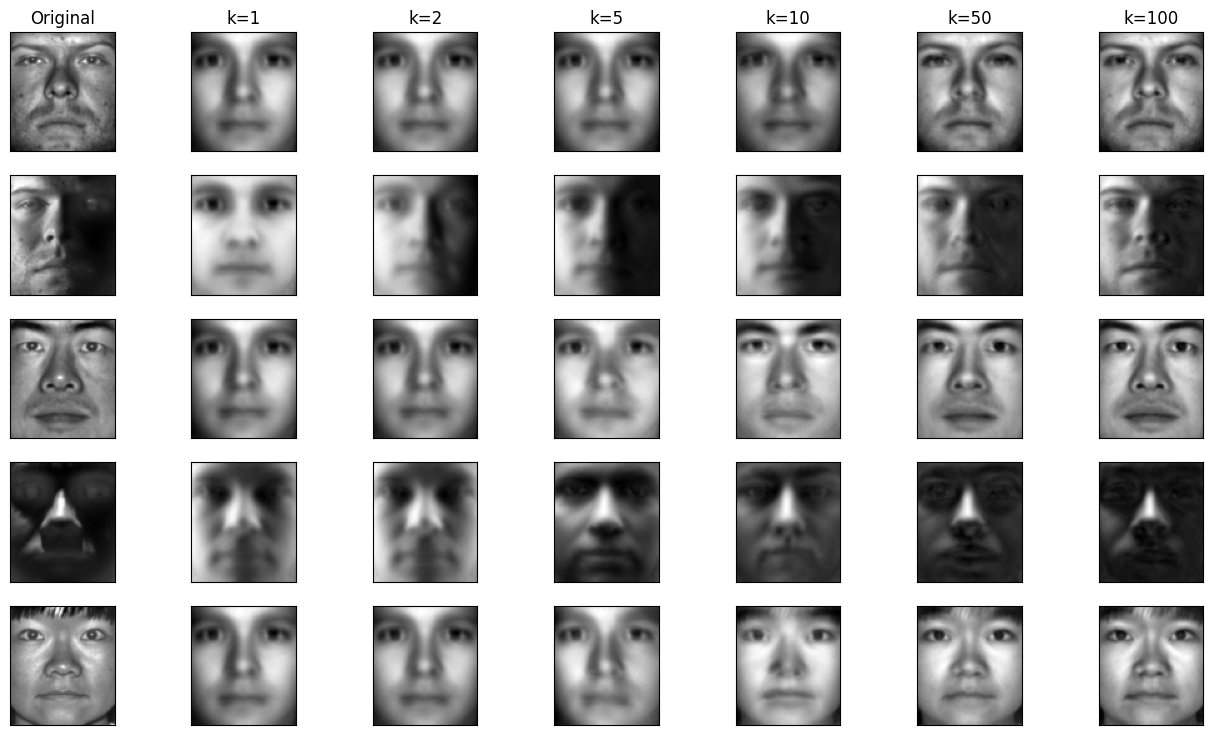

In [157]:
# adding one more plot for lambda_100 for interest
fig, axs = plt.subplots(5,7, figsize=(16,9))
axs[0, 0].set_title('Original')
axs[0, 1].set_title('k=1')
axs[0, 2].set_title('k=2')
axs[0, 3].set_title('k=5')
axs[0, 4].set_title('k=10')
axs[0, 5].set_title('k=50')
axs[0, 6].set_title('k=100')

num_plots_made = 1
for image in [0,23,64,67,256]:
    plt.subplot(5,7,num_plots_made)
    plt.imshow(faces[image].reshape((84, 96)).T, cmap='gray')
    num_plots_made+=1
    for k in [1,2,5,10,50,100]:
        comp = eig_vec[:,:k]
        proj_face = faces.dot(comp).dot(comp.T) + faces_mean
        x = np.reshape(proj_face, [n,84,96])
        plt.subplot(5,7,num_plots_made)
        plt.imshow(x[image].T, cmap='gray')

        num_plots_made+=1

plt.setp(plt.gcf().get_axes(), xticks=[], yticks=[])
plt.show()



---



---

## Softmax Regression on Labeled Faces in the Wild
In this assignment, we will use the logistic regression with Softmax for face recognition. Our task here is to be able to predict the correct label (name of the person) given an image of his face.

For this task, we will use a dataset called [Labeled Faces in the Wild](http://vis-www.cs.umass.edu/lfw/), which contains 13233 images of faces which belong to  5749 people. Each image in the dataset is labeled with a number corresponding to a person's name. All the images in the dataset are cropped and resized to the same image size.

To load the data, we will use the scikit-learn's function [sklearn.datasets.fetch_lfw_people](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_lfw_people.html). To make our life a bit easier we will only use faces of people which appear in the dataset more than 100 times.

Let's do multi-class classification with the softmax function.
Remember the model is as follows:

1. the probability for $K$ classes are  
\begin{align}
\text{Pr}(y=\ell |\mathbf{x}, \mathbf{W}) = \frac{\exp(\mathbf{w}_\ell \cdot \mathbf{x})}{\sum_{j=0}^{K-1} \exp(\mathbf{w}_j \cdot \mathbf{x}) }
\end{align}
where $\mathbf{w}_\ell $ is $\ell$-th row of $\mathbf{W}$. Here we ignore the bias vector.

2. In prediction, you will take the largest predicted probability among your $K$ predicted probability.

3. The negative log-likelihood function on the $N$ training dataset is
\begin{align}
L(\mathbf{W}) = -\frac{1}{N}\sum_{i=1}^N \log \text{Pr}(y=y^{(i)} | \mathbf{x}^{(i)}, \mathbf{W})
\end{align}
The following figure illustrates the logistic regression with softmax on the MNIST dataset (of course with the bias vector).
<img src="https://github.com/yexf308/MAT592/blob/main/image/MNIST_LR.png?raw=true" width="800" />



Number of images in the dataset: 1140
Number of different persons in the dataset: 5
Each images size is: (62, 47)


<ipython-input-158-e95afd42cc8c>:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(label_to_name_mapping, rotation=-90);


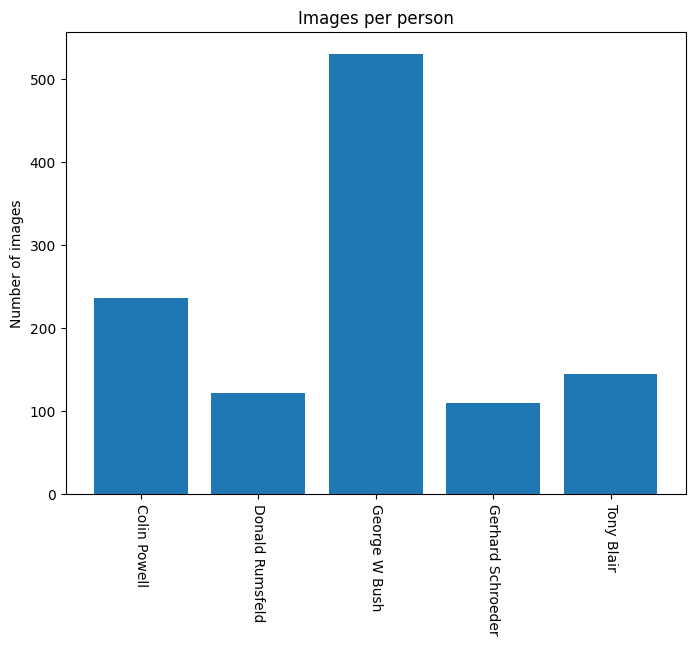

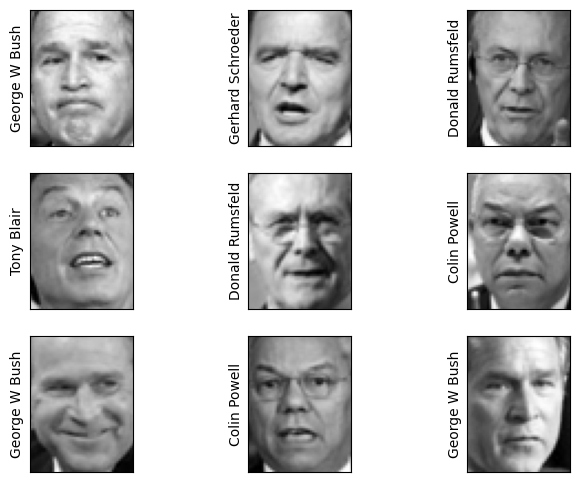

In [158]:
from sklearn.datasets import fetch_lfw_people
dataset = fetch_lfw_people(min_faces_per_person=100)

X = dataset.images
y = dataset.target
label_to_name_mapping = dataset.target_names
image_shape = X[0].shape

print('Number of images in the dataset: {}'.format(len(X)))
print('Number of different persons in the dataset: {}'.format(len(np.unique(y))))
print('Each images size is: {}'.format(image_shape))

_, images_per_class = np.unique(y, return_counts=True)
fig, ax = plt.subplots()
ax.bar(label_to_name_mapping, images_per_class)
ax.set_xticklabels(label_to_name_mapping, rotation=-90);
ax.set_title('Images per person')
ax.set_ylabel('Number of images')


# plots the first 20 images in the dataset.
fig, ax_array = plt.subplots(3, 3)
for i, ax in enumerate(ax_array.flat):
    ax.imshow(X[i], cmap='gray')
    ax.set_ylabel(label_to_name_mapping[y[i]])
    ax.set_yticks([])
    ax.set_xticks([])

In [159]:
from sklearn.model_selection import train_test_split
# split the data into 80% training set and 20% testing set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train = X_train.reshape(X_train.shape[0], -1)
X_test = X_test.reshape(X_test.shape[0], -1)

print(X_train.shape)
print(X_test.shape)

(912, 2914)
(228, 2914)


In [160]:
print(y_train[:20])

[2 2 2 0 2 2 4 4 2 0 2 3 1 2 2 2 2 0 0 2]




---




### Gradient of the Softmax Loss
Express the label $y$ into one hot vector, i.e., $y=\ell$ is represented by $\vec{y}$ with $\vec{y}_\ell =1$ and other indices are zero.

Calculate the derivative of the negative log-likelihood with respect to the variable $\mathbf{W}$. Write this in a natural manner in terms of conditional probability, the data matrix $\mathbf{X}$. Don't write this expression in terms of exponentials directly.
You may refer to results in previous lectures.

#### Solution

Note that the derivative of $L(\mathbf{W})$ is the gradient
$\nabla L(\mathbf{W}) = -\frac{1}{N}\begin{bmatrix}\frac{\delta}{\delta\vec{\mathbf{w}}_1} L(\mathbf{W})\\ \dots \\ \frac{\delta}{\delta\vec{\mathbf{w}}_K} L(\mathbf{W}) \end{bmatrix}.$

We consider the $k$th entry of $-N * \nabla L(\mathbf{W})$, denoted $L_k(\mathbf{W}):$

$$
\begin{align*}
L_k(\mathbf{W}) &= \frac{\delta}{\delta\vec{\mathbf{w}}_k} L(\mathbf{W})\\
&= \frac{\delta}{\delta\vec{\mathbf{w}}_k} \sum_{i=1}^N \log \text{Pr}(y=c | \mathbf{x}^{(i)}, \mathbf{W})\\
&= \frac{\delta}{\delta\vec{\mathbf{w}}_k} \sum_{i=1}^N \log \frac{\exp(\mathbf{w}_c \cdot \mathbf{x}^{(i)})}{\sum_{j=0}^{K-1} \exp(\mathbf{w}_j \cdot \mathbf{x}^{(i)}) }\\
:&= \frac{\delta}{\delta\vec{\mathbf{w}}_k} \sum_{i=1}^N \log \frac{\gamma^{(i)}_c}{\mathbf{\sigma}^{(i)}}\\
&= \sum_{i=1}^N \frac{\left(\frac{(\frac{\delta}{\delta\vec{\mathbf{w}}_k}\gamma^{(i)}_c)\sigma^{(i)} - (\frac{\delta}{\delta\vec{\mathbf{w}}_k}\sigma^{(i)})\gamma^{(i)}_c}{(\sigma^{(i)})^2} \right)}{\left(\frac{\gamma^{(i)}_c}{\mathbf{\sigma}^{(i)}}\right)},\\
\\
\text{where... } \frac{\delta}{\delta\vec{\mathbf{w}}_k}\gamma^{(i)}_c &= \frac{\delta}{\delta\vec{\mathbf{w}}_k} \exp(\mathbf{w}_c \cdot \mathbf{x}^{(i)}) = \begin{cases} \mathbf{x}^{(i)}\gamma^{(i)}_c, & \text{if } k = c\\
0, & \text{if } k \neq c \end{cases} \\
\text{and... } \frac{\delta}{\delta\vec{\mathbf{w}}_k}\sigma^{(i)}_c &= \frac{\delta}{\delta\vec{\mathbf{w}}_k} \sum_{j=0}^{K-1} \exp(\mathbf{w}_j \cdot \mathbf{x}^{(i)}) =  \mathbf{x}^{(i)}\gamma^{(i)}_k,\\
\\
\text{so...} L_k(\mathbf{W}) &= \sum_{i=1}^N \frac{\left(\frac{(\frac{\delta}{\delta\vec{\mathbf{w}}_k}\gamma^{(i)}_c)\sigma^{(i)} - (\mathbf{x}^{(i)}\gamma^{(i)}_k)\gamma^{(i)}_c}{(\sigma^{(i)})^2} \right)}{\left(\frac{\gamma^{(i)}_c}{\mathbf{\sigma}^{(i)}}\right)}\\
\\
&= \sum_{i=1}^N \left(\frac{(\frac{\delta}{\delta\vec{\mathbf{w}}_k}\gamma^{(i)}_c)\sigma^{(i)} - (\mathbf{x}^{(i)}\gamma^{(i)}_k)\gamma^{(i)}_c}{\gamma^{(i)}_c\sigma^{(i)}} \right)\\
\\
&= \sum_{i=1}^N \left(\frac{(\frac{\delta}{\delta\vec{\mathbf{w}}_k}\gamma^{(i)}_c)}{\gamma_c^{(i)}} - \frac{(\mathbf{x}^{(i)}\gamma^{(i)}_k)}{\sigma^{(i)}} \right)\\
\\
&= \sum_{i=1}^N \left(\frac{(\frac{\delta}{\delta\vec{\mathbf{w}}_k}\gamma^{(i)}_c)}{\gamma_c^{(i)}} - \mathbf{x}^{(i)}\text{Pr}(y=k | \mathbf{x}^{(i)}, \mathbf{W}) \right)\\
\\
&= \begin{cases} \sum_{i=1}^N \mathbf{x}^{(i)}\left( 1 - \text{Pr}(y=c | \mathbf{x}^{(i)}, \mathbf{W}) \right), & \text{if } k=c\\
\sum_{i=1}^N (-\mathbf{x}^{(i)}\text{Pr}(y=k | \mathbf{x}^{(i)}), \mathbf{W}), & \text{if } k \neq c
\end{cases} .
\end{align*}
$$

Thus, $L_k(\mathbf{W})$ is a vector and $L_k(\mathbf{W})[i] = \begin{cases} \sum_{i=1}^N \mathbf{x}^{(i)}\left( 1 - \text{Pr}(y=c | \mathbf{x}^{(i)}, \mathbf{W}) \right), & \text{if } k=i\\
\sum_{i=1}^N (-\mathbf{x}^{(i)}\text{Pr}(y=k | \mathbf{x}^{(i)}), \mathbf{W}), & \text{if } k \neq i \end{cases}$.


We have then that $\nabla L(\mathbf{W}) = \frac{1}{N}\sum_{i=1}^N \mathbf{x}^{(i)} * \begin{bmatrix} \text{Pr}(y=1 | \mathbf{x}^{(i)}, \mathbf{W}) - 1 & \text{Pr}(y=2 | \mathbf{x}^{(i)}, \mathbf{W}) & ... & \text{Pr}(y=K | \mathbf{x}^{(i)}, \mathbf{W})\\
\text{Pr}(y=1 | \mathbf{x}^{(i)}, \mathbf{W}) & \text{Pr}(y=2 | \mathbf{x}^{(i)}, \mathbf{W}) - 1 & ... & \text{Pr}(y=K | \mathbf{x}^{(i)}, \mathbf{W})\\
... & ... & ... & ...\\
\text{Pr}(y=1 | \mathbf{x}^{(i)}, \mathbf{W}) & \text{Pr}(y=2 | \mathbf{x}^{(i)}, \mathbf{W}) & ... & \text{Pr}(y=K | \mathbf{x}^{(i)}, \mathbf{W}) - 1   \end{bmatrix} \in \mathcal{R}^{KxK}.$








---
### Implementation with SGD
(a) Implement softmax classification with SGD. Specify your learning rate (or your learning rate decay scheme if you alter learning rate).

(b) For both training dataset and testing dataset, plot the negative log-likelihood as function of the epoch number.

(c) For both training dataset and testing dataset, plot the misclassification rate as function of the epoch number.

(d) How many iterations did this take you?


In [161]:
def get_probs(x_i, y_vals, W):
    prob_vec = np.zeros(len(y_vals))
    for y in y_vals:
        num = np.exp(W[y].dot(x_i))
        den = 0
        for w in W:
            den += np.exp(w.dot(x_i))
        prob_vec[y] = num/den
    return np.asarray(prob_vec)

def unison_shuffled_copies(a, b):
    # returns a shuffled list of both x and y with respect to their indicies
    assert len(a) == len(b)
    p = np.random.permutation(len(a))
    return a[p], b[p]

def sgd(X, Y, X_test, Y_test, max_epoch, batch_size, learn_rate, conv_cal):

    n,d = X.shape
    assert batch_size <= n
    y_uniques = np.unique(Y)
    K = len(y_uniques)
    W = np.zeros((K,d))
    prev_sum_error = 0
    epoch = 0
    train_data = []
    test_data = []

    while epoch < max_epoch:
        epoch+=1
        sum_error = 0
        log_like = 0
        class_error = 0

        # shuffle x, y
        X,Y = unison_shuffled_copies(X, Y)

        # getting batch
        if batch_size == 0:
            batch_size = n
            batch_x, batch_y = X, Y
        else:
            batch_x, batch_y = X[:batch_size], Y[:batch_size]

        for idx in range(batch_size):
            # onehot of y_i
            onehot_y = np.zeros(K)
            onehot_y[batch_y[idx]] = 1

            # probability and error for current epoch
            probs = get_probs(batch_x[idx], y_uniques, W)
            max_prob_idx = np.argmax(probs)
            error = probs-onehot_y
            sum_error += -np.dot(onehot_y, np.log(probs)) # cross entropy

            # learning W
            for j in range(K):
                W[j] = W[j] - learn_rate * error[j] * batch_x[idx]

            # log likelyhood calculation
            for p in probs:
                log_like -= np.log(p)

            # classification error
            if max_prob_idx != batch_y[idx]:
                class_error += 1

        # train data appending
        train_data.append([epoch, log_like/batch_size, class_error/batch_size, sum_error])

        # getting testing data
        n_test = X_test.shape[0]
        sum_error = 0
        log_like = 0
        class_error = 0

        # shuffle x, y
        X_test,Y_test = unison_shuffled_copies(X_test, Y_test)

        for idx in range(n_test):
            probs = get_probs(X_test[idx], y_uniques, W)
            max_prob_idx = np.argmax(probs)
            onehot_y = np.zeros(K)
            onehot_y[Y_test[idx]] = 1
            sum_error += -np.dot(onehot_y, np.log(probs)) # cross entropy

            # log likelyhood calculation
            for p in probs:
                log_like -= np.log(p)

            # classification error
            if max_prob_idx != Y_test[idx]:
                class_error += 1

        # test data appending
        test_data.append([epoch, log_like/n_test, class_error/n_test, sum_error])

        # convergence check
        if abs(sum_error-prev_sum_error) < conv_cal:
            print("Convergence met. Ending epoch = ", epoch)
            break
        else:
            prev_sum_error = sum_error

        if epoch%10==0:
            print("sum error at epoch", epoch,": ", sum_error)

    return train_data, test_data



In [162]:
max_epoch = 200
batch_size = 0
learn_rate = .01
conv_cal = .1

data_train, data_test = sgd(X_train, y_train, X_test, y_test, max_epoch, batch_size, learn_rate, conv_cal)
# data_test = sgd(X_test, y_test, max_epoch, batch_size, learn_rate, conv_cal)
# data comes as epoch, NLL, classification_error, sum_error

data_train = np.asarray(data_train).T
data_test = np.asarray(data_test).T

sum error at epoch 10 :  283.4687663604461
sum error at epoch 20 :  137.19137594604263
sum error at epoch 30 :  122.07407098055138
sum error at epoch 40 :  150.96648778409835
sum error at epoch 50 :  169.42712296408803
sum error at epoch 60 :  120.16458567090297
sum error at epoch 70 :  111.36614498324438
sum error at epoch 80 :  136.59016443542313
sum error at epoch 90 :  124.45532964337477
sum error at epoch 100 :  119.37282487658632
Convergence met. Ending epoch =  104


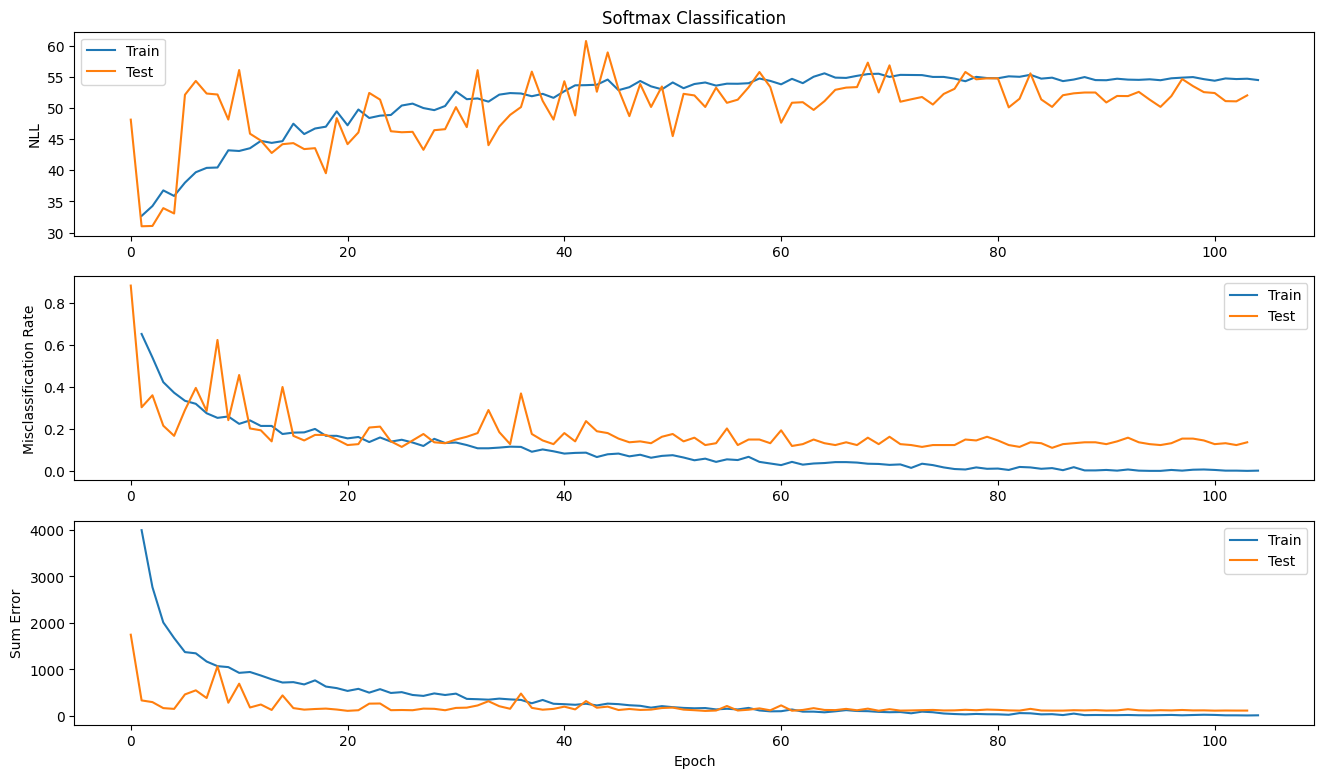

In [163]:
fig, axs = plt.subplots(3,1, figsize=(16,9))

plt.subplot(3,1,1)
plt.title("Softmax Classification")
plt.ylabel('NLL')
plt.plot(data_train[0],data_train[1],data_test[1])
plt.legend(['Train', 'Test'])
plt.subplot(3,1,2)
plt.ylabel('Misclassification Rate')
plt.plot(data_train[0],data_train[2],data_test[2])
plt.legend(['Train', 'Test'])
plt.subplot(3,1,3)
plt.xlabel('Epoch')
plt.ylabel('Sum Error')
plt.plot(data_train[0],data_train[3],data_test[3])
plt.legend(['Train', 'Test'])
plt.show()

In [164]:
max_epoch = len(data_test[0])
conv_misclass_rate = data_test[2][max_epoch-1]
print("Misclassification Rate of Testing Data at Convergence Epoch ("+str(max_epoch)+"): "+str(conv_misclass_rate))

Misclassification Rate of Testing Data at Convergence Epoch (104): 0.13596491228070176


#### Solution

Using a constant learn rate of .01 and a convergence value of .1 where convergence is tested by taking the current and previous epoch's total cross validation error, we reached convergence at epoch 125. There is a lot variance to these results due to randomness, but typically we reach convergence between 100 and 180 but I've gotten it to stop at 54 once, so it's really a grab bag.



---



---

## Deep Neural Networks

We will use the same dataset [Labeled Faces in the Wild](http://vis-www.cs.umass.edu/lfw/) in the last question. We will use the exact same training and testing dataset as before.
In these problem, we are not allowed to use pyTorch yet!

### Sigmoid Activation with Squared Loss
In class, we showed how to implement DNN with the sigmoid function as the activation function. In particular, the output layer also uses the sigmoid function. Here you may try constant learning rate.

(a) Please setup your own deep neural network to classify these faces. Here you can use sigmoid function as activation function and output function, and you can use the square loss function as well. But you have to choose the number of the layer and hidden neurons by yourself. **Happy tuning!**

(b) For both training dataset and testing dataset, plot the cost as function of the epoch number.

(c) For both training dataset and testing dataset, plot the misclassification rate as function of the epoch number.

(d) Did DNN performs better than logistic regression or not?


In [165]:
# various methods for DNN

def Sigmoid(z,derivative=False):
    """Compute Sigmoid or its derivative"""
    sigma = 1. / (1. + np.exp(-np.clip(z, -250, 250)))
    if derivative:
        return sigma * (1-sigma)
    return sigma

def Square_loss(A,Y,derivative=False):
    """Compute square loss or its derivative"""
    error = A-Y
    if derivative:
        return error

    cost = 1/2*np.dot(error, error)
    return cost

def Logistic_loss(A,Y, derivative=False):
    """Compute logistic loss or its derivative"""
    if derivative:
        num = A - Y
        dem = A * (1-A) # this is equal to g'(Z)
        return num/dem

    cost = -np.dot(np.log(A), Y) - np.dot(np.log(1-A), 1-Y)
    return cost

def Relu(z, derivative=False):
    """Compute Relu or its derivative"""
    if derivative:
        return (z > 0).astype(int)
    return np.maximum(0, z)

def onehot(y, n_classes):
    """Compute Onehot Matrix of y"""
    onehot = np.zeros((n_classes, y.shape[0]))
    for idx, val in enumerate(y.astype(int)):
        onehot[val, idx] = 1.
    return onehot.T

def init_params(layer_dim):
    """
    Input
        layer_dim: vector of length L, the number of hidden layers.
        the lth entry of layer_dim is the number of neurons in that layer.
    Output
        params: dictionary of size 2L, one entry for W and b at each layer.
        params['W1'] is the weight matrix of the first layer,
        params['b1'] is the bias vector of the first layer, etc.
        ...
    """
    np.random.seed(3)
    params = {}
    L = len(layer_dim)

    for l in range(1, L):
        params['W'+str(l)] = np.random.randn(layer_dim[l], layer_dim[l-1])*1/np.sqrt(layer_dim[l-1])
        params['b'+str(l)] = np.random.randn(layer_dim[l])

    return params


In [166]:
# forward and backward propogation for DNN

def forward_prop(x, params,activation=Sigmoid):
    """
    Does the forward propogation step of DNN.

    Inputs:
        x: training data
        params: Parameters as dictionary
        activation: activation function (Sigmoid, Relu)
    Outputs:
        A: Final layer output, \vec a^{(L)}(x)
        caches: intermediate values stored, everything before applying
        activation function (\vec a^{(l-1)}, \vec z^{(l)})
    """
    A = x # input to first layer i.e. training data
    caches = []
    L = len(params)//2
    for l in range(L):
        A_prev = A

        # Linear transformation
        Z = np.dot(params['W'+str(l+1)], A_prev) + params['b'+str(l+1)]

        # storing the both linear and activation cache
        cache = (A_prev, Z)
        caches.append(cache)

        # Applying activation function on linear transformation
        A  = activation(Z)
    return A, caches

def backward_prop(AL, Y, caches, params, loss_function=Square_loss, activation=Sigmoid):
    """
    Does the backward propogation step of DNN.

    Inputs:
        AL: Final layer output, \vec a^{(L)}(x^{(i)})
        Y: one hot vector of the label y^{(i)}
        caches: intermediate values stored, everything before applying
        activation function (\vec a^{(l-1)}, \vec z^{(l)}), l=1,2,\dots,L
        params: Parameters as dictionary, params[W1], \dots, params[WL],
        params[b1],\dots, params[bL]
        loss_function: choice of loss function (Square_loss or Logistic_loss)
        activation: choice of activation function (Sigmoid or Relu)
    Outputs:
        grads: gradients as dictionary, grads[W1], \dots, grads[WL],grads[b1],\dots, grads[bL]
    """
    grads = {}
    L = len(caches)
    AL1, ZL = caches[L-1]
    # initial delta
    delta_L = loss_function(AL, Y, derivative=True) * activation(ZL, derivative=True)
    grads['db'+str(L)] = delta_L
    grads['dW'+str(L)] = np.array([delta_L]).T  @ np.array([AL1])
    delta_prev = delta_L
    # the rest of the deltas
    for l in reversed(range(L-1)):
        delta_curr  = delta_prev
        A_prev, Z_curr = caches[l]
        W_curr  = params['W'+str(l+2)]
        delta_prev = np.dot(W_curr.T, delta_curr) * activation(Z_curr, derivative=True)
        grads['db'+str(l+1)] = delta_prev
        grads['dW'+str(l+1)] = np.array([delta_prev]).T  @ np.array([A_prev])

    return grads

def update_parameters(params, grads, learning_rate, method='SGD'):
    L = len(params) // 2
    if method == 'SGD':
        for l in range(L):
            params['W'+str(l+1)] = params['W'+str(l+1)] -learning_rate*grads['dW'+str(l+1)]
            params['b'+str(l+1)] = params['b'+str(l+1)] -learning_rate*grads['db'+str(l+1)]

    return params


In [167]:
# model generation

def train_NN(Xtrain, Ytrain_vec, Xtest, Ytest_vec, epochs, layer_dim, learning_rate, cost_function, activation_function):
    # Step 0: Initialization
    params = init_params(layer_dim)
    N      = Xtrain.shape[0]

    cost_span_train = np.zeros(epochs)
    class_error_train = np.zeros(epochs)
    cost_span_test = np.zeros(epochs)
    class_error_test = np.zeros(epochs)

    # Training the neural network
    arr = np.arange(N)
    for i in range(epochs):
        l_rate   = learning_rate[i]
        np.random.shuffle(arr)
        cost_i = 0
        class_error = 0
        for j in arr:
            # Step 1: forward propogation
            Y_hat, caches = forward_prop(Xtrain[j], params, activation = activation_function)
            cost_i += cost_function(Y_hat,Ytrain_vec[j])
            # Step 2: backward propogation
            grads  = backward_prop(Y_hat, Ytrain_vec[j], caches, params, loss_function=cost_function, activation=activation_function)
            # Step 3 (optional for SGD): updating parameters
            params = update_parameters(params, grads, l_rate)
            if np.argmax(Y_hat) != np.argmax(Ytrain_vec[j]):
                class_error += 1

        # appending training data
        cost_span_train[i] = cost_i/N
        class_error_train[i] = class_error/N

        if  (i+1)%5==0:
            print('At epochs '+ str(i+1) + ', the cost is ' + str(cost_i/N))

        # reinit for testing data
        cost_i = 0
        class_error = 0

        # getting testing data
        for j in range(Xtest.shape[0]):
            Y_hat, caches = forward_prop(Xtest[j], params, activation = activation_function)
            cost_i += cost_function(Y_hat,Ytest_vec[j])
            if np.argmax(Y_hat) != np.argmax(Ytest_vec[j]):
                class_error += 1

        # appending testing data
        cost_span_test[i] = cost_i/Xtest.shape[0]
        class_error_test[i] = class_error/Xtest.shape[0]

    return params, cost_span_train, class_error_train, cost_span_test, class_error_test


In [168]:
# NN controls

n,d = X_train.shape
n_classes = np.unique(y_train).shape[0]
onehot_y_train = onehot(y_train, n_classes)
onehot_y_test = onehot(y_test, n_classes)

# layer_dim denotes how big each layer is.
# The first layer should be the number of features in X, thus X_train.shape[1].
# The last layer should be the number of classes, thus n_classes.
# For each integer between, these denote the size of each layer.
# The more integers we have, the deeper our learning goes.
layer_dim = [X_train.shape[1], n_classes]

intermediate_layers = [40,30]
layer_dim[1:1] = intermediate_layers
epochs = 50
epochs_span = np.arange(epochs)
# constant learning rate
learning_rate = .1*np.ones(epochs)

# Q3.1 - Using Sigmoid and Square Loss
cost_function = Square_loss
activation_function = Sigmoid

# train NN for Sigmoid activation
params_sig, cost_span_train_sig, class_error_train_sig, cost_span_test_sig, class_error_test_sig = train_NN(X_train, onehot_y_train, X_test, onehot_y_test, epochs, layer_dim, learning_rate, cost_function, activation_function)


At epochs 5, the cost is 0.312309767081741
At epochs 10, the cost is 0.2523289439335128
At epochs 15, the cost is 0.20777082686945358
At epochs 20, the cost is 0.17769817305568705
At epochs 25, the cost is 0.14938703466696868
At epochs 30, the cost is 0.13722147691362496
At epochs 35, the cost is 0.1231695428004238
At epochs 40, the cost is 0.12090903396040188
At epochs 45, the cost is 0.11627279391881734
At epochs 50, the cost is 0.1076266644905925


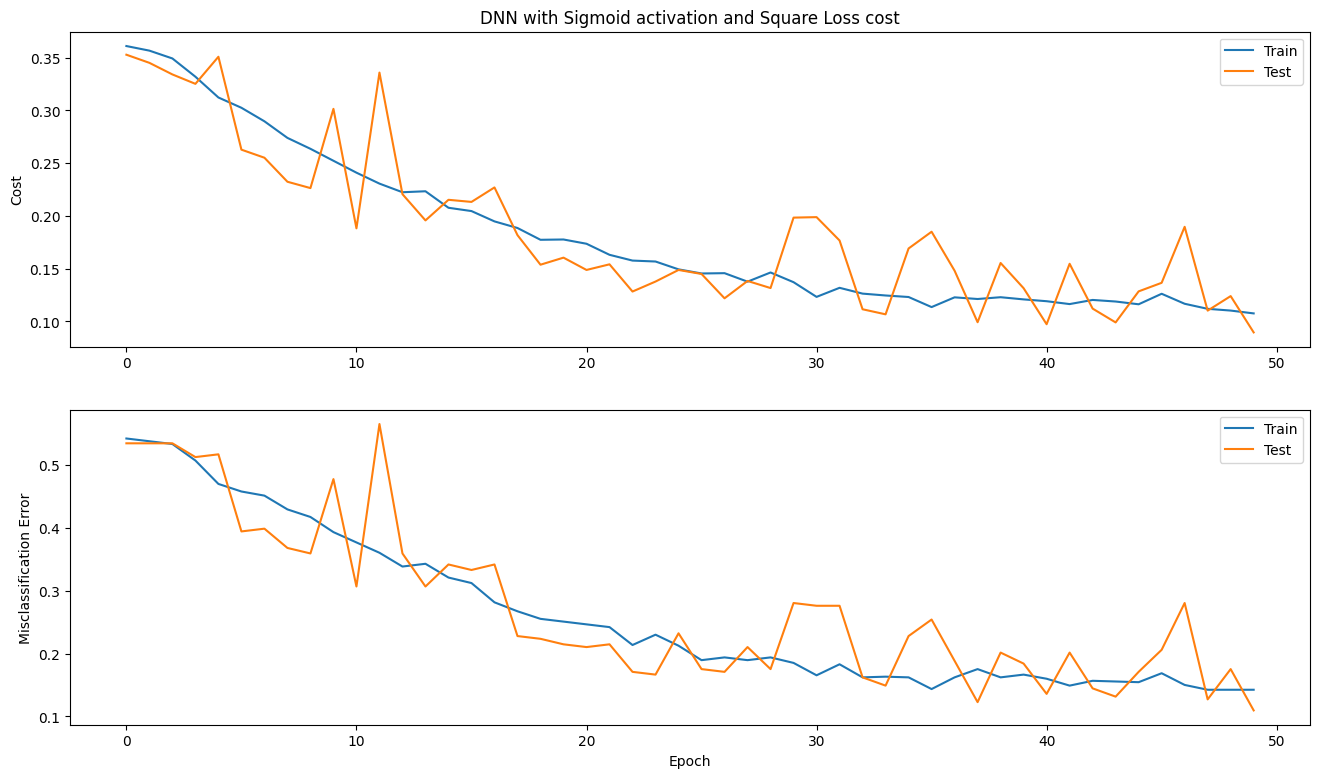

In [169]:
fig, axs = plt.subplots(2,1, figsize=(16,9))

plt.subplot(2,1,1)
plt.title("DNN with Sigmoid activation and Square Loss cost")
plt.ylabel('Cost')
plt.plot(epochs_span,cost_span_train_sig,cost_span_test_sig)
plt.legend(['Train', 'Test'])
plt.subplot(2,1,2)
plt.xlabel('Epoch')
plt.ylabel('Misclassification Error')
plt.plot(epochs_span,class_error_train_sig,class_error_test_sig)
plt.legend(['Train', 'Test'])
plt.show()

In [170]:
print("final cost of training:",cost_span_train_sig[epochs-1])
print("final classification error of training:",class_error_train_sig[epochs-1])
print("final cost of testing:",cost_span_test_sig[epochs-1])
print("final classification error of testing:",class_error_test_sig[epochs-1])

final cost of training: 0.1076266644905925
final classification error of training: 0.1425438596491228
final cost of testing: 0.08961514764516218
final classification error of testing: 0.10964912280701754


#### Solution

Using two layer DNN, with the first layer having 40 neurons and the second having 30 neurons, we got to a error rate of $\approx.11$ in 50 epochs and a constant learning rate of .1. Going to a higher epoch value seemed to increase the error rate, so <code>max_epoch=50</code> seemed ideal (at least for the tuning route I took). Doing more than 2 layers seemed to increase the error and cost, aas well as higher neuron counts. From what I did, $40 \rightarrow 30$ seemed best (or at least good enough)

Compared to the misclassification rate of the test set for the logistic regression (which got $\approx.14$), we can see that the DNN is slightly better with these settings.



---

### ReLU Activation with Squared Loss

Another popular choice of the activation function is relu function.

(a) Modify your code to use Relu function in these hidden nueron layer and sigmoid/softmax function in the output layer. You may try  1 hidden layer of 1024 neurons in this case.  i.e.,

- A fully connected (linear) layer with an input of the `n_features` and output of 1024.
- A ReLU layer
- A fully connected (linear) layer with an input of 1024 and output of `n_classes`.
- A softmax function.


(b) Compare the performance with Q2 and Q3.1.


In [171]:
def forward_prop_combo(x, params, activation=Relu, output=Sigmoid):
    """
    Does the forward propogation step of NN that can use separate activation
    functions for the hidden layers and the output layer.
    Inputs:
        x: training data
        params: Parameters as dictionary
    Outputs:
        A: Final layer output, \vec a^{(L)}(x)
        caches: intermediate values stored, everything before applying
        activation function (\vec a^{(l-1)}, \vec z^{(l)})
    """
    A = x # input to first layer i.e. training data
    caches = []
    L = len(params)//2
    for l in range(L):
        A_prev = A

        # Linear transformation
        Z = np.dot(params['W'+str(l+1)], A_prev) + params['b'+str(l+1)]

        # storing the both linear and activation cache
        cache = (A_prev, Z)
        caches.append(cache)

        # Apply activation on hidden layer and output on output layer
        if l!=L-1:
            A  = activation(Z)
        else:
            A  = output(Z)
    return A, caches

def backward_prop_combo(AL, Y, caches, params, loss_function=Square_loss, activation=Relu, output=Sigmoid):
    """
    Does the forward propogation step of NN that can use separate activation
    functions for the hidden layers and the output layer.
    Inputs:
        AL: Final layer output, \vec a^{(L)}(x^{(i)})
        Y: one hot vector of the label y^{(i)}
        caches: intermediate values stored, everything before applying
        activation function (\vec a^{(l-1)}, \vec z^{(l)}), l=1,2,\dots,L
        params: Parameters as dictionary, params[W1], \dots, params[WL],
        params[b1],\dots, params[bL]
        loss_function: choice of loss function (Square_loss or Logistic_loss)
        output: choice of output function (on first delta)
        activation: choice of activation function (on every other delta)
    Outputs:
        grads: gradients as dictionary, grads[W1], \dots, grads[WL],grads[b1],\dots, grads[bL]
    """
    grads = {}
    L = len(caches)
    AL1, ZL = caches[L-1]
    # initial delta
    delta_L = loss_function(AL, Y, derivative=True) * output(ZL, derivative=True)
    grads['db'+str(L)] = delta_L
    grads['dW'+str(L)] = np.array([delta_L]).T  @ np.array([AL1])
    delta_prev = delta_L
    # the rest of the deltas
    for l in reversed(range(L-1)):
        delta_curr  = delta_prev
        A_prev, Z_curr = caches[l]
        W_curr  = params['W'+str(l+2)]
        delta_prev = np.dot(W_curr.T, delta_curr) * activation(Z_curr, derivative=True)
        grads['db'+str(l+1)] = delta_prev
        grads['dW'+str(l+1)] = np.array([delta_prev]).T  @ np.array([A_prev])

    return grads

def train_NN_combo(Xtrain, Ytrain_vec, Xtest, Ytest_vec, epochs, layer_dim, learning_rate, cost_function=Square_loss, activation=Relu, output=Sigmoid):
    """
    specific NN that does the forward propogation using relu as the activation,
    then sigmoid for the output layer.
    """
    # Step 0: Initialization
    params = init_params(layer_dim)
    N      = Xtrain.shape[0]

    cost_span_train = np.zeros(epochs)
    class_error_train = np.zeros(epochs)
    cost_span_test = np.zeros(epochs)
    class_error_test = np.zeros(epochs)

    # Training the neural network
    arr = np.arange(N)
    for i in range(epochs):
        l_rate   = learning_rate[i]
        np.random.shuffle(arr)

        cost_i = 0
        class_error = 0

        for j in arr:
            # Step 1: forward propogation (with activation as Relu and output as Sigmoid)
            Y_hat, caches = forward_prop_combo(Xtrain[j], params, activation, output)
            cost_i += cost_function(Y_hat,Ytrain_vec[j])
            # Step 2: backward propogation
            grads  = backward_prop_combo(Y_hat, Ytrain_vec[j], caches, params, cost_function, activation, output)
            # Step 3 (optional for SGD): updating parameters
            params = update_parameters(params, grads, l_rate)
            if np.argmax(Y_hat) != np.argmax(Ytrain_vec[j]):
                class_error += 1

        # appending training data
        cost_span_train[i] = cost_i/N
        class_error_train[i] = class_error/N

        print('At epochs '+ str(i+1) + ', the cost is ' + str(cost_i/N))

        # reinit for testing data
        cost_i = 0
        class_error = 0

        # getting testing data
        for j in range(Xtest.shape[0]):
            Y_hat, caches = forward_prop_combo(Xtest[j], params, activation, output)
            cost_i += cost_function(Y_hat,Ytest_vec[j])
            if np.argmax(Y_hat) != np.argmax(Ytest_vec[j]):
                class_error += 1

        # appending testing data
        cost_span_test[i] = cost_i/Xtest.shape[0]
        class_error_test[i] = class_error/Xtest.shape[0]

    return params, cost_span_train, class_error_train, cost_span_test, class_error_test


In [172]:
# Q3.2

n,d = X_train.shape
n_classes = np.unique(y_train).shape[0]
onehot_y_train = onehot(y_train, n_classes)
onehot_y_test = onehot(y_test, n_classes)

# For this particular question, do not add more layers, as the above
# train_NN requires this "layer_dim" to have size = 3

layer_dim = [X_train.shape[1], 1024, n_classes]

epochs = 50
epochs_span = np.arange(epochs)
# constant learning rate
learning_rate = .1*np.ones(epochs)
cost_function = Square_loss

# train NN for Relu activation, Sigmoid output and Square Loss cost functions
params_relu, cost_span_train_relu, class_error_train_relu, cost_span_test_relu, class_error_test_relu = train_NN_combo(X_train, onehot_y_train, X_test, onehot_y_test, epochs, layer_dim, learning_rate, cost_function, activation=Relu, output=Sigmoid)


At epochs 1, the cost is 0.5026046688761254
At epochs 2, the cost is 0.37482394721603085
At epochs 3, the cost is 0.3502151443789121
At epochs 4, the cost is 0.33923146945033794
At epochs 5, the cost is 0.33749002285011226
At epochs 6, the cost is 0.32498003545197374
At epochs 7, the cost is 0.3177520034705299
At epochs 8, the cost is 0.318340596281635
At epochs 9, the cost is 0.31348177472962513
At epochs 10, the cost is 0.3050908613476839
At epochs 11, the cost is 0.2968516332959037
At epochs 12, the cost is 0.2876954898649454
At epochs 13, the cost is 0.2882485241007322
At epochs 14, the cost is 0.2791433351441614
At epochs 15, the cost is 0.26876087764474793
At epochs 16, the cost is 0.26266065549277623
At epochs 17, the cost is 0.26255864530147077
At epochs 18, the cost is 0.25157856433510883
At epochs 19, the cost is 0.2559470635348821
At epochs 20, the cost is 0.24246291023494823
At epochs 21, the cost is 0.24712554531813596
At epochs 22, the cost is 0.23317647330176738
At epoch

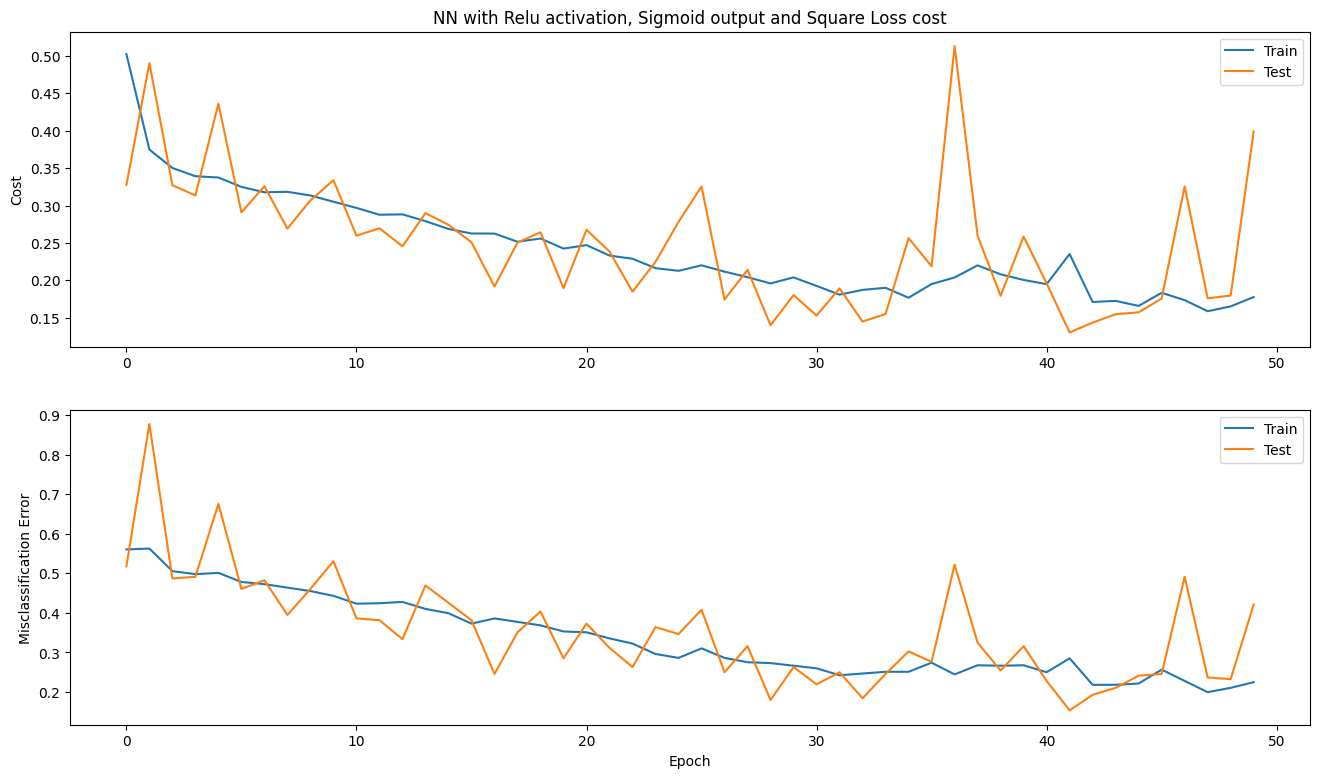

In [173]:
fig, axs = plt.subplots(2,1, figsize=(16,9))

plt.subplot(2,1,1)
plt.title("NN with Relu activation, Sigmoid output and Square Loss cost")
plt.ylabel('Cost')
plt.plot(epochs_span,cost_span_train_relu,cost_span_test_relu)
plt.legend(['Train', 'Test'])
plt.subplot(2,1,2)
plt.xlabel('Epoch')
plt.ylabel('Misclassification Error')
plt.plot(epochs_span,class_error_train_relu,class_error_test_relu)
plt.legend(['Train', 'Test'])
plt.show()

In [174]:
print("final cost of training:",cost_span_train_relu[epochs-1])
print("final classification error of training:",class_error_train_relu[epochs-1])
print("final cost of testing:",cost_span_test_relu[epochs-1])
print("final classification error of testing:",class_error_test_relu[epochs-1])

final cost of training: 0.17770862538472945
final classification error of training: 0.22478070175438597
final cost of testing: 0.39896751449547996
final classification error of testing: 0.42105263157894735


#### Solution

Compared to the other two models, this NN is much worse. It did eventually reach some kind on convergence around epoch 30, which is "more efficient" than the other two, the runtime was 30 seconds PER epoch, which is ridiculously high. After fiddling with the neuron count, the classification error was worse, so keeping neuron count high was best for the model. The testing data also seems to be much more sensitive to randomness, giving us a much less hugging plot when compared to the other models. That's not even taking into account that the final cost and misclassification rate for the NN is worse than the other two models.

Perhaps with some tuning, this could reach the level of one of the other two models, but without reducing the runtime, it's not really worth it.



---



---




### Logistic Loss (Optional)
(a) What about switching to logistic loss? Do you find it is nearly impossible to tune here due to the vanishing gradient and other errors/warnings?

(b) Please dig out the root cause and fix it! You should get similar performance as the square loss.

